# Detecção de marcações de esterilização em orelhas de gatos com YOLO11s

Este notebook reúne as etapas de organização dos dados, anotação, treinamento, avaliação e análise complementar desenvolvidas no TCC. O objetivo é localizar as orelhas visíveis nas fotografias e classificá-las em duas categorias:

- **`0 — orelha_marcada`:** orelha com corte de identificação (*ear-tipping*) ou tatuagem visível associada à esterilização;
- **`1 — orelha_normal`:** orelha sem uma dessas marcações visíveis.

A classificação se refere **à aparência da orelha na imagem**, não à condição clínica do animal. A ausência de marcação não comprova que o gato não foi esterilizado. Lesões, ocultações e imagens de baixa qualidade podem dificultar a identificação. Por esse motivo, as caixas de anotação abrangem a orelha inteira, e não apenas a região do corte ou da tatuagem.

O modelo principal é o **YOLO11s de detecção de objetos**, inicializado com os pesos `yolo11s.pt`. O notebook também contém análises de visão computacional, um experimento exploratório com V-JEPA 2 e testes locais voltados à portabilidade do modelo. Essas etapas têm objetivos diferentes e são identificadas separadamente ao longo do documento.

**Nota de reprodutibilidade.** Os experimentos apresentados neste notebook foram executados em ambiente local, utilizando um computador pessoal com sistema operacional Windows e ambiente Python configurado no Visual Studio Code. Os resultados e as saídas de execução foram preservados para documentar os procedimentos realizados, sem necessidade de repetir os treinamentos nesta versão. Para reproduzir os experimentos, é necessário verificar os caminhos dos arquivos, as versões das bibliotecas utilizadas e a disponibilidade dos modelos treinados e dos conjuntos de dados. Ressalta-se que a divisão dos dados foi realizada por imagem, sem garantia de independência entre indivíduos, o que deve ser considerado na interpretação dos resultados de validação.

## 1. Ambiente de execução

As bibliotecas necessárias são instaladas nas células seguintes. O notebook foi executado em ambientes Python no Windows, e algumas rotinas dependem de caminhos locais que precisam ser ajustados antes de uma nova execução. O uso de GPU depende da instalação do PyTorch e da disponibilidade de CUDA no ambiente ativo. Os resultados já registrados nas saídas das células foram mantidos.

In [1]:
%pip install -q ultralytics pyyaml pillow matplotlib pandas scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
%pip install pillow imagehash pillow-avif-plugin pillow-heif

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:
from pathlib import Path
from collections import Counter, defaultdict
import random
import shutil
import json
import csv

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw
import pandas as pd
import yaml
import torch
from ultralytics import YOLO
from sklearn.model_selection import GroupShuffleSplit


# 1. CONFIGURAÇÕES GERAIS

from pathlib import Path

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

BASE_DIR = Path.cwd()

ROOT = BASE_DIR / "Dataset"

# Classes do dataset
DIR_TATTOO = ROOT / "Castrado" / "Tattoo"
DIR_TIPPING = ROOT / "Castrado" / "Tipping"
DIR_NORMAL = ROOT / "Nao Castrado"

# Diretório de saída do YOLO
OUT = BASE_DIR / "dataset_yolo"

# Classes para o treinamento
CLASSES = ["orelha_marcada", "orelha_normal"]

# Extensões permitidas
EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

CLASS_DIRS = {
    "orelha_marcada": [DIR_TATTOO, DIR_TIPPING],
    "orelha_normal": [DIR_NORMAL]
}

for classe, diretorios in CLASS_DIRS.items():
    for diretorio in diretorios:
        imagens = (
            [p for p in diretorio.rglob("*")
             if p.suffix.lower() in EXTS]
            if diretorio.exists() else []
        )

        print(f"Classe: {classe}")
        print(f"Pasta: {diretorio}")
        print(f"Encontrada: {diretorio.exists()}")
        print(f"Quantidade de imagens: {len(imagens)}")
        

MODEL_NAME = 'yolo11s.pt'     # ou 'yolo11n.pt' para baseline
EPOCHS = 20
IMGSZ = 640                 # teste 960 se as orelhas forem pequenas na foto
BATCH = 8
DEVICE = 0 if torch.cuda.is_available() else 'cpu'

# CAMINHOS DAS IMAGENS E ANOTAÇÕES

RAW_IMAGES = ROOT

# Pasta contendo os arquivos TXT das anotações
RAW_LABELS = BASE_DIR / "anotacoes_orelhas"

if not RAW_IMAGES.is_dir():
    raise FileNotFoundError(
        f"Dataset não encontrado: {RAW_IMAGES.resolve()}"
    )

RAW_LABELS.mkdir(parents=True, exist_ok=True)

print("Dispositivo:", DEVICE)
print("Imagens em:", RAW_IMAGES.resolve())
print("Anotações em:", RAW_LABELS.resolve())

Classe: orelha_marcada
Pasta: c:\Users\barba\OneDrive\Documentos\TCC_limpo\Dataset\Castrado\Tattoo
Encontrada: True
Quantidade de imagens: 55
Classe: orelha_marcada
Pasta: c:\Users\barba\OneDrive\Documentos\TCC_limpo\Dataset\Castrado\Tipping
Encontrada: True
Quantidade de imagens: 194
Classe: orelha_normal
Pasta: c:\Users\barba\OneDrive\Documentos\TCC_limpo\Dataset\Nao Castrado
Encontrada: True
Quantidade de imagens: 200
Dispositivo: cpu
Imagens em: C:\Users\barba\OneDrive\Documentos\TCC_limpo\Dataset
Anotações em: C:\Users\barba\OneDrive\Documentos\TCC_limpo\anotacoes_orelhas


In [12]:

# Verificar se as fotos estão no padrão em todas as classes

from pathlib import Path
import re

BASE_DIR = Path.cwd()
DATASET_DIR = BASE_DIR / "Dataset"

EXTENSOES = {".jpg", ".jpeg", ".png", ".webp", ".bmp", ".tif", ".tiff"}

CLASSES = {
    "Castrado": re.compile(
        r"^(TIPPING|TATTOO)_\d{4}\.(jpg|jpeg|png|webp|bmp|tif|tiff)$",
        re.I
    ),
    "Nao Castrado": re.compile(
        r"^NORMAL_\d{4}\.(jpg|jpeg|png|webp|bmp|tif|tiff)$",
        re.I
    )
}

total_imagens = 0
total_corretos = 0
total_incorretos = 0

for classe, padrao in CLASSES.items():

    pasta = DATASET_DIR / classe

    print(f"CLASSE: {classe}")
    
    if not pasta.exists():
        print(f"Pasta não encontrada: {pasta}")
        continue

    imagens = sorted(
        p for p in pasta.rglob("*")
        if p.is_file() and p.suffix.lower() in EXTENSOES
    )

    corretos = [
        p for p in imagens
        if padrao.fullmatch(p.name)
    ]

    incorretos = [
        p for p in imagens
        if not padrao.fullmatch(p.name)
    ]

    total_imagens += len(imagens)
    total_corretos += len(corretos)
    total_incorretos += len(incorretos)

    print(f"Total de imagens: {len(imagens)}")
    print(f"Nomes no padrão: {len(corretos)}")
    print(f"Nomes fora do padrão: {len(incorretos)}")

    if incorretos:
        print("\nArquivos fora do padrão:")
        for arquivo in incorretos:
            print(f" - {arquivo.relative_to(DATASET_DIR)}")
    else:
        print("\nTodos os nomes estão corretos!")

print("RESUMO GERAL DO DATASET")
print(f"Total de imagens: {total_imagens}")
print(f"Nomes no padrão: {total_corretos}")
print(f"Nomes fora do padrão: {total_incorretos}")


CLASSE: Castrado
Total de imagens: 249
Nomes no padrão: 249
Nomes fora do padrão: 0

Todos os nomes estão corretos!
CLASSE: Nao Castrado
Total de imagens: 200
Nomes no padrão: 200
Nomes fora do padrão: 0

Todos os nomes estão corretos!
RESUMO GERAL DO DATASET
Total de imagens: 449
Nomes no padrão: 449
Nomes fora do padrão: 0


In [ ]:
#Auditar imagens
from pathlib import Path
from collections import Counter
import re

BASE_DIR = Path(r"C:\Users\barba\OneDrive\Documentos\TCC")
PASTA = BASE_DIR / "Dataset" / "Castrado"

EXTS = {".jpg", ".jpeg", ".png", ".webp", ".bmp", ".avif", ".tif", ".tiff", ".heic", ".heif"}
TOTAL_ESPERADO = 210

if not PASTA.is_dir():
    raise FileNotFoundError(f"Pasta não encontrada: {PASTA}")

imagens = sorted(
    [p for p in PASTA.rglob("*")
     if p.is_file() and p.suffix.lower() in EXTS],
    key=lambda p: str(p).lower()
)

padrao = re.compile(r"^(TIPPING|TATTOO)_(\d{4})$", re.I)

categorias = {"TIPPING": [], "TATTOO": []}
incorretas = []

for p in imagens:
    resultado = padrao.fullmatch(p.stem)

    if resultado:
        tipo = resultado.group(1).upper()
        numero = int(resultado.group(2))
        categorias[tipo].append((numero, p))
    else:
        incorretas.append(p)

print("Auditoria do dataset Castrado")
print("Total de fotografias:", len(imagens))
print("Total esperado:", TOTAL_ESPERADO)
print("Nomes no padrão:", len(imagens) - len(incorretas))
print("Nomes fora do padrão:", len(incorretas))

for tipo, arquivos in categorias.items():
    numeros = [numero for numero, p in arquivos]
    contagem = Counter(numeros)

    duplicados = sorted(
        numero for numero, qtd in contagem.items() if qtd > 1
    )

    if numeros:
        inicio = min(numeros)
        fim = max(numeros)
        faltantes = sorted(set(range(inicio, fim + 1)) - set(numeros))
    else:
        inicio = fim = None
        faltantes = []

    print(f"\n{tipo}")
    print("Total de fotografias:", len(arquivos))
    print("Intervalo:", f"{inicio:04d} a {fim:04d}" if numeros else "Vazio")
    print("Números ausentes:", faltantes)
    print("Números duplicados:", duplicados)

    if duplicados:
        print("Arquivos com numeração duplicada:")
        for numero, p in arquivos:
            if numero in duplicados:
                print(p.relative_to(PASTA))

print("\nFotografias fora do padrão:")
for p in incorretas:
    print(p.relative_to(PASTA))

print("\nFormatos encontrados:")
formatos = Counter(p.suffix.lower() for p in imagens)

for formato, quantidade in sorted(formatos.items()):
    print(f"{formato}: {quantidade}")

print("\nResumo")
print("Castrado:", len(imagens))
print("Tipping:", len(categorias["TIPPING"]))
print("Tattoo:", len(categorias["TATTOO"]))

if len(imagens) == TOTAL_ESPERADO:
    print("Quantidade total correta.")
else:
    print("Quantidade total diferente da esperada.")

Auditoria do dataset Castrado
Total de fotografias: 255
Total esperado: 210
Nomes no padrão: 255
Nomes fora do padrão: 0

TIPPING
Total de fotografias: 200
Intervalo: 0001 a 0200
Números ausentes: []
Números duplicados: []

TATTOO
Total de fotografias: 55
Intervalo: 0001 a 0055
Números ausentes: []
Números duplicados: []

Fotografias fora do padrão:

Formatos encontrados:
.avif: 6
.jpeg: 24
.jpg: 123
.png: 34
.webp: 68

Resumo
Castrado: 255
Tipping: 200
Tattoo: 55
Quantidade total diferente da esperada.


## 2. Organização e anotação do conjunto de dados

O YOLO11s foi utilizado como detector de objetos. Portanto, cada orelha identificável precisa ter uma caixa delimitadora (*bounding box*) e um rótulo de classe. A organização das imagens em pastas, isoladamente, não fornece ao detector a posição das orelhas.

### 2.1 Estrutura dos arquivos

As fotografias de entrada foram separadas inicialmente em três grupos: **Tattoo**, com exemplos de tatuagem na orelha; **Tipping**, com exemplos de corte de identificação; e **Nao Castrado**, utilizado como nome da pasta que reúne fotografias sem marcação visível. Esse último nome identifica apenas a origem dos arquivos e **não deve ser interpretado como comprovação do estado de esterilização**. É importante ressaltar que para a classe castrados foram considerados dois padrões de sinalização de esterilização, justificando-se, assim, o uso de dois grupos para a mesma classe *Castrado*.

Os arquivos de anotação ficam em `anotacoes_orelhas/`, preservando a correspondência com as imagens em `Dataset/`. O processamento gera posteriormente um diretório `dataset_yolo*/`, contendo as partições e o arquivo `data.yaml`.

Os nomes de subpastas e de arquivos apresentam variantes históricas, especialmente `Tattoo`, `Tatoo`, `TATOO` e `TATTOO`. Para não quebrar a correspondência com os arquivos existentes, os caminhos devem ser conferidos no sistema de arquivos antes de qualquer renomeação. A célula de padronização realiza essa tarefa de forma controlada.

### 2.2 Classes utilizadas

Apesar dos três grupos de origem, o detector trabalha com duas classes: `0 — orelha_marcada` (corte ou tatuagem) e `1 — orelha_normal` (sem marcação visível). Uma fotografia pode conter mais de uma caixa de anotação, inclusive com classes diferentes, quando isso é compatível com as orelhas visíveis.

### 2.3 Ferramenta de anotação

Foi desenvolvida uma interface gráfica em Python, com Tkinter e Pillow, para apoiar a revisão manual das imagens. Nela é possível abrir fotografias, desenhar e ajustar caixas delimitadoras, escolher a classe de cada orelha e salvar os arquivos `.txt` no formato YOLO.

A ferramenta foi criada porque parte do conjunto de dados precisava de revisão, principalmente quando as caixas não incluíam a orelha inteira ou quando a orientação da imagem dificultava a marcação. A navegação entre fotografias e a possibilidade de corrigir anotações tornam essa tarefa mais prática do que editar os arquivos de texto individualmente.

A interface também pode ser utilizada por colaboradores que não trabalham diretamente com programação. Ainda assim, a identificação de casos ambíguos exige revisão humana; a ferramenta apenas organiza o processo de anotação.

In [6]:
'''Anotador local YOLO (PT/EN) para orelhas de gatos.

Dependencia: pip install pillow
Execute em TCC: python anotador_orelhas.py
Estrutura: Dataset/**/imagem.jpg -> anotacoes_orelhas/**/imagem.txt
'''
from pathlib import Path
import tkinter as tk
from tkinter import ttk
from PIL import Image, ImageTk

BASE_DIR = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()

IMAGES_DIR = BASE_DIR / "Dataset"
LABELS_DIR = BASE_DIR / "anotacoes_orelhas"

EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

print("Projeto:", BASE_DIR)
print("Imagens:", IMAGES_DIR)
print("Anotações:", LABELS_DIR)


IMAGES_DIR = BASE_DIR / "Dataset"
LABELS_DIR = BASE_DIR / "anotacoes_orelhas"
EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
CLASSES = ("orelha_marcada", "orelha_normal")
CLASS_COLORS = ("#EC407A", "#7465D9")
PINK_BG = "#FFE9F3"
PINK_PANEL = "#FFD4E8"
PINK_LIGHT = "#FFF5FA"
PINK_BUTTON = "#F5A5CE"
PINK_TEXT = "#782A57"
PINK_ACCENT = "#CA3E85"


class EarAnnotator:
    def __init__(self, root):
        self.root = root
        root.title("🐱💗 Anotador de Orelhas / Cat Ear Annotator 💗🐱")
        root.configure(bg=PINK_BG)
        root.geometry("1200x840")
        root.minsize(700, 500)
        self.images = sorted(p for p in IMAGES_DIR.rglob("*") if p.is_file() and p.suffix.lower() in EXTS)
        if not self.images:
            self.popup("Sem fotos / No images", f"Nenhuma imagem em / No images in:\n{IMAGES_DIR}")
            return
        self.index = 0
        self.selected = tk.IntVar(value=0)
        self.boxes = []
        self.dirty = False
        self.original = None
        self.tk_photo = None
        self.base_fit = 1.0
        self.zoom = 1.0
        self.pan_x = 0.0
        self.pan_y = 0.0
        self.drag_start = None
        self.drag_now = None
        self.pan_start = None
        self.canvas_w = 800
        self.canvas_h = 480
        self._resize_job = None
        self.make_ui()
        self.bind_keys()
        self.load_image()

    def button(self, parent, text, action, strong=False):
        return tk.Button(parent, text=text, command=action, bg=PINK_ACCENT if strong else PINK_BUTTON,
                         fg="white" if strong else PINK_TEXT, activebackground="#E879B1",
                         activeforeground="white", relief="flat", cursor="hand2", bd=0,
                         padx=10, pady=7, font=("Segoe UI", 10, "bold"))

    def make_ui(self):
        header = tk.Frame(self.root, bg=PINK_BG)
        header.pack(fill="x", padx=10, pady=(7, 1))
        tk.Label(header, text="🐾💖 Orelhas de Gatos / Cat Ears 💖🐾", bg=PINK_BG,
                 fg=PINK_ACCENT, font=("Segoe UI", 17, "bold")).pack()
        tk.Label(header, text="Marque a orelha inteira / Draw a box around the whole ear",
                 bg=PINK_BG, fg=PINK_TEXT, font=("Segoe UI", 10)).pack()

        toolbar = tk.Frame(self.root, bg=PINK_LIGHT)
        toolbar.pack(fill="x", padx=10, pady=5)
        radio = tk.Frame(toolbar, bg=PINK_LIGHT)
        radio.pack(fill="x", padx=5, pady=(5, 0))
        for idx, text in enumerate(("🎀 0 — Marcada / Marked (corte ou tatuagem / tip or tattoo)",
                                    "🌸 1 — Normal / Unmarked")):
            tk.Radiobutton(radio, text=text, value=idx, variable=self.selected,
                           bg=PINK_LIGHT, fg=CLASS_COLORS[idx], activebackground=PINK_LIGHT,
                           selectcolor=PINK_BG, font=("Segoe UI", 10, "bold")).pack(side="left", padx=8)

        actions = tk.Frame(toolbar, bg=PINK_LIGHT)
        actions.pack(fill="x", padx=5, pady=5)
        items = [
            ("↶ Desfazer / Undo (Z)", self.undo),
            ("💾 Salvar / Save (S)", self.save),
            ("🐾 Sem orelha / No ear", self.save_no_ear),
            ("◀ Anterior / Previous", self.prev_image),
            ("Próxima / Next ▶", self.next_image),
            ("− Zoom", lambda: self.change_zoom(1 / 1.25)),
            ("+ Zoom", lambda: self.change_zoom(1.25)),
            ("⤢ Ajustar / Fit (F)", self.fit_image),
        ]
        for i, (name, fn) in enumerate(items):
            self.button(actions, name, fn, strong=(i == 1)).pack(side="left", padx=3, pady=2)

        # Busca rápida: nome, prefixo ou caminho relativo.
        search_frame = tk.Frame(self.root, bg=PINK_PANEL)
        search_frame.pack(fill="x", padx=10, pady=(0, 5))
        tk.Label(search_frame, text="🔎 Buscar foto / Find image:",
                 bg=PINK_PANEL, fg=PINK_TEXT, font=("Segoe UI", 10, "bold")
                 ).pack(side="left", padx=(10, 6), pady=7)
        self.search_var = tk.StringVar()
        self.search_entry = tk.Entry(search_frame, textvariable=self.search_var,
                                     bg=PINK_LIGHT, fg=PINK_TEXT, insertbackground=PINK_TEXT,
                                     font=("Segoe UI", 11), relief="flat")
        self.search_entry.pack(side="left", fill="x", expand=True, ipady=5, padx=4)
        self.search_entry.bind("<Return>", lambda e: self.search_images())
        self.button(search_frame, "🔍 Procurar / Search", self.search_images,
                    strong=True).pack(side="left", padx=7)

        self.status = tk.Label(self.root, bg=PINK_PANEL, fg=PINK_TEXT, anchor="w",
                               justify="left", font=("Segoe UI", 10), padx=12, pady=5)
        self.status.pack(fill="x", padx=10, pady=(0, 5))

        self.canvas = tk.Canvas(self.root, bg="#FFF8FC", bd=0, highlightthickness=2,
                                highlightbackground="#EEA8CF", cursor="crosshair")
        self.canvas.pack(fill="both", expand=True, padx=10, pady=(0, 10))
        self.canvas.bind("<Configure>", self.on_resize)
        self.canvas.bind("<ButtonPress-1>", self.mouse_down)
        self.canvas.bind("<B1-Motion>", self.mouse_move)
        self.canvas.bind("<ButtonRelease-1>", self.mouse_up)
        self.canvas.bind("<ButtonPress-3>", self.pan_down)
        self.canvas.bind("<B3-Motion>", self.pan_move)
        self.canvas.bind("<ButtonRelease-3>", lambda e: setattr(self, "pan_start", None))
        self.canvas.bind("<MouseWheel>", self.wheel)
        self.canvas.bind("<Button-4>", lambda e: self.change_zoom(1.2, e.x, e.y))
        self.canvas.bind("<Button-5>", lambda e: self.change_zoom(1 / 1.2, e.x, e.y))

    def bind_keys(self):
        self.root.bind("0", lambda e: self.selected.set(0))
        self.root.bind("1", lambda e: self.selected.set(1))
        self.root.bind("s", lambda e: self.save())
        self.root.bind("z", lambda e: self.undo())
        self.root.bind("f", lambda e: self.fit_image())
        self.root.bind("<Right>", lambda e: self.next_image())
        self.root.bind("<Left>", lambda e: self.prev_image())
        self.root.protocol("WM_DELETE_WINDOW", self.close)

    @property
    def current(self):
        return self.images[self.index]

    @property
    def label_path(self):
        return LABELS_DIR / self.current.relative_to(IMAGES_DIR).with_suffix(".txt")

    def popup(self, title, msg):
        """Diálogo próprio com fundo rosa, inclusive para confirmação de salvamento."""
        dialog = tk.Toplevel(self.root)
        dialog.title(title)
        dialog.configure(bg=PINK_BG)
        dialog.resizable(False, False)
        dialog.transient(self.root)
        tk.Label(dialog, text="🐱 💗 🐾", bg=PINK_BG, fg=PINK_ACCENT,
                 font=("Segoe UI", 22, "bold")).pack(pady=(15, 3))
        tk.Label(dialog, text=msg, bg=PINK_BG, fg=PINK_TEXT, font=("Segoe UI", 11),
                 wraplength=410, justify="center", padx=22).pack(pady=8)
        self.button(dialog, "OK 💗", dialog.destroy, strong=True).pack(pady=(5, 18))
        dialog.update_idletasks()
        x = self.root.winfo_rootx() + (self.root.winfo_width() - dialog.winfo_width()) // 2
        y = self.root.winfo_rooty() + (self.root.winfo_height() - dialog.winfo_height()) // 2
        dialog.geometry(f"+{max(0,x)}+{max(0,y)}")
        dialog.grab_set()
        dialog.wait_window()

    def question(self):
        result = {"value": None}
        dialog = tk.Toplevel(self.root)
        dialog.title("🐱 Alterações / Unsaved changes")
        dialog.configure(bg=PINK_BG)
        dialog.resizable(False, False)
        dialog.transient(self.root)
        tk.Label(dialog, text="💗 Salvar antes de continuar?\nSave before continuing?",
                 bg=PINK_BG, fg=PINK_TEXT, font=("Segoe UI", 12, "bold"),
                 padx=30, pady=20).pack()
        row = tk.Frame(dialog, bg=PINK_BG)
        row.pack(padx=14, pady=(0, 15))
        def done(v):
            result["value"] = v
            dialog.destroy()
        for label, val in (("Salvar / Save", True), ("Descartar / Discard", False), ("Cancelar / Cancel", None)):
            self.button(row, label, lambda v=val: done(v)).pack(side="left", padx=4)
        dialog.protocol("WM_DELETE_WINDOW", lambda: done(None))
        dialog.grab_set()
        dialog.wait_window()
        return result["value"]

    def load_image(self):
        self.boxes = []
        self.dirty = False
        with Image.open(self.current) as im:
            # Manter dimensões e coordenadas originais para compatibilidade YOLO.
            self.original = im.convert("RGB")
        if self.label_path.exists():
            for line in self.label_path.read_text(encoding="utf-8").splitlines():
                fields = line.split()
                if len(fields) != 5:
                    continue
                try:
                    cls = int(fields[0])
                    coords = tuple(map(float, fields[1:]))
                    if cls in (0, 1):
                        self.boxes.append((cls, *coords))
                except ValueError:
                    pass
        self.root.update_idletasks()
        self.canvas_w = max(100, self.canvas.winfo_width())
        self.canvas_h = max(100, self.canvas.winfo_height())
        self.fit_image()

    def on_resize(self, event):
        self.canvas_w = max(1, event.width)
        self.canvas_h = max(1, event.height)
        if self._resize_job is not None:
            self.root.after_cancel(self._resize_job)
        self._resize_job = self.root.after(100, self.fit_image)

    def fit_image(self):
        if self.original is None:
            return
        w, h = self.original.size
        self.base_fit = min((self.canvas_w - 20) / w, (self.canvas_h - 20) / h)
        self.zoom = 1.0
        self.pan_x = (self.canvas_w - w * self.base_fit) / 2
        self.pan_y = (self.canvas_h - h * self.base_fit) / 2
        self.render()

    def scale(self):
        return self.base_fit * self.zoom

    def image_to_canvas(self, x, y):
        s = self.scale()
        return x * s + self.pan_x, y * s + self.pan_y

    def canvas_to_image(self, x, y):
        s = self.scale()
        return (x - self.pan_x) / s, (y - self.pan_y) / s

    def on_image(self, x, y):
        ix, iy = self.canvas_to_image(x, y)
        w, h = self.original.size
        return 0 <= ix <= w and 0 <= iy <= h

    def clamp_image(self, x, y):
        ix, iy = self.canvas_to_image(x, y)
        w, h = self.original.size
        return max(0, min(w, ix)), max(0, min(h, iy))

    def render(self):
        if self.original is None:
            return
        self.canvas.delete("all")
        s = self.scale()
        w, h = self.original.size
        rw, rh = max(1, round(w * s)), max(1, round(h * s))
        # Recorta a imagem para a área visível ANTES de converter em PhotoImage.
        # Isso evita alocar imagens enormes quando o zoom é elevado.
        vx1 = max(0, (0 - self.pan_x) / s)
        vy1 = max(0, (0 - self.pan_y) / s)
        vx2 = min(w, (self.canvas_w - self.pan_x) / s)
        vy2 = min(h, (self.canvas_h - self.pan_y) / s)
        if vx2 > vx1 and vy2 > vy1:
            left, top = int(vx1), int(vy1)
            right, bottom = min(w, int(vx2) + 2), min(h, int(vy2) + 2)
            crop = self.original.crop((left, top, right, bottom))
            sw = max(1, round((right - left) * s))
            sh = max(1, round((bottom - top) * s))
            self.tk_photo = ImageTk.PhotoImage(crop.resize((sw, sh), Image.Resampling.LANCZOS))
            ox, oy = self.image_to_canvas(left, top)
            self.canvas.create_image(ox, oy, anchor="nw", image=self.tk_photo)
        else:
            self.tk_photo = None
        for cls, xc, yc, bw, bh in self.boxes:
            x1, y1 = self.image_to_canvas((xc - bw / 2) * w, (yc - bh / 2) * h)
            x2, y2 = self.image_to_canvas((xc + bw / 2) * w, (yc + bh / 2) * h)
            self.canvas.create_rectangle(x1, y1, x2, y2, outline=CLASS_COLORS[cls], width=3)
            self.canvas.create_text(x1 + 4, max(12, y1 - 12), anchor="w",
                                    text=f"{cls}: {CLASSES[cls]}", fill=CLASS_COLORS[cls],
                                    font=("Segoe UI", 10, "bold"))
        if self.drag_start is not None and self.drag_now is not None:
            x1, y1 = self.image_to_canvas(*self.drag_start)
            x2, y2 = self.image_to_canvas(*self.drag_now)
            self.canvas.create_rectangle(x1, y1, x2, y2, outline=CLASS_COLORS[self.selected.get()],
                                         width=2, dash=(5, 3))
        self.status.configure(text=(
            f"📷 Foto / Image: {self.index + 1}/{len(self.images)}  |  {self.current.relative_to(IMAGES_DIR)}\n"
            f"🎀 Caixas / Boxes: {len(self.boxes)}  |  Zoom: {self.zoom:.1f}×  |  "
            f"{'⚠️ Não salvo / Unsaved' if self.dirty else '✅ Salvo / Saved'}\n"
            "🐾 Esquerdo: desenhar / Left: draw  •  Direito: mover / Right: pan  •  "
            "Roda: zoom / Wheel: zoom  •  F: ajustar / fit"
        ))

    def change_zoom(self, factor, x=None, y=None):
        if self.original is None:
            return
        if x is None:
            x = self.canvas_w / 2
        if y is None:
            y = self.canvas_h / 2
        old = self.zoom
        new = max(1.0, min(12.0, old * factor))
        if new == old:
            return
        ix, iy = self.canvas_to_image(x, y)
        self.zoom = new
        self.pan_x = x - ix * self.scale()
        self.pan_y = y - iy * self.scale()
        self.render()

    def wheel(self, event):
        self.change_zoom(1.2 if event.delta > 0 else 1 / 1.2, event.x, event.y)

    def mouse_down(self, event):
        if self.on_image(event.x, event.y):
            self.drag_start = self.clamp_image(event.x, event.y)
            self.drag_now = self.drag_start

    def mouse_move(self, event):
        if self.drag_start is not None:
            self.drag_now = self.clamp_image(event.x, event.y)
            self.render()

    def mouse_up(self, event):
        if self.drag_start is None:
            return
        xa, ya = self.drag_start
        xb, yb = self.clamp_image(event.x, event.y)
        self.drag_start = None
        self.drag_now = None
        x1, x2 = sorted((xa, xb))
        y1, y2 = sorted((ya, yb))
        if x2 - x1 >= 3 and y2 - y1 >= 3:
            w, h = self.original.size
            self.boxes.append((self.selected.get(), (x1 + x2) / (2 * w),
                               (y1 + y2) / (2 * h), (x2 - x1) / w, (y2 - y1) / h))
            self.dirty = True
        self.render()

    def pan_down(self, event):
        self.pan_start = (event.x, event.y, self.pan_x, self.pan_y)

    def pan_move(self, event):
        if self.pan_start:
            sx, sy, ox, oy = self.pan_start
            self.pan_x = ox + event.x - sx
            self.pan_y = oy + event.y - sy
            self.render()

    def undo(self):
        if self.boxes:
            self.boxes.pop()
            self.dirty = True
            self.render()

    def save(self, show_popup=True):
        self.label_path.parent.mkdir(parents=True, exist_ok=True)
        text = "".join(f"{cls} {xc:.6f} {yc:.6f} {bw:.6f} {bh:.6f}\n" for cls, xc, yc, bw, bh in self.boxes)
        self.label_path.write_text(text, encoding="utf-8")
        self.dirty = False
        self.render()
        if show_popup:
            self.popup("💗 Salvo / Saved", "🐱 Anotações salvas com sucesso!\nAnnotations saved successfully! 💖")

    def save_no_ear(self):
        if self.boxes:
            self.popup("Atenção / Attention", "Esta imagem tem caixas. Use Desfazer antes de marcar sem orelha.\nThis image has boxes. Undo before marking no ear.")
            return
        self.save(show_popup=True)

    def confirm_change(self):
        if not self.dirty:
            return True
        result = self.question()
        if result is None:
            return False
        if result:
            self.save(show_popup=False)
        return True

    def next_image(self):
        if self.index < len(self.images) - 1 and self.confirm_change():
            self.index += 1
            self.load_image()

    def prev_image(self):
        if self.index > 0 and self.confirm_change():
            self.index -= 1
            self.load_image()

    def go_to_image(self, target):
        """Ir até uma foto sem perder alterações ainda não salvas."""
        if target == self.index:
            return True
        if not self.confirm_change():
            return False
        self.index = target
        self.load_image()
        return True

    def search_images(self):
        """Pesquisar por nome, número, prefixo ou caminho da fotografia."""
        query = self.search_var.get().strip().casefold()
        if not query:
            self.popup("🔎 Busca / Search", "Digite um nome, número ou caminho.\nEnter a filename, number or path.")
            self.search_entry.focus_set()
            return
        matches = [(i, p.relative_to(IMAGES_DIR).as_posix())
                   for i, p in enumerate(self.images)
                   if query in p.relative_to(IMAGES_DIR).as_posix().casefold()]
        if not matches:
            self.popup("😿 Sem resultados / No matches",
                       f"Nenhuma fotografia encontrada para: {query}\nNo matching images found.")
            return
        if len(matches) == 1:
            self.go_to_image(matches[0][0])
            return

        dialog = tk.Toplevel(self.root)
        dialog.title("🐱🔎 Resultados / Search results")
        dialog.configure(bg=PINK_BG)
        dialog.geometry("780x440")
        dialog.minsize(500, 280)
        dialog.transient(self.root)
        tk.Label(dialog, text=f"💗 {len(matches)} fotos encontradas / images found",
                 bg=PINK_BG, fg=PINK_ACCENT,
                 font=("Segoe UI", 13, "bold")).pack(padx=12, pady=(12, 6))
        content = tk.Frame(dialog, bg=PINK_BG)
        content.pack(fill="both", expand=True, padx=12, pady=5)
        scroll = tk.Scrollbar(content)
        scroll.pack(side="right", fill="y")
        result_list = tk.Listbox(content, bg=PINK_LIGHT, fg=PINK_TEXT,
                                 selectbackground=PINK_ACCENT, selectforeground="white",
                                 font=("Consolas", 10), relief="flat",
                                 activestyle="none", yscrollcommand=scroll.set)
        result_list.pack(side="left", fill="both", expand=True)
        scroll.config(command=result_list.yview)
        for i, path in matches:
            result_list.insert("end", f"{i + 1:04d}  {path}")
        result_list.selection_set(0)
        result_list.activate(0)

        def open_selected(event=None):
            selection = result_list.curselection()
            if not selection:
                return
            target_idx = matches[selection[0]][0]
            if self.go_to_image(target_idx):
                dialog.destroy()

        result_list.bind("<Double-Button-1>", open_selected)
        result_list.bind("<Return>", open_selected)
        self.button(dialog, "🐾 Abrir imagem / Open image", open_selected,
                    strong=True).pack(pady=(5, 12))
        dialog.protocol("WM_DELETE_WINDOW", dialog.destroy)
        dialog.grab_set()
        result_list.focus_set()

    def close(self):
        if self.confirm_change():
            self.root.destroy()


if __name__ == "__main__":
    root = tk.Tk()
    EarAnnotator(root)
    root.mainloop()


Projeto: c:\Users\barba\OneDrive\Documentos\TCC_limpo
Imagens: c:\Users\barba\OneDrive\Documentos\TCC_limpo\Dataset
Anotações: c:\Users\barba\OneDrive\Documentos\TCC_limpo\anotacoes_orelhas


## 3. Auditoria das imagens e das anotações

Antes de preparar os conjuntos de treinamento, validação e teste, foram verificadas a padronização dos nomes, a integridade dos arquivos de imagem e a correspondência entre fotografias e anotações. As rotinas abaixo também auxiliam a localizar inconsistências de extensão, caixas inválidas e arquivos que precisam de revisão.

Na saída registrada da validação, foram contabilizadas **449 fotografias**, todas com arquivos de anotação válidos, e **932 caixas**: **259** da classe `orelha_marcada` e **673** da classe `orelha_normal`. Esses valores correspondem à execução preservada no notebook, não a uma nova auditoria feita nesta revisão.

A distribuição mostra um desbalanceamento entre as classes em número de orelhas. Esse aspecto deve ser considerado na interpretação das métricas por classe e em eventuais experimentos de balanceamento.

In [ ]:
# Padronizar dataset tattoo e tipping

from pathlib import Path
from datetime import datetime
from collections import Counter
import shutil
import csv
import uuid

BASE_DIR = Path(
    r"C:\Users\barba\OneDrive\Documentos\TCC_limpo"
)

DATASET = BASE_DIR / "Dataset" / "Castrado"
LABELS = BASE_DIR / "anotacoes_orelhas" / "Castrado"

EXTS = {
    ".jpg", ".jpeg", ".png",
    ".webp", ".bmp", ".tif", ".tiff"
}

# Primeiro simular; depois alterar para True
APLICAR = False

CATEGORIAS = {
    "Tattoo": "TATTOO",
    "Tipping": "TIPPING"
}


# 3.1- Construir plano de renomeação

operacoes = []
ambiguidades = []

for pasta_nome, prefixo in CATEGORIAS.items():

    pasta = DATASET / pasta_nome
    pasta_labels = LABELS / pasta_nome

    if not pasta.is_dir():
        raise FileNotFoundError(
            f"Pasta não encontrada: {pasta}"
        )

    imagens = sorted(
        (
            p for p in pasta.iterdir()
            if p.is_file() and p.suffix.lower() in EXTS
        ),
        key=lambda p: (p.stem.casefold(), p.suffix.casefold())
    )

    contagem = Counter(p.stem.casefold() for p in imagens)

    print(f"\n{pasta_nome}: {len(imagens)} imagens")

    for numero, imagem in enumerate(imagens, start=1):

        novo_base = f"{prefixo}_{numero:04d}"
        novo_nome = novo_base + imagem.suffix.lower()

        rotulo = pasta_labels / f"{imagem.stem}.txt"

        # Se duas imagens possuem o mesmo nome-base,
        # não sabemos a qual delas o TXT pertence.
        ambiguo = contagem[imagem.stem.casefold()] > 1

        if ambiguo:
            ambiguidades.append(imagem)

        operacoes.append({
            "categoria": pasta_nome,
            "imagem": imagem,
            "rotulo": rotulo,
            "novo_base": novo_base,
            "novo_nome": novo_nome,
            "rotulo_ambiguo": ambiguo,
            "rotulo_existe": rotulo.is_file()
        })

# 3.2- Mostrar relatório

print("AUDITORIA DE RENOMEAÇÃO")

print("Total de imagens:", len(operacoes))

print(
    "Com TXT inequívoco:",
    sum(
        item["rotulo_existe"]
        and not item["rotulo_ambiguo"]
        for item in operacoes
    )
)

print(
    "Sem TXT:",
    sum(
        not item["rotulo_existe"]
        for item in operacoes
    )
)

print("Imagens com nome-base ambíguo:", len(ambiguidades))

print("\nExemplos de renomeação:")

for item in operacoes[:15]:
    print(
        item["categoria"],
        item["imagem"].name,
        "→",
        item["novo_nome"]
    )

if ambiguidades:
    print("\nATENÇÃO: nomes-base repetidos")
    for imagem in ambiguidades[:20]:
        print(" -", imagem)


#3.3- Salvar plano CSV (inclusive na simulação)

MAPA = BASE_DIR / "plano_renomeacao_castrados.csv"

with MAPA.open(
    "w", encoding="utf-8-sig", newline=""
) as f:

    writer = csv.writer(f)

    writer.writerow([
        "categoria",
        "imagem_original",
        "imagem_nova",
        "txt_original",
        "txt_novo",
        "status"
    ])

    for item in operacoes:

        if item["rotulo_ambiguo"]:
            status = "REVISAR_TXT_AMBIGUO"
        elif item["rotulo_existe"]:
            status = "TXT_IDENTIFICADO"
        else:
            status = "SEM_TXT"

        writer.writerow([
            item["categoria"],
            item["imagem"].name,
            item["novo_nome"],
            item["rotulo"].name,
            item["novo_base"] + ".txt",
            status
        ])

print("\nRelatório:", MAPA)

# 3.4- Aplicar renomeação

if not APLICAR:
    print("\nMODO SIMULAÇÃO: nenhum arquivo renomeado.")
    print("Confira o relatório e altere APLICAR=True.")

else:

    # Não alterar arquivos se houver ambiguidade
    if ambiguidades:
        raise ValueError(
            "Existem imagens com nomes-base repetidos. "
            "Resolva as ambiguidades antes de aplicar."
        )

    # Evitar colisões de nomes no destino
    for item in operacoes:
        destino = (
            item["imagem"].parent / item["novo_nome"]
        )
        if destino.exists() and destino not in {
            op["imagem"] for op in operacoes
        }:
            raise FileExistsError(
                f"Destino ocupado: {destino}"
            )

    # Criar backup
    backup = BASE_DIR / (
        "backup_castrados_" +
        datetime.now().strftime("%Y%m%d_%H%M%S_%f")
    )

    shutil.copytree(DATASET, backup / "Dataset_Castrado")

    if LABELS.exists():
        shutil.copytree(
            LABELS,
            backup / "Anotacoes_Castrado"
        )

    print("\nBackup criado:", backup)

    for item in operacoes:
        item["temporario"] = (
            item["imagem"].parent /
            f"__tmp_{uuid.uuid4().hex}{item['imagem'].suffix}"
        )
        item["imagem"].rename(item["temporario"])

    for item in operacoes:
        destino = (
            item["imagem"].parent / item["novo_nome"]
        )
        item["temporario"].rename(destino)

    # Renomear TXT com nomes temporários para
    # evitar colisões entre nomes antigos e novos
    for item in operacoes:

        if not item["rotulo_existe"]:
            continue

        item["txt_temporario"] = (
            item["rotulo"].parent /
            f"__tmp_{uuid.uuid4().hex}.txt"
        )

        item["rotulo"].rename(
            item["txt_temporario"]
        )

    for item in operacoes:

        if not item["rotulo_existe"]:
            continue

        destino_txt = (
            item["rotulo"].parent /
            f"{item['novo_base']}.txt"
        )

        if destino_txt.exists():
            raise FileExistsError(
                f"TXT de destino ocupado: {destino_txt}"
            )

        item["txt_temporario"].rename(destino_txt)

    print("\nRenomeação concluída!")
    print("Backup:", backup)
    print("Relatório:", MAPA)



Tattoo: 55 imagens

Tipping: 194 imagens
AUDITORIA DE RENOMEAÇÃO
Total de imagens: 249
Com TXT inequívoco: 249
Sem TXT: 0
Imagens com nome-base ambíguo: 0

Exemplos de renomeação:
Tattoo TATTOO_0001.jpg → TATTOO_0001.jpg
Tattoo TATTOO_0002.jpg → TATTOO_0002.jpg
Tattoo TATTOO_0003.jpg → TATTOO_0003.jpg
Tattoo TATTOO_0004.jpg → TATTOO_0004.jpg
Tattoo TATTOO_0005.jpg → TATTOO_0005.jpg
Tattoo TATTOO_0006.jpg → TATTOO_0006.jpg
Tattoo TATTOO_0007.jpg → TATTOO_0007.jpg
Tattoo TATTOO_0008.jpg → TATTOO_0008.jpg
Tattoo TATTOO_0009.jpg → TATTOO_0009.jpg
Tattoo TATTOO_0010.jpeg → TATTOO_0010.jpeg
Tattoo TATTOO_0011.jpg → TATTOO_0011.jpg
Tattoo TATTOO_0012.jpg → TATTOO_0012.jpg
Tattoo TATTOO_0013.png → TATTOO_0013.png
Tattoo TATTOO_0014.jpg → TATTOO_0014.jpg
Tattoo TATTOO_0015.jpeg → TATTOO_0015.jpeg

Relatório: C:\Users\barba\OneDrive\Documentos\TCC\plano_renomeacao_castrados.csv

MODO SIMULAÇÃO: nenhum arquivo renomeado.
Confira o relatório e altere APLICAR=True.


In [ ]:
#Validar dataset anotado

from collections import Counter
from PIL import Image
import numpy as np

images = sorted(
    p for p in RAW_IMAGES.rglob("*")
    if p.is_file() and p.suffix.lower() in EXTS
)

if not images:
    raise FileNotFoundError(
        f"Nenhuma imagem encontrada em {RAW_IMAGES}"
    )

records = []
errors = []
pendentes = []
sem_orelhas = []

for img in images:

    relative = img.relative_to(RAW_IMAGES)
    label = (RAW_LABELS / relative).with_suffix(".txt")

    # Imagens ainda não anotadas
    if not label.is_file():
        pendentes.append(str(relative))
        continue

    try:
        with Image.open(img) as im:
            w, h = im.size
            im.verify()

        rows = []

        for i, line in enumerate(
            label.read_text(encoding="utf-8").splitlines(), 1
        ):

            if not line.strip():
                continue

            fields = line.split()

            if len(fields) != 5:
                raise ValueError(
                    f"Linha {i}: esperados 5 campos"
                )

            valores = list(map(float, fields))

            cls_f, xc, yc, bw, bh = valores

            if not all(np.isfinite(valores)):
                raise ValueError(
                    f"Linha {i}: valores NaN ou Inf"
                )

            if cls_f not in (0.0, 1.0):
                raise ValueError(
                    f"Linha {i}: classe inválida"
                )

            if not (
                0 <= xc <= 1
                and 0 <= yc <= 1
                and 0 < bw <= 1
                and 0 < bh <= 1
            ):
                raise ValueError(
                    f"Linha {i}: coordenadas inválidas"
                )

            tol = 1e-6

            if not (
                xc - bw / 2 >= -tol
                and xc + bw / 2 <= 1 + tol
                and yc - bh / 2 >= -tol
                and yc + bh / 2 <= 1 + tol
            ):
                raise ValueError(
                    f"Linha {i}: caixa fora da imagem"
                )

            rows.append([
                int(cls_f), xc, yc, bw, bh
            ])

        if not rows:
            sem_orelhas.append(str(relative))

        records.append({
            "image": img,
            "relative": relative,
            "label": label,
            "w": w,
            "h": h,
            "boxes": rows
        })

    except Exception as exc:
        errors.append(f"{relative}: {exc}")

counts = Counter(
    b[0] for r in records for b in r["boxes"]
)

# Relatório de anotações

print("RELATÓRIO DE ANOTAÇÕES DO TCC")

print(f"Total de imagens: {len(images)}")
print(f"Imagens revisadas: {len(records)}")
print(f"Pendentes: {len(pendentes)}")
print(f"Anotações inválidas: {len(errors)}")
print(f"Revisadas sem orelhas: {len(sem_orelhas)}")

print("\nCaixas por classe:")

for i, classe in enumerate(CLASSES):
    print(f"  {classe}: {counts[i]}")

print("\nPrimeiras imagens pendentes:")

for nome in pendentes[:15]:
    print(" -", nome)

print("\nErros nas anotações:")

for erro in errors[:15]:
    print(" -", erro)


# Ver se pode treinar

if errors:
    raise ValueError(
        f"Existem {len(errors)} anotações inválidas."
    )

if not records:
    raise ValueError(
        "Nenhuma imagem anotada foi encontrada."
    )

if not all(counts[i] > 0 for i in range(2)):
    raise ValueError(
        "As duas classes precisam ter exemplos anotados."
    )

print("\nValidação dos arquivos existentes concluída!")

if pendentes:
    print(
        f"Existem {len(pendentes)} imagens pendentes."
    )
    print(
        "Elas não estão incluídas em records e, "
        "portanto, não serão usadas no treinamento."
    )
else:
    print("Todas as imagens foram revisadas!")


RELATÓRIO DE ANOTAÇÕES DO TCC
Total de imagens: 449
Imagens revisadas: 449
Pendentes: 0
Anotações inválidas: 0
Revisadas sem orelhas: 0

Caixas por classe:
  Castrado: 259
  Nao Castrado: 673

Primeiras imagens pendentes:

Erros nas anotações:

Validação dos arquivos existentes concluída!
Todas as imagens foram revisadas!


## 4. Revisão visual das caixas

Além da validação dos arquivos de texto, é necessário examinar visualmente as anotações. A célula seguinte sobrepõe as caixas às fotografias para identificar problemas de enquadramento, cortes que deixam parte da orelha de fora, rótulos incompatíveis e imagens que precisem de correção de orientação. Uma anotação numericamente válida ainda pode estar visualmente incorreta.

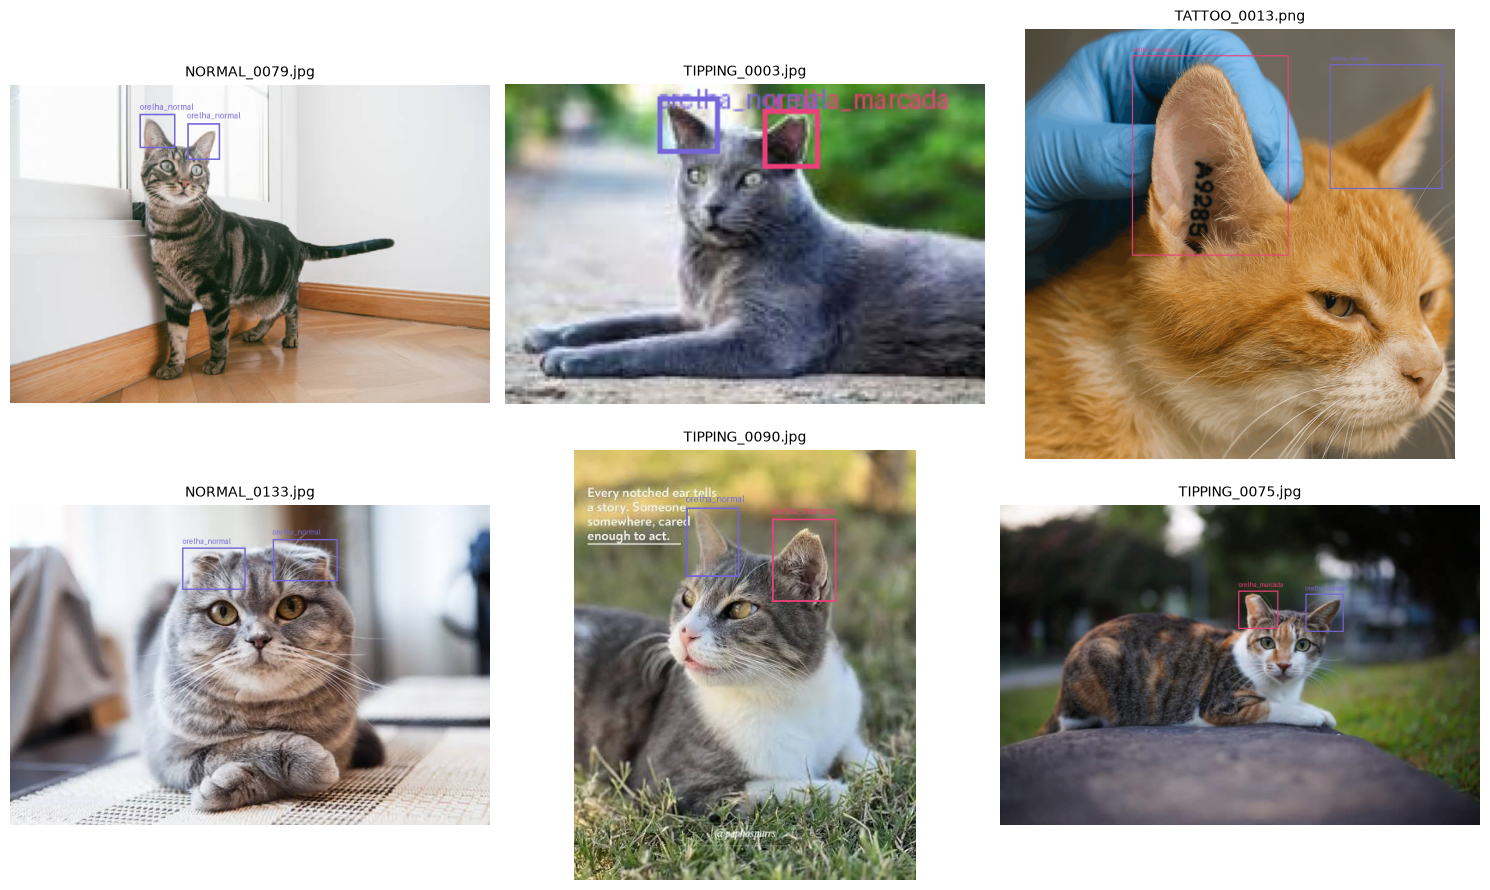

In [ ]:
#4- Visualizar anotaçães do dataset yolo

import random
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw

# Configuração das classes
CLASSES = ["orelha_marcada", "orelha_normal"]

# Cores das caixas
COLORS = ["#EC407A", "#7465D9"]

if "records" not in globals() or not records:
    raise ValueError(
        "Nenhuma anotação validada encontrada. "
        "Execute primeiro a célula de validação."
    )

def show_annotated(record, ax):

    # Abrir fotografia
    with Image.open(record["image"]) as original:
        im = original.convert("RGB")

    draw = ImageDraw.Draw(im)
    w, h = im.size

    # Desenhar bounding boxes
    for cls, xc, yc, bw, bh in record["boxes"]:

        x1 = (xc - bw / 2) * w
        y1 = (yc - bh / 2) * h
        x2 = (xc + bw / 2) * w
        y2 = (yc + bh / 2) * h

        draw.rectangle(
            [x1, y1, x2, y2],
            outline=COLORS[cls],
            width=max(2, w // 300)
        )

        draw.text(
            (x1, max(0, y1 - 16)),
            CLASSES[cls],
            fill=COLORS[cls]
        )

    ax.imshow(im)
    ax.set_title(
        record["image"].name[:40],
        fontsize=10
    )
    ax.axis("off")


# Selecionar até seis fotografias
random.seed(42)

sample = random.sample(
    records,
    min(6, len(records))
)

# Preparar visualização
fig, axes = plt.subplots(
    2, 3,
    figsize=(15, 9)
)

for ax in axes.flat:
    ax.axis("off")

for ax, record in zip(axes.flat, sample):
    show_annotated(record, ax)

plt.tight_layout()
plt.show()


## 5. Divisão dos dados em treinamento, validação e teste

A divisão foi configurada para aproximadamente **70% de treinamento, 15% de validação e 15% de teste**, com semente aleatória 42. O código prevê agrupamento por indivíduo quando há identificadores confiáveis das fotografias, mas a execução registrada **não encontrou identificações de gatos**.

Por isso, foi utilizada **estratificação por fotografia**, produzindo 314 imagens de treinamento, 67 de validação e 68 de teste. Essa divisão preserva aproximadamente as proporções pretendidas, mas **não garante independência entre indivíduos**: fotografias do mesmo gato podem estar em partições distintas.

Essa é uma limitação metodológica relevante, pois imagens semelhantes de um mesmo indivíduo podem levar a uma estimativa otimista do desempenho. Para uma avaliação posterior, recomenda-se identificar os gatos, reconstruir as partições por indivíduo e repetir os treinamentos com os mesmos critérios de comparação. Mostrando-se assim, que o trabalho facilita na triagem de indivíduos castrados ou não, mas não substitui a supervisão humana.

In [ ]:
# 5- DIVISÃO DO DATASET (70% / 15% / 15%)
#
# Objetivo:
# Separar as fotografias em treinamento, validação
# e teste, mantendo as duas classes:
#
# 0 = orelha_marcada
# 1 = orelha_normal
#
# Modos disponíveis:
# - automatico: escolhe conforme identificação disponível
# - individuo: separa por gato (mais rigoroso)
# - estratificado: separa por fotografia
#
# ATENÇÃO:
# A divisão estratificada não garante que diferentes
# imagens do mesmo gato fiquem em conjuntos separados.

from pathlib import Path
from collections import Counter
from sklearn.model_selection import (
    train_test_split,
    GroupShuffleSplit
)
import pandas as pd

SEED = 42
MODO_DIVISAO = "automatico"

# 5.1- Verificar os registros do dataset

if "records" not in globals() or not records:
    raise ValueError(
        "Execute primeiro a validação do dataset "
        "para criar a variável 'records'."
    )

# Copiar registros sem alterar os originais
registros = []

for r in records:
    novo = dict(r)

    caminho = Path(novo["image"])
    novo["relative"] = caminho.relative_to(RAW_IMAGES)

    registros.append(novo)

chaves = [
    r["relative"].as_posix()
    for r in registros
]

if len(set(chaves)) != len(chaves):
    raise ValueError(
        "Existem fotografias repetidas nos registros."
    )

print("Total de fotografias:", len(registros))


# 5.2- Carregar cadastro de identificação dos gatos

ARQUIVO_GATOS = BASE_DIR / "identificacao_gatos.csv"

if not ARQUIVO_GATOS.exists():

    pd.DataFrame({
        "relative_path": sorted(chaves),
        "cat_id": ""
    }).to_csv(
        ARQUIVO_GATOS,
        index=False,
        encoding="utf-8-sig"
    )

    print(
        "Cadastro de identificação criado:",
        ARQUIVO_GATOS
    )

# Ler o CSV, aceitando vírgula ou ponto e vírgula
cadastro = pd.read_csv(
    ARQUIVO_GATOS,
    sep=None,
    engine="python",
    dtype=str,
    encoding="utf-8-sig"
).fillna("")

# Remover caracteres de codificação e espaços
cadastro.columns = (
    cadastro.columns
    .str.replace("\ufeff", "", regex=False)
    .str.strip()
)

# Compatibilidade com os dois formatos
cadastro = cadastro.rename(columns={
    "relative_path": "imagem_relativa",
    "cat_id": "gato_id"
})

colunas_necessarias = {
    "imagem_relativa",
    "gato_id"
}

if not colunas_necessarias.issubset(cadastro.columns):
    raise ValueError(
        "O CSV deve conter as colunas "
        "'relative_path' e 'cat_id', ou "
        "'imagem_relativa' e 'gato_id'. "
        f"Encontradas: {cadastro.columns.tolist()}"
    )

cadastro["imagem_relativa"] = (
    cadastro["imagem_relativa"]
    .str.strip()
    .str.replace("\\", "/", regex=False)
)

cadastro["gato_id"] = (
    cadastro["gato_id"]
    .str.strip()
)

if cadastro["imagem_relativa"].duplicated().any():
    raise ValueError(
        "Existem imagens duplicadas no cadastro."
    )

identidades = dict(zip(
    cadastro["imagem_relativa"],
    cadastro["gato_id"]
))

identificados = [
    ch for ch in chaves
    if identidades.get(ch, "")
]

nao_identificados = [
    ch for ch in chaves
    if not identidades.get(ch, "")
]

print("\nIdentificação dos indivíduos:")
print("Fotografias identificadas:", len(identificados))
print("Fotografias sem identificação:", len(nao_identificados))
print(
    "Gatos distintos identificados:",
    len(set(
        identidades[ch]
        for ch in identificados
    ))
)

# 5.3- Selecionar o método de divisão


identificacao_completa = (
    len(nao_identificados) == 0
    and len(set(
        identidades[ch]
        for ch in chaves
    )) >= 3
)

if MODO_DIVISAO == "automatico":

    if identificacao_completa:
        metodo = "individuo"
    else:
        metodo = "estratificado"

elif MODO_DIVISAO in ("individuo", "estratificado"):
    metodo = MODO_DIVISAO

else:
    raise ValueError(
        "MODO_DIVISAO deve ser 'automatico', "
        "'individuo' ou 'estratificado'."
    )

print("\nMétodo selecionado:", metodo)


# 5.4- Divisão por indivíduo

if metodo == "individuo":

    if not identificacao_completa:
        raise ValueError(
            "Para dividir por indivíduo, todas as "
            "fotografias precisam possuir gato_id "
            "e deve haver pelo menos 3 gatos distintos."
        )

    grupos = [
        identidades[ch]
        for ch in chaves
    ]

    gss = GroupShuffleSplit(
        n_splits=1,
        test_size=0.30,
        random_state=SEED
    )

    idx_treino, idx_temp = next(
        gss.split(
            registros,
            groups=grupos
        )
    )

    temp = [
        registros[i]
        for i in idx_temp
    ]

    grupos_temp = [
        grupos[i]
        for i in idx_temp
    ]

    gss_temp = GroupShuffleSplit(
        n_splits=1,
        test_size=0.50,
        random_state=SEED
    )

    idx_val, idx_teste = next(
        gss_temp.split(
            temp,
            groups=grupos_temp
        )
    )

    splits = {
        "train": [
            registros[i]
            for i in idx_treino
        ],
        "val": [
            temp[i]
            for i in idx_val
        ],
        "test": [
            temp[i]
            for i in idx_teste
        ]
    }

    # Verificar se há indivíduos compartilhados
    ids_split = {}

    for nome, itens in splits.items():

        ids_split[nome] = {
            identidades[r["relative"].as_posix()]
            for r in itens
        }

    assert ids_split["train"].isdisjoint(
        ids_split["val"]
    )

    assert ids_split["train"].isdisjoint(
        ids_split["test"]
    )

    assert ids_split["val"].isdisjoint(
        ids_split["test"]
    )

    print(
        "Nenhum gato compartilhado entre os conjuntos."
    )

# 5.5- Divisão estratificada por fotografia

else:

    # Classificação auxiliar para estratificação.
    # Não altera as classes YOLO das anotações.
    def categoria_fotografia(registro):

        classes = {
            int(box[0])
            for box in registro["boxes"]
        }

        if classes == {0}:
            return "somente_marcada"

        elif classes == {1}:
            return "somente_normal"

        elif classes == {0, 1}:
            return "ambas"

        else:
            return "sem_anotacao"

    categorias = [
        categoria_fotografia(r)
        for r in registros
    ]

    def estratificacao_valida(labels):

        contagem = Counter(labels)

        return (
            len(contagem) > 0
            and min(contagem.values()) >= 2
        )

    # Primeiro: 70% treino, 30% temporário
    estratos = (
        categorias
        if estratificacao_valida(categorias)
        else None
    )

    treino, temp = train_test_split(
        registros,
        test_size=0.30,
        random_state=SEED,
        stratify=estratos
    )

    # Segundo: dividir temporário em 15% e 15%
    categorias_temp = [
        categoria_fotografia(r)
        for r in temp
    ]

    estratos_temp = (
        categorias_temp
        if estratificacao_valida(categorias_temp)
        else None
    )

    val, teste = train_test_split(
        temp,
        test_size=0.50,
        random_state=SEED,
        stratify=estratos_temp
    )

    splits = {
        "train": treino,
        "val": val,
        "test": teste
    }

    print(
        "Divisão estratificada por fotografia realizada."
    )

    print(
        "ATENÇÃO: não foi possível garantir "
        "independência entre indivíduos."
    )

# 5.6- Conferir a distribuição das classes


print("RESULTADO DA DIVISÃO DO DATASET")

total = len(registros)

for nome, itens in splits.items():

    contagem = Counter(
        int(box[0])
        for r in itens
        for box in r["boxes"]
    )

    quantidade = len(itens)
    percentual = 100 * quantidade / total

    print(f"\nConjunto: {nome}")
    print(f"Fotografias: {quantidade} ({percentual:.1f}%)")
    print(f"Orelhas marcadas: {contagem[0]}")
    print(f"Orelhas normais: {contagem[1]}")

    if not itens:
        raise ValueError(
            f"O conjunto {nome} está vazio."
        )

    if contagem[0] == 0 or contagem[1] == 0:
        raise ValueError(
            f"O conjunto {nome} não possui "
            "anotações das duas classes. "
            "Revise a distribuição antes de treinar."
        )

# Conferir se todas as fotografias foram utilizadas
chaves_splits = [
    r["relative"].as_posix()
    for itens in splits.values()
    for r in itens
]

assert len(chaves_splits) == len(chaves)
assert set(chaves_splits) == set(chaves)
assert len(set(chaves_splits)) == len(chaves_splits)


# 5.7- Registrar informações experimentais

resumo_divisao = {
    "seed": SEED,
    "metodo": metodo,
    "total_fotografias": total,
    "train": len(splits["train"]),
    "val": len(splits["val"]),
    "test": len(splits["test"]),
    "independencia_individuos_garantida": (
        metodo == "individuo"
    )
}

print("\n" + "=" * 55)
print("RESUMO")
print("=" * 55)

for chave, valor in resumo_divisao.items():
    print(f"{chave}: {valor}")

print("\nSeção 5 concluída com sucesso!")

Total de fotografias: 449

Identificação dos indivíduos:
Fotografias identificadas: 0
Fotografias sem identificação: 449
Gatos distintos identificados: 0

Método selecionado: estratificado
Divisão estratificada por fotografia realizada.
ATENÇÃO: não foi possível garantir independência entre indivíduos.
RESULTADO DA DIVISÃO DO DATASET

Conjunto: train
Fotografias: 314 (69.9%)
Orelhas marcadas: 182
Orelhas normais: 462

Conjunto: val
Fotografias: 67 (14.9%)
Orelhas marcadas: 37
Orelhas normais: 104

Conjunto: test
Fotografias: 68 (15.1%)
Orelhas marcadas: 40
Orelhas normais: 107

RESUMO
seed: 42
metodo: estratificado
total_fotografias: 449
train: 314
val: 67
test: 68
independencia_individuos_garantida: False

Seção 5 concluída com sucesso!


## 6. Preparação do dataset no formato YOLO

A etapa seguinte copia as imagens e suas anotações para os diretórios `images/train`, `images/val`, `images/test` e os diretórios correspondentes de `labels`. Também gera o arquivo `data.yaml`, que define os caminhos e as duas classes. As verificações subsequentes procuram arquivos de imagem problemáticos antes do treinamento.

In [ ]:

#6- Preparar dataset yolo e gerar data.yml sem repetir pastas que já existem

from pathlib import Path
from datetime import datetime
import shutil
import yaml

# 6.1- Config


BASE_DIR = Path(
    r"C:\Users\barba\OneDrive\Documentos\TCC_limpo"
)

CLASSES = [
    "orelha_marcada",
    "orelha_normal"
]

if "splits" not in globals():
    raise ValueError(
        "Execute primeiro a etapa 5."
    )


# 6.2-Verificar arquivos origianis 
problemas = []

for split, rows in splits.items():

    for r in rows:

        imagem = Path(r["image"])
        label = Path(r["label"])

        if not imagem.is_file():
            problemas.append(
                f"Imagem ausente: {imagem}"
            )

        if not label.is_file():
            problemas.append(
                f"Anotação ausente: {label}"
            )

if problemas:

    print("Problemas encontrados:")

    for problema in problemas[:30]:
        print("-", problema)

    raise ValueError(
        f"Existem {len(problemas)} arquivos ausentes. "
        "Execute novamente as etapas 3 e 5 "
        "após corrigir as correspondências."
    )


# 6.3- DEFINIR NOVO DIRETÓRIO

DATA_HORA = datetime.now().strftime( #facilita na rastreabealidade de experimentos de treinamento
    "%Y%m%d_%H%M%S_%f"
)

OUT = BASE_DIR / f"dataset_yolo_{DATA_HORA}"

if OUT.exists():
    raise FileExistsError(
        f"Diretório já existe: {OUT}"
    )


# 6.4-  PLANEJAR NOMES DE DESTINO
plano = []

for split, rows in splits.items():

    nomes = set()

    for r in rows:

        relative = Path(r["relative"])

        nome_base = "__".join(
            relative.with_suffix("").parts
        )

        chave = nome_base.casefold()

        if chave in nomes:
            raise ValueError(
                f"Nome-base duplicado em {split}: "
                f"{nome_base}. Revise a correspondência "
                "entre imagens e anotações."
            )

        nomes.add(chave)

        plano.append({
            "split": split,
            "record": r,
            "nome_base": nome_base
        })


# 6.5- Criar diretórios


for split in ["train", "val", "test"]:

    for kind in ["images", "labels"]:

        pasta = OUT / kind / split

        pasta.mkdir(
            parents=True,
            exist_ok=True
        )

# 6.6- Copiar imagens e anotações


for item in plano:

    split = item["split"]
    r = item["record"]
    nome_base = item["nome_base"]

    extensao = Path(
        r["image"]
    ).suffix.lower()

    destino_imagem = (
        OUT / "images" / split /
        f"{nome_base}{extensao}"
    )

    destino_label = (
        OUT / "labels" / split /
        f"{nome_base}.txt"
    )

    shutil.copy2(
        r["image"],
        destino_imagem
    )

    shutil.copy2(
        r["label"],
        destino_label
    )

# 6.7- Gerar Data.yaml


config = {
    "path": OUT.resolve().as_posix(),
    "train": "images/train",
    "val": "images/val",
    "test": "images/test",
    "nc": 2,
    "names": {
        0: CLASSES[0],
        1: CLASSES[1]
    }
}

yaml_path = OUT / "data.yaml"

yaml_path.write_text(
    yaml.safe_dump(
        config,
        allow_unicode=True,
        sort_keys=False
    ),
    encoding="utf-8"
)

# 6.8- Ver resultado 

print("DATASET YOLO PREPARADO")

for split in ["train", "val", "test"]:

    pasta_imagens = OUT / "images" / split
    pasta_labels = OUT / "labels" / split

    imagens = list(pasta_imagens.iterdir())
    labels = list(pasta_labels.iterdir())

    esperado = len(splits[split])

    print(f"\n{split.upper()}")
    print(f"Imagens: {len(imagens)}")
    print(f"Anotações: {len(labels)}")
    print(f"Esperado: {esperado}")

    if (
        len(imagens) != esperado
        or len(labels) != esperado
    ):
        raise ValueError(
            f"Quantidade incorreta em {split}"
        )

print("\nArquivo data.yaml:")
print(yaml_path.resolve())

print("\nConteúdo:")
print(yaml_path.read_text(encoding="utf-8"))

print("\nDataset pronto para treinamento!")

DATASET YOLO PREPARADO

TRAIN
Imagens: 314
Anotações: 314
Esperado: 314

VAL
Imagens: 67
Anotações: 67
Esperado: 67

TEST
Imagens: 68
Anotações: 68
Esperado: 68

Arquivo data.yaml:
C:\Users\barba\OneDrive\Documentos\TCC_limpo\dataset_yolo_20261103_151141_523409\data.yaml

Conteúdo:
path: C:/Users/barba/OneDrive/Documentos/TCC_limpo/dataset_yolo_20261103_151141_523409
train: images/train
val: images/val
test: images/test
nc: 2
names:
  0: orelha_marcada
  1: orelha_normal


Dataset pronto para treinamento!


In [20]:

from pathlib import Path

# Diretório principal do TCC
BASE_DIR = Path(r"C:\Users\barba\OneDrive\Documentos\TCC_limpo")

# Localizar todos os datasets YOLO gerados
datasets = sorted(
    BASE_DIR.glob("dataset_yolo*/data.yaml"),
    key=lambda p: p.stat().st_mtime,
    reverse=True
)

if not datasets:
    raise FileNotFoundError(
        f"Nenhum dataset YOLO encontrado em {BASE_DIR}"
    )

# Selecionar o dataset mais recente
yaml_path = datasets[0].resolve()
DATASET_DIR = yaml_path.parent

print("DATASET SELECIONADO AUTOMATICAMENTE")
print("Dataset:", DATASET_DIR)
print("Arquivo YAML:", yaml_path)

# Verificar as pastas
for split in ["train", "val", "test"]:
    pasta = DATASET_DIR / "images" / split
    print(f"{split}: {'OK' if pasta.exists() else 'NÃO ENCONTRADA'}")


DATASET SELECIONADO AUTOMATICAMENTE
Dataset: C:\Users\barba\OneDrive\Documentos\TCC_limpo\dataset_yolo_20261103_151141_523409
Arquivo YAML: C:\Users\barba\OneDrive\Documentos\TCC_limpo\dataset_yolo_20261103_151141_523409\data.yaml
train: OK
val: OK
test: OK


In [23]:
from pathlib import Path
from PIL import Image

EXTENSOES = {
    ".jpg", ".jpeg", ".png",
    ".webp", ".bmp", ".tif", ".tiff"
}

problemas = []
total = 0

print("AUDITORIA DE INTEGRIDADE DO DATASET YOLO")
print("Dataset:", DATASET_DIR)

for split in ["train", "val", "test"]:

    pasta = DATASET_DIR / "images" / split

    imagens = sorted(
        p for p in pasta.rglob("*")
        if p.is_file() and p.suffix.lower() in EXTENSOES
    )

    print(f"\n{split.upper()}: {len(imagens)} imagens")

    for imagem in imagens:
        total += 1

        try:
            with Image.open(imagem) as img:
                img.verify()

            with Image.open(imagem) as img:
                img.load()

        except Exception as erro:
            problemas.append((split, imagem, str(erro)))


print("RESULTADO FINAL")

print("Total de imagens:", total)
print("Imagens com problemas:", len(problemas))

for split, imagem, erro in problemas:
    print(f"\n[{split}] {imagem.name}")
    print("Caminho:", imagem)
    print("Erro:", erro)

# Verificar especificamente a imagem que causou o erro
imagem_erro = (
    DATASET_DIR
    / "images"
    / "train"
    / "Nao Castrado__NORMAL_0065.jpg" #caso que deu problemas recorrentes, mudar para outro caso se necessário
)

print("\nVERIFICAÇÃO DA IMAGEM ANTERIORMENTE REPORTADA")
print("Existe:", imagem_erro.is_file())
print("Caminho:", imagem_erro)


AUDITORIA DE INTEGRIDADE DO DATASET YOLO
Dataset: C:\Users\barba\OneDrive\Documentos\TCC_limpo\dataset_yolo_20261103_151141_523409

TRAIN: 314 imagens

VAL: 67 imagens

TEST: 68 imagens
RESULTADO FINAL
Total de imagens: 449
Imagens com problemas: 0

VERIFICAÇÃO DA IMAGEM ANTERIORMENTE REPORTADA
Existe: True
Caminho: C:\Users\barba\OneDrive\Documentos\TCC_limpo\dataset_yolo_20261103_151141_523409\images\train\Nao Castrado__NORMAL_0065.jpg


In [24]:

from pathlib import Path
from ultralytics.utils.patches import imread
from PIL import Image
import shutil
import cv2

BASE_DIR = Path(r"C:\Users\barba\OneDrive\Documentos\TCC_limpo")

datasets = sorted(
    BASE_DIR.glob("dataset_yolo*/data.yaml"),
    key=lambda p: p.stat().st_mtime,
    reverse=True
)

if not datasets:
    raise FileNotFoundError("Nenhum dataset YOLO encontrado.")

ORIGEM = datasets[0].parent.resolve()

# Copiar para fora do OneDrive
DATASET_DIR = Path(r"C:\TCC_treinamento") / ORIGEM.name

if not DATASET_DIR.exists():
    shutil.copytree(
        ORIGEM,
        DATASET_DIR,
        ignore=shutil.ignore_patterns("*.cache")
    )
else:
    print("Cópia local já existente:", DATASET_DIR)

print("Dataset local:", DATASET_DIR)

EXTENSOES = {
    ".jpg", ".jpeg", ".png",
    ".webp", ".bmp", ".tif", ".tiff"
}

falhas = []
total = 0

for split in ["train", "val", "test"]:
    pasta = DATASET_DIR / "images" / split

    for arquivo in sorted(pasta.rglob("*")):
        if arquivo.suffix.lower() not in EXTENSOES:
            continue

        total += 1

        try:
            imagem = imread(str(arquivo), flags=cv2.IMREAD_COLOR)

            if imagem is None:
                falhas.append(arquivo)

        except Exception as erro:
            print("Erro de leitura:", arquivo.name, repr(erro))
            falhas.append(arquivo)


print("RESULTADO DA VERIFICAÇÃO")
print("Imagens verificadas:", total)
print("Imagens com erro:", len(falhas))

for arquivo in falhas:
    print("ERRO:", arquivo)

# Atualizar data.yaml apenas na cópia local
import yaml

yaml_path = DATASET_DIR / "data.yaml"

with open(yaml_path, "r", encoding="utf-8") as f:
    config = yaml.safe_load(f)

config["path"] = DATASET_DIR.as_posix()
config["train"] = "images/train"
config["val"] = "images/val"
config["test"] = "images/test"

with open(yaml_path, "w", encoding="utf-8") as f:
    yaml.safe_dump(config, f, allow_unicode=True, sort_keys=False)

if falhas:
    print("\nExistem imagens que precisam ser corrigidas.")
    print("Não inicie o treinamento ainda.")
else:
    print("\nDATASET LOCAL VERIFICADO!")
    print("Novo YAML:", yaml_path)
    print("Pode iniciar o treinamento comparativo.")


Dataset local: C:\TCC_treinamento\dataset_yolo_20261103_151141_523409
RESULTADO DA VERIFICAÇÃO
Imagens verificadas: 449
Imagens com erro: 2
ERRO: C:\TCC_treinamento\dataset_yolo_20261103_151141_523409\images\train\Nao Castrado__NORMAL_0065.jpg
ERRO: C:\TCC_treinamento\dataset_yolo_20261103_151141_523409\images\test\Castrado__Tipping__TIPPING_0093.jpg

Existem imagens que precisam ser corrigidas.
Não inicie o treinamento ainda.


In [ ]:

from pathlib import Path
from PIL import Image
from ultralytics.utils.patches import imread
import cv2
import hashlib
import shutil
import os
import pandas as pd


BASE_LOCAL = Path(r"C:\TCC_treinamento")

datasets = sorted(
    BASE_LOCAL.glob("dataset_yolo*/data.yaml"),
    key=lambda p: p.stat().st_mtime,
    reverse=True
)

if not datasets:
    raise FileNotFoundError("Dataset local não encontrado.")

yaml_path = datasets[0].resolve()
DATASET_DIR = yaml_path.parent

# 6.2.1 IMAGENS PROBLEMÁTICAS

arquivos_corrigir = [
    DATASET_DIR / "images" / "train"
    / "Nao Castrado__NORMAL_0065.jpg",

    DATASET_DIR / "images" / "test"
    / "Castrado__Tipping__TIPPING_0093.jpg"
]

BACKUP_DIR = DATASET_DIR.parent / (
    DATASET_DIR.name + "_backup_imagens"
)
BACKUP_DIR.mkdir(parents=True, exist_ok=True)

def sha256(arquivo):
    h = hashlib.sha256()
    with open(arquivo, "rb") as f:
        for bloco in iter(lambda: f.read(1024 * 1024), b""):
            h.update(bloco)
    return h.hexdigest()


# 6.3.1 Corrigir sem mduar imagens originais 

registros = []

for arquivo in arquivos_corrigir:

    print("ARQUIVO:", arquivo.name)

    if not arquivo.is_file():
        raise FileNotFoundError(arquivo)

    relativo = arquivo.relative_to(DATASET_DIR)
    backup = BACKUP_DIR / relativo
    backup.parent.mkdir(parents=True, exist_ok=True)

    # Backups preservados fora das pastas images/
    if not backup.exists():
        shutil.copy2(arquivo, backup)

    hash_original = sha256(backup)

    # Carregar pelo Pillow e preservar dimensões dos pixels
    with Image.open(backup) as img:
        img.load()
        dimensoes_originais = img.size
        imagem_rgb = img.convert("RGB")

    temporario = arquivo.with_name(
        arquivo.stem + "_temporario.jpg"
    )

    try:
        imagem_rgb.save(
            temporario,
            format="JPEG",
            quality=95,
            subsampling=0
        )

        # Conferir a nova imagem com Ultralytics
        imagem_teste = imread(
            str(temporario),
            flags=cv2.IMREAD_COLOR
        )

        if imagem_teste is None:
            raise RuntimeError("Ultralytics não leu o JPEG corrigido.")

        altura, largura = imagem_teste.shape[:2]

        if (largura, altura) != dimensoes_originais:
            raise RuntimeError(
                "Dimensões alteradas. Correção cancelada."
            )

        # Substituir somente após validar
        os.replace(temporario, arquivo)

        registro = {
            "arquivo": str(relativo),
            "status": "corrigido",
            "largura": largura,
            "altura": altura,
            "sha256_original": hash_original,
            "sha256_corrigido": sha256(arquivo)
        }

        registros.append(registro)
        print("CORRIGIDO COM SUCESSO!")
        print("Dimensões preservadas:", largura, "x", altura)

    finally:
        if temporario.exists():
            temporario.unlink()


# 6.4.1- Remover caches do dataset local

for cache in DATASET_DIR.rglob("*.cache"):
    cache.unlink()
    print("Cache removido:", cache)


# 6.5.1- Ver todas as imagens

EXTENSOES = {
    ".jpg", ".jpeg", ".png",
    ".bmp", ".webp", ".tif", ".tiff"
}

falhas = []
total = 0

for split in ["train", "val", "test"]:

    pasta = DATASET_DIR / "images" / split

    for arquivo in sorted(pasta.rglob("*")):

        if not arquivo.is_file():
            continue

        if arquivo.suffix.lower() not in EXTENSOES:
            continue

        total += 1

        try:
            img = imread(
                str(arquivo),
                flags=cv2.IMREAD_COLOR
            )

            if img is None or img.size == 0:
                falhas.append(str(arquivo))

        except Exception as erro:
            falhas.append(f"{arquivo}: {erro}")


# 6.6.1 Relatório

df_correcao = pd.DataFrame(registros)

relatorio = DATASET_DIR.parent / "relatorio_correcao_imagens.csv"

df_correcao.to_csv(
    relatorio,
    index=False,
    encoding="utf-8-sig"
)

print("RESULTADO FINAL")

print("Imagens verificadas:", total)
print("Imagens com erro:", len(falhas))
print("Imagens corrigidas:", len(registros))
print("Relatório:", relatorio)
print("Backups:", BACKUP_DIR)

for falha in falhas:
    print("ERRO:", falha)

if falhas:
    print("\nAinda existem problemas de leitura.")
else:
    print("\nTODAS AS IMAGENS FORAM LIDAS PELO ULTRALYTICS!")
    print("Dataset:", DATASET_DIR)
    print("YAML:", yaml_path)


ARQUIVO: Nao Castrado__NORMAL_0065.jpg
CORRIGIDO COM SUCESSO!
Dimensões preservadas: 740 x 649
ARQUIVO: Castrado__Tipping__TIPPING_0093.jpg
CORRIGIDO COM SUCESSO!
Dimensões preservadas: 4160 x 6240
RESULTADO FINAL
Imagens verificadas: 449
Imagens com erro: 0
Imagens corrigidas: 2
Relatório: C:\TCC_treinamento\relatorio_correcao_imagens.csv
Backups: C:\TCC_treinamento\dataset_yolo_20261103_151141_523409_backup_imagens

TODAS AS IMAGENS FORAM LIDAS PELO ULTRALYTICS!
Dataset: C:\TCC_treinamento\dataset_yolo_20261103_151141_523409
YAML: C:\TCC_treinamento\dataset_yolo_20261103_151141_523409\data.yaml


## 7. Treinamento do YOLO11s

Foram registrados três treinamentos do YOLO11s, com limites de **30, 80 e 150 épocas**, utilizando imagens de **640 × 640 pixels** e `batch=2`. A execução preservada indica uso da GPU NVIDIA GeForce RTX 4050 Laptop GPU no treinamento-máquina utilizada para o desenvolvimento do projeto. Os pesos iniciais são pré-treinados, e cada execução salva os arquivos de acompanhamento e o modelo selecionado pela validação.

O conjunto de teste deve permanecer reservado à avaliação final. Qualquer escolha de configuração ou de checkpoint deve se basear no treinamento e na validação, evitando ajustar o modelo a partir dos resultados de teste.

In [ ]:
#Ver se há configuração compatível
import torch
import torchvision
from torchvision.ops import nms

print("VERIFICAÇÃO DO AMBIENTE YOLO11s")

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("CUDA:", torch.version.cuda)
print("GPU disponível:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

    caixas = torch.tensor(
        [[0, 0, 10, 10], [1, 1, 9, 9]],
        dtype=torch.float32,
        device="cuda"
    )

    confiancas = torch.tensor(
        [0.9, 0.8],
        device="cuda"
    )

    print("Teste NMS:", nms(caixas, confiancas, 0.5))
    print("\nAMBIENTE PRONTO PARA YOLO11s!")
else:
    print("\nCUDA ainda indisponível.")

VERIFICAÇÃO DO AMBIENTE YOLO11s
PyTorch: 2.13.0+cu130
Torchvision: 0.28.0+cu130
CUDA: 13.0
GPU disponível: True
GPU: NVIDIA GeForce RTX 4050 Laptop GPU
Teste NMS: tensor([0], device='cuda:0')

AMBIENTE PRONTO PARA YOLO11s!


In [ ]:

# 7. TREINAMENTO DO YOLO11s
# Comparação de 30, 80 e 150 épocas

from pathlib import Path
from datetime import datetime
from time import perf_counter
from ultralytics import YOLO
from IPython.display import display

import sys
import gc
import json
import traceback
import yaml
import torch
import pandas as pd

BASE = Path(r"C:\TCC_treinamento")

DATASET = (
    BASE / "dataset_yolo_20261103_151141_523409" #trocar quando necessário
)

YAML_PATH = DATASET / "data_local.yaml"

MODELO_INICIAL = "yolo11s.pt"

EPOCAS = [30, 80, 150]

IMGSZ = 640
BATCH = 2
SEED = 42
DEVICE = 0
WORKERS = 0
PATIENCE = 0

# False: executar tudo novamente.
# True: interromper caso uma execução falhe.
PARAR_SE_ERRO = True

# Não utilizar o conjunto de teste nesta seção.
AVALIAR_TESTE = False

EXECUCAO = datetime.now().strftime("%Y%m%d_%H%M%S")

PASTA_RESULTADOS = (
    BASE
    / "resultados_tcc"
    / "comparacao_epocas"
    / f"treinamento_{EXECUCAO}"
)

PASTA_RESULTADOS.mkdir(
    parents=True,
    exist_ok=False
)


# 7.2- Verificar ambiente

print("CONFIGURAÇÃO DOS EXPERIMENTOS")

print("Python:", sys.executable)
print("PyTorch:", torch.__version__)

assert ".venv_yolo" in sys.executable.lower(), (
    "Selecione o kernel Python (TCC YOLO11s GPU)."
)

assert torch.cuda.is_available(), (
    "CUDA indisponível."
)

assert YAML_PATH.is_file(), (
    f"Dataset não encontrado: {YAML_PATH}"
)

with open(YAML_PATH, "r", encoding="utf-8") as f:
    config = yaml.safe_load(f)

assert Path(config["path"]).resolve() == DATASET.resolve(), (
    "O data_local.yaml aponta para outro dataset."
)

print("GPU:", torch.cuda.get_device_name(DEVICE))
print("Dataset:", YAML_PATH)
print("Classes:", config.get("names"))
print("Épocas:", EPOCAS)
print("Batch:", BATCH)
print("Resolução:", IMGSZ)
print("Seed:", SEED)
print("Resultados:", PASTA_RESULTADOS)

# 7.3-Verificar conjunto de dados 
EXTENSOES = {
    ".jpg", ".jpeg", ".png", ".bmp", ".webp"
}

contagens = {}

for split in ["train", "val", "test"]:

    pasta_imagens = DATASET / "images" / split

    assert pasta_imagens.is_dir(), (
        f"Pasta não encontrada: {pasta_imagens}"
    )

    imagens = [
        p for p in pasta_imagens.rglob("*")
        if p.is_file() and p.suffix.lower() in EXTENSOES
    ]

    contagens[split] = len(imagens)

    print(f"{split}: {len(imagens)} imagens")

assert contagens["train"] > 0
assert contagens["val"] > 0

print("Total:", sum(contagens.values()))

# 7.4- Salvar config

configuracao = {
    "modelo": MODELO_INICIAL,
    "epocas": EPOCAS,
    "imgsz": IMGSZ,
    "batch": BATCH,
    "seed": SEED,
    "device": str(torch.cuda.get_device_name(DEVICE)),
    "workers": WORKERS,
    "patience": PATIENCE,
    "dataset": str(YAML_PATH),
    "quantidade_imagens": contagens,
    "teste_reservado": not AVALIAR_TESTE,
    "torch": torch.__version__
}

(
    PASTA_RESULTADOS / "configuracao_experimentos.json"
).write_text(
    json.dumps(
        configuracao,
        indent=2,
        ensure_ascii=False
    ),
    encoding="utf-8"
)

# 7.5- Executar treinos

resultados = []

for epocas in EPOCAS:

    print("\n" + "=" * 65)
    print(f"YOLO11s - {epocas} ÉPOCAS")
    print("=" * 65)

    inicio = perf_counter()

    modelo = None

    try:

        # Cada experimento parte dos mesmos pesos
        # pré-treinados do YOLO11s.
        modelo = YOLO(MODELO_INICIAL)

        nome = f"yolo11s_{epocas}ep"

        modelo.train(
            data=str(YAML_PATH),
            epochs=epocas,
            imgsz=IMGSZ,
            batch=BATCH,
            seed=SEED,
            deterministic=True,
            patience=PATIENCE,
            device=DEVICE,
            workers=WORKERS,
            cache=False,
            amp=True,
            pretrained=True,
            val=True,
            save=True,
            save_period=10,
            plots=True,
            project=str(PASTA_RESULTADOS),
            name=nome,
            exist_ok=False
        )

        duracao_min = (
            perf_counter() - inicio
        ) / 60

        pasta_treino = Path(modelo.trainer.save_dir)

        best_pt = (
            pasta_treino / "weights" / "best.pt"
        )

        last_pt = (
            pasta_treino / "weights" / "last.pt"
        )

        results_csv = (
            pasta_treino / "results.csv"
        )

        if not best_pt.is_file():
            raise FileNotFoundError(
                f"Melhor modelo não encontrado: {best_pt}"
            )

        if not last_pt.is_file():
            raise FileNotFoundError(
                f"Último checkpoint não encontrado: {last_pt}"
            )

        if not results_csv.is_file():
            raise FileNotFoundError(
                f"Histórico não encontrado: {results_csv}"
            )

        historico = pd.read_csv(results_csv)
        historico.columns = historico.columns.str.strip()

        epocas_registradas = len(historico)

        if epocas_registradas != epocas:
            raise RuntimeError(
                f"Treinamento incompleto: "
                f"{epocas_registradas}/{epocas} épocas"
            )

        registro = {
            "epocas_planejadas": epocas,
            "epocas_executadas": epocas_registradas,
            "duracao_min": round(duracao_min, 2),
            "status": "concluido",
            "pasta_treino": str(pasta_treino),
            "best_pt": str(best_pt),
            "last_pt": str(last_pt)
        }

        resultados.append(registro)

        print("\nTREINAMENTO CONCLUÍDO")
        print("Épocas executadas:", epocas_registradas)
        print("Duração (min):", round(duracao_min, 2))
        print("Melhor checkpoint:", best_pt)
        print("Último checkpoint:", last_pt)

    except Exception as erro:

        print(f"\nERRO NO TREINAMENTO DE {epocas} ÉPOCAS")
        traceback.print_exc()

        resultados.append({
            "epocas_planejadas": epocas,
            "epocas_executadas": None,
            "duracao_min": None,
            "status": "erro",
            "erro": str(erro)
        })

        if PARAR_SE_ERRO:
            break

    finally:

        if modelo is not None:
            del modelo

        gc.collect()
        torch.cuda.empty_cache()

        pd.DataFrame(resultados).to_csv(
            PASTA_RESULTADOS / "resumo_treinamentos.csv",
            index=False,
            encoding="utf-8-sig"
        )

# 7.6- Resumo

print("RESUMO DOS TREINAMENTOS")

df_resultados = pd.DataFrame(resultados)

display(df_resultados)

print("\nResultados salvos em:")
print(PASTA_RESULTADOS)

print("\nO conjunto de teste não foi utilizado.")



## 8. Resultados do treinamento e análise de erros

Os experimentos foram realizados com a arquitetura **YOLO11s**, utilizando o mesmo conjunto de dados, resolução de entrada, tamanho de lote e semente de aleatoriedade. Foram avaliadas três configurações de treinamento, com **30, 80 e 150 épocas**, para investigar a influência do tempo de treinamento sobre o desempenho do detector.

### 8.1. Configuração experimental

O conjunto de dados utilizado foi o `dataset_yolo_20261103_151141_523409`, organizado em duas classes: `orelha_marcada` e `orelha_normal`. As imagens foram distribuídas entre treinamento, validação e teste.

| Parâmetro | Configuração |
|---|---|
| Dataset | `dataset_yolo_20261103_151141_523409` |
| Arquivo de configuração | `data_local.yaml` |
| Total de imagens | 449 |
| Treinamento | 314 imagens |
| Validação | 67 imagens |
| Teste | 68 imagens |
| Classe 0 | `orelha_marcada` |
| Classe 1 | `orelha_normal` |
| Arquitetura | YOLO11s |
| Épocas avaliadas | 30, 80 e 150 |
| Resolução de entrada | 640 × 640 pixels |
| Batch size | 2 |
| Seed | 42 |
| GPU | NVIDIA GeForce RTX 4050 Laptop GPU |
| PyTorch | 2.13.0+cu130 |
| Ultralytics | 8.4.174 |

O dataset encontra-se armazenado em:

`C:\TCC_treinamento\dataset_yolo_20261103_151141_523409`

As três configurações utilizaram o mesmo conjunto de imagens e os mesmos parâmetros gerais de treinamento, variando apenas a quantidade de épocas.

### 8.2. Comparação dos resultados de validação

A comparação registrada no notebook apresenta os seguintes resultados agregados:

| Épocas | Precisão | Recall | mAP@0,50 | mAP@0,50:0,95 |
|---:|---:|---:|---:|---:|
| 30 | 0,8596 | 0,7670 | 0,8349 | 0,4421 |
| **80** | **0,8766** | **0,7812** | **0,8443** | **0,4544** |
| 150 | 0,8680 | 0,7804 | 0,8402 | 0,4454 |

**Entre as três configurações apresentadas, o treinamento com 80 épocas obteve os maiores valores de precisão, recall, mAP@0,50 e mAP@0,50:0,95.**

O aumento de 80 para 150 épocas não resultou em melhoria desses indicadores. Esse comportamento indica que, nas condições avaliadas, o prolongamento do treinamento não proporcionou ganhos adicionais nas métricas agregadas de validação.

A configuração de 80 épocas apresentou mAP@0,50:0,95 de **0,4544**, enquanto as configurações de 30 e 150 épocas apresentaram, respectivamente, **0,4421** e **0,4454**.

**Nota:** os valores de precisão, recall e mAP apresentados nesta tabela devem ser conferidos nos arquivos originais de validação dos três experimentos antes da versão definitiva da monografia.

### 8.3. Tempo de treinamento

Os três experimentos foram concluídos, conforme os registros de execução.

| Épocas planejadas | Épocas executadas | Duração (min) | Status |
|---:|---:|---:|---|
| 30 | 30 | 17,29 | Concluído |
| 80 | 80 | 35,43 | Concluído |
| 150 | 150 | 60,57 | Concluído |
| **Total** | **260** | **113,29** | **3 experimentos concluídos** |

A duração acumulada foi de aproximadamente **1 hora e 53 minutos**, considerando a soma das três execuções.

O aumento da quantidade de épocas resultou em maior tempo de treinamento. Entretanto, o experimento de 150 épocas não apresentou melhoria nas métricas agregadas em relação à configuração de 80 épocas.

Esse resultado destaca a importância de considerar o custo computacional juntamente com o desempenho preditivo na seleção da configuração de treinamento.

### 8.4. Análise de erros e limitações

Embora as métricas agregadas permitam comparar os experimentos, elas não descrevem integralmente o desempenho do detector em cada classe.

Para o problema estudado, é especialmente importante analisar o **recall da classe `orelha_marcada`**, pois a não identificação de uma marcação existente pode comprometer a finalidade de triagem do sistema.

A análise qualitativa das imagens deve considerar situações como:

- **Marcações parcialmente visíveis:** quando cortes ou tatuagens não aparecem integralmente na fotografia.
- **Oclusões:** quando pelos, objetos ou outras partes do animal dificultam a visualização da orelha.
- **Enquadramento inadequado:** quando a orelha aparece cortada ou muito próxima das bordas da imagem.
- **Variações de iluminação:** quando sombras ou regiões excessivamente iluminadas prejudicam a identificação visual.
- **Erros de localização:** quando as caixas previstas não correspondem adequadamente às regiões anotadas.
- **Confusões entre classes:** quando o detector identifica uma orelha marcada como normal, ou vice-versa.

A comparação entre as anotações de referência e as predições pode auxiliar na identificação de falsos positivos, falsos negativos e erros de localização, considerando a classe prevista e a sobreposição das caixas delimitadoras por meio da métrica *Intersection over Union* (IoU).

É importante considerar que algumas divergências podem estar relacionadas a problemas nas próprias anotações, reforçando a necessidade de revisão humana dos casos difíceis.

### 8.5. Organização dos resultados experimentais

Os arquivos dos três treinamentos estão armazenados no diretório:

`C:\TCC_treinamento\resultados_tcc\comparacao_epocas\treinamento_20261103_165619`

A estrutura contém:

- `yolo11s_30ep/`: resultados do treinamento de 30 épocas.
- `yolo11s_80ep/`: resultados do treinamento de 80 épocas.
- `yolo11s_150ep/`: resultados do treinamento de 150 épocas.
- `configuracao_experimentos.json`: registro das configurações utilizadas.
- `resumo_treinamentos.csv`: resumo das execuções.

Cada diretório de treinamento contém os checkpoints correspondentes, incluindo `best.pt` e `last.pt`.

O arquivo `best.pt` representa o checkpoint selecionado durante o treinamento, enquanto `last.pt` corresponde ao estado salvo ao final da execução.

### 8.6. Considerações sobre a seleção do modelo

Considerando as métricas agregadas apresentadas, o **YOLO11s treinado com 80 épocas** constitui o principal candidato para as próximas etapas de análise qualitativa, exportação e prototipagem de inferência.

Entretanto, a seleção definitiva deve considerar o desempenho individual da classe `orelha_marcada`, a análise dos casos difíceis e os resultados obtidos em uma avaliação final independente.

A comparação também deve considerar as limitações do conjunto de dados e da divisão por fotografia, especialmente quando não há informações suficientes para assegurar que imagens de um mesmo animal estejam distribuídas exclusivamente em uma única partição.

Dessa forma, os experimentos fornecem uma base para investigar o compromisso entre desempenho preditivo e custo computacional, contribuindo para o desenvolvimento futuro de um sistema de apoio à identificação de marcações de esterilização em gatos.


In [ ]:
# VERIFICAR RESULTADOS DOS TREINAMENTOS YOLO11s
# 30, 80 e 150 épocas


from pathlib import Path
import pandas as pd

BASE_DIR = Path(
    r"C:\Users\barba\OneDrive\Documentos\TCC_limpo"
)

RUNS_DIR = (
    BASE_DIR / "resultados_tcc" / "comparacao_epocas"
)

print("DIAGNÓSTICO DOS TREINAMENTOS YOLO11s")


if not RUNS_DIR.is_dir():
    raise FileNotFoundError(
        f"Pasta de resultados não encontrada: {RUNS_DIR}"
    )

# Encontrar checkpoints e históricos
best_files = sorted(
    RUNS_DIR.rglob("best.pt"),
    key=lambda p: p.stat().st_mtime,
    reverse=True
)

last_files = sorted(
    RUNS_DIR.rglob("last.pt"),
    key=lambda p: p.stat().st_mtime,
    reverse=True
)

csv_files = sorted(
    RUNS_DIR.rglob("results.csv"),
    key=lambda p: p.stat().st_mtime,
    reverse=True
)

print("\nMelhores modelos encontrados:", len(best_files))

for arquivo in best_files:
    print("BEST:", arquivo)

print("\nÚltimos checkpoints encontrados:", len(last_files))

for arquivo in last_files:
    print("LAST:", arquivo)

print("\nHistóricos encontrados:", len(csv_files))

for arquivo in csv_files:
    print("CSV:", arquivo)

#Organizar em uma tabela 

registros = []

for pasta in sorted(RUNS_DIR.iterdir()):

    if not pasta.is_dir():
        continue

    best = pasta / "weights" / "best.pt"
    last = pasta / "weights" / "last.pt"
    csv = pasta / "results.csv"

    if not (best.exists() or last.exists() or csv.exists()):
        continue

    registro = {
        "experimento": pasta.name,
        "best_pt": best.exists(),
        "last_pt": last.exists(),
        "results_csv": csv.exists(),
        "epocas_executadas": None,
        "melhor_mAP50": None,
        "melhor_mAP50_95": None
    }

    if csv.exists():
        df = pd.read_csv(csv)
        df.columns = df.columns.str.strip()

        registro["epocas_executadas"] = len(df)

        if not df.empty:
            if "metrics/mAP50(B)" in df.columns:
                registro["melhor_mAP50"] = df[
                    "metrics/mAP50(B)"
                ].max()

            if "metrics/mAP50-95(B)" in df.columns:
                registro["melhor_mAP50_95"] = df[
                    "metrics/mAP50-95(B)"
                ].max()

    registros.append(registro)

df_treinamentos = pd.DataFrame(registros)

print("\n" + "=" * 65)
print("RESUMO DOS TREINAMENTOS")
print("=" * 65)

display(df_treinamentos)

# Selecionar modelos dispon´veis para avaliar

if best_files:
    print("\nMODELOS DISPONÍVEIS:")

    for i, arquivo in enumerate(best_files):
        print(f"{i}: {arquivo.parent.parent.name}")

    # Selecionar pelo índice mostrado acima
    INDICE_MODELO = 0

    model_path = best_files[INDICE_MODELO]

    print("\nModelo selecionado:", model_path)

else:
    model_path = None
    print("\nNenhum best.pt encontrado.")


DIAGNÓSTICO DOS TREINAMENTOS YOLO11s

Melhores modelos encontrados: 6
BEST: C:\Users\barba\OneDrive\Documentos\TCC_limpo\resultados_tcc\comparacao_epocas\yolo11s_150ep_20261103_132359\weights\best.pt
BEST: C:\Users\barba\OneDrive\Documentos\TCC_limpo\resultados_tcc\comparacao_epocas\yolo11s_80ep_20261103_125700\weights\best.pt
BEST: C:\Users\barba\OneDrive\Documentos\TCC_limpo\resultados_tcc\comparacao_epocas\yolo11s_30ep_20261103_124646\weights\best.pt
BEST: C:\Users\barba\OneDrive\Documentos\TCC_limpo\resultados_tcc\comparacao_epocas\yolo11s_150ep_20261102_190536\weights\best.pt
BEST: C:\Users\barba\OneDrive\Documentos\TCC_limpo\resultados_tcc\comparacao_epocas\yolo11s_80ep_20261102_183616\weights\best.pt
BEST: C:\Users\barba\OneDrive\Documentos\TCC_limpo\resultados_tcc\comparacao_epocas\yolo11s_30ep_20261102_182425\weights\best.pt

Últimos checkpoints encontrados: 6
LAST: C:\Users\barba\OneDrive\Documentos\TCC_limpo\resultados_tcc\comparacao_epocas\yolo11s_150ep_20261103_132359\weig

,experimento,best_pt,last_pt,results_csv,epocas_executadas,melhor_mAP50,melhor_mAP50_95
0,yolo11s_150ep_20261102_190536,True,True,True,150,0.84292,0.44879
1,yolo11s_150ep_20261103_132359,True,True,True,49,0.82949,0.42335
2,yolo11s_30ep_20261102_182425,True,True,True,30,0.83422,0.44869
3,yolo11s_30ep_20261103_124646,True,True,True,30,0.83893,0.46465
4,yolo11s_80ep_20261102_183616,True,True,True,80,0.86238,0.45349
5,yolo11s_80ep_20261103_125700,True,True,True,80,0.86238,0.45349



MODELOS DISPONÍVEIS:
0: yolo11s_150ep_20261103_132359
1: yolo11s_80ep_20261103_125700
2: yolo11s_30ep_20261103_124646
3: yolo11s_150ep_20261102_190536
4: yolo11s_80ep_20261102_183616
5: yolo11s_30ep_20261102_182425

Modelo selecionado: C:\Users\barba\OneDrive\Documentos\TCC_limpo\resultados_tcc\comparacao_epocas\yolo11s_150ep_20261103_132359\weights\best.pt


## 9. Análises complementares de visão computacional — Lista 4

Foram incluídas rotinas exploratórias relacionadas aos exercícios de visão computacional: limiarização global e regional pelo método de Otsu, comparação de detecções sob diferentes limiares de confiança e discussão sobre a diferença entre detecção e segmentação.

O uso de Otsu permite observar a sensibilidade da binarização a sombras, pelos e variações de iluminação. Já a comparação de limiares de confiança mostra como a quantidade de detecções muda quando o critério de aceitação é alterado. Essas análises não constituem novos treinamentos do YOLO11s e não substituem a avaliação quantitativa do detector.

In [ ]:
#Lista 4 - Visão Computacional
#Otsu global e regional para ver orelhas de gatos

from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageOps


DATASET = Path(
    r"C:\TCC_treinamento\dataset_yolo_20261103_151141_523409"
)

PASTA_IMAGENS = DATASET / "images" / "val"
PASTA_LABELS = DATASET / "labels" / "val"

PASTA_SAIDA = (
    DATASET.parent / "resultados_tcc" / "analise_otsu"
)

PASTA_SAIDA.mkdir(parents=True, exist_ok=True)

EXTENSOES = {".jpg", ".jpeg", ".png", ".webp", ".bmp"}

CLASSES = {
    0: "orelha_marcada",
    1: "orelha_normal"
}

# Priorizar uma orelha marcada
CLASSE_PREFERIDA = 0

SEED = 42

if not PASTA_IMAGENS.is_dir():
    raise FileNotFoundError(
        f"Pasta de imagens não encontrada: {PASTA_IMAGENS}"
    )

if not PASTA_LABELS.is_dir():
    raise FileNotFoundError(
        f"Pasta de anotações não encontrada: {PASTA_LABELS}"
    )

# 9.2- Ler imagens e anotações yolo

amostras = []

for caminho_imagem in sorted(PASTA_IMAGENS.rglob("*")):

    if not caminho_imagem.is_file():
        continue

    if caminho_imagem.suffix.lower() not in EXTENSOES:
        continue

    relativo = caminho_imagem.relative_to(PASTA_IMAGENS)

    caminho_label = (
        PASTA_LABELS / relativo
    ).with_suffix(".txt")

    if not caminho_label.is_file():
        continue

    try:
        linhas = caminho_label.read_text(
            encoding="utf-8"
        ).splitlines()

        with Image.open(caminho_imagem) as imagem:
            largura, altura = imagem.size
            imagem.verify()

    except (OSError, ValueError):
        continue

    for linha in linhas:

        partes = linha.strip().split()

        if len(partes) != 5:
            continue

        try:
            classe = int(partes[0])
            xc, yc, w, h = map(float, partes[1:])

        except ValueError:
            continue

        if classe not in CLASSES:
            continue

        x1 = max(0, int((xc - w / 2) * largura))
        y1 = max(0, int((yc - h / 2) * altura))
        x2 = min(largura, int((xc + w / 2) * largura))
        y2 = min(altura, int((yc + h / 2) * altura))

        if x2 <= x1 or y2 <= y1:
            continue

        amostras.append({
            "imagem": caminho_imagem,
            "classe": classe,
            "caixa": (x1, y1, x2, y2)
        })

print("Total de orelhas anotadas:", len(amostras))

if not amostras:
    raise ValueError(
        "Nenhuma orelha anotada foi encontrada na validação."
    )

# 9.4- Selecionar orelha 

candidatas = [
    amostra for amostra in amostras
    if amostra["classe"] == CLASSE_PREFERIDA
]

if not candidatas:
    candidatas = amostras

rng = np.random.default_rng(SEED)

amostra = candidatas[
    int(rng.integers(0, len(candidatas)))
]

print("\nImagem selecionada:", amostra["imagem"].name)
print("Classe:", CLASSES[amostra["classe"]])
print("Caixa:", amostra["caixa"])


# 9.5- Recortar orelha

with Image.open(amostra["imagem"]) as origem:

    # Mantém o sistema de coordenadas utilizado nas anotações originais
    imagem_completa = origem.convert("RGB")

    x1, y1, x2, y2 = amostra["caixa"]

    recorte_pil = imagem_completa.crop(
        (x1, y1, x2, y2)
    )

    recorte = np.asarray(recorte_pil)

if recorte.size == 0:
    raise ValueError("O recorte da orelha está vazio.")

gray = cv2.cvtColor(
    recorte,
    cv2.COLOR_RGB2GRAY
)

# 6. OTSU GLOBAL

limiar_global, otsu_global = cv2.threshold(
    gray,
    0,
    255,
    cv2.THRESH_BINARY + cv2.THRESH_OTSU
)


# 9.7- Otsu Regional

def otsu_em_blocos(gray, n_blocos):

    # Definir grade com número exato de blocos de 8, 64 e 256 regiões
    grades = {
        8: (2, 4),
        32: (4, 8),
        64: (8, 8),
        256: (16, 16)
    }

    if n_blocos not in grades:
        raise ValueError(
            "Use 8, 32, 64 ou 256 regiões."
        )

    nr, nc = grades[n_blocos]

    if gray.shape[0] < nr or gray.shape[1] < nc:
        raise ValueError(
            f"Recorte pequeno demais para {n_blocos} regiões."
        )

    saida = np.zeros_like(gray)

    indices_linhas = np.array_split(
        np.arange(gray.shape[0]),
        nr
    )

    indices_colunas = np.array_split(
        np.arange(gray.shape[1]),
        nc
    )

    for linhas in indices_linhas:

        for colunas in indices_colunas:

            regiao = gray[np.ix_(linhas, colunas)]

            if regiao.min() == regiao.max():
                # Região constante: preserva a intensidade
                # convertendo-a em preto ou branco.
                mask = np.full_like(
                    regiao,
                    255 if regiao[0, 0] >= 128 else 0
                )

            else:

                _, mask = cv2.threshold(
                    regiao,
                    0,
                    255,
                    cv2.THRESH_BINARY + cv2.THRESH_OTSU
                )

            saida[np.ix_(linhas, colunas)] = mask

    return saida

# Aplicar Otsu regional
resultados_otsu = [
    ("Original", recorte),
    ("Otsu global", otsu_global)
]

for n in (8, 32, 64, 256):

    resultado = otsu_em_blocos(
        gray,
        n
    )

    resultados_otsu.append(
        (f"Otsu - {n} regiões", resultado)
    )

# 9.8- Vizualizar comparação

fig, axs = plt.subplots(
    2,
    3,
    figsize=(15, 10)
)

for ax, (titulo, imagem) in zip(
    axs.flat,
    resultados_otsu
):

    if imagem.ndim == 2:
        ax.imshow(
            imagem,
            cmap="gray",
            vmin=0,
            vmax=255
        )
    else:
        ax.imshow(imagem)

    ax.set_title(
        titulo,
        fontsize=13,
        fontweight="bold"
    )

    ax.axis("off")

fig.suptitle(
    "Comparação entre Otsu global e regional\n"
    f"{CLASSES[amostra['classe']]} - "
    f"{amostra['imagem'].name}",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()

ARQUIVO_FIGURA = (
    PASTA_SAIDA / "comparacao_otsu_orelha.png"
)

plt.savefig(
    ARQUIVO_FIGURA,
    dpi=220,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# 9. INFORMAÇÕES DO EXPERIMENTO

print("\n" + "=" * 60)
print("RESULTADOS - OTSU GLOBAL E REGIONAL")
print("=" * 60)

print("Imagem:", amostra["imagem"].name)
print("Classe:", CLASSES[amostra["classe"]])
print("Tamanho do recorte:", gray.shape[::-1])
print(f"Limiar global de Otsu: {limiar_global:.2f}")

print("\nFigura salva em:")
print(ARQUIVO_FIGURA.resolve())

print(
    "\nAnálise exploratória: sombras, pelos e "
    "variações de iluminação podem interferir "
    "na segmentação da orelha."
)



### 9.1 - Comparação dos limiares de confiança e métodos de visão computacional

Esta etapa compara as detecções do YOLO11s com limiares de confiança de **10%, 50% e 90%**, avaliando como esses valores influenciam a quantidade de orelhas detectadas. Também apresenta a diferença entre **detecção por caixas delimitadoras** e **segmentação por máscaras**. Os experimentos utilizam imagens do conjunto de validação, sem modificar o treinamento original ou atribuir ao YOLO11s capacidades de segmentação que não foram implementadas.


Modelo carregado: C:\TCC_treinamento\resultados_tcc\comparacao_epocas\treinamento_20261103_165619\yolo11s_80ep\weights\best.pt
Classes: {0: 'orelha_marcada', 1: 'orelha_normal'}
Dispositivo: 0
Imagem selecionada: C:\TCC_treinamento\dataset_yolo_20261103_151141_523409\images\val\Castrado__Tattoo__TATTOO_0012.jpg


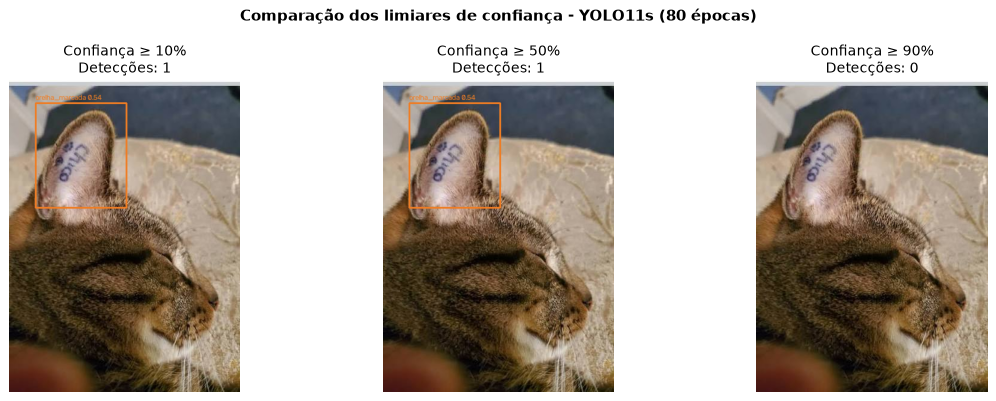


Resultados:
Confiança ≥ 10%: 1 detecções
Confiança ≥ 50%: 1 detecções
Confiança ≥ 90%: 0 detecções

Figura salva em: C:\TCC_treinamento\resultados_tcc\comparacao_confianca\limiares_confianca_yolo11s_80ep.png

A confiança altera a quantidade de detecções, mas não garante que cada caixa esteja correta.


0

: 

In [ ]:
# LISTA 4 - Comparação de limiares de confiança  

from pathlib import Path
import gc
import cv2
import numpy as np
import matplotlib.pyplot as plt
import torch
from ultralytics import YOLO

BASE_DIR = Path(r"C:\TCC_treinamento")

best_path = (
    BASE_DIR
    / "resultados_tcc"
    / "comparacao_epocas"
    / "treinamento_20261103_165619"
    / "yolo11s_80ep"
    / "weights"
    / "best.pt"
)

if not best_path.is_file():
    raise FileNotFoundError(
        f"Modelo não encontrado: {best_path}"
    )

DATASET_DIR = (
    BASE_DIR
    / "dataset_yolo_20261103_151141_523409"
)

PASTA_VAL = DATASET_DIR / "images" / "val"

PASTA_SAIDA = (
    BASE_DIR
    / "resultados_tcc"
    / "comparacao_confianca"
)

PASTA_SAIDA.mkdir(parents=True, exist_ok=True)

IMGSZ = 640
DEVICE = 0 if torch.cuda.is_available() else "cpu"

MAX_LADO_VISUAL = 700

plt.close("all")
gc.collect()

best = YOLO(str(best_path))

print("Modelo carregado:", best_path)
print("Classes:", best.names)
print("Dispositivo:", DEVICE)


# 9.2.1- Selecionar imagem de validação

EXTS = {".jpg", ".jpeg", ".png", ".webp", ".bmp"}

if not PASTA_VAL.is_dir():
    raise FileNotFoundError(
        f"Pasta de validação não encontrada: {PASTA_VAL}"
    )

imagens = sorted(
    p for p in PASTA_VAL.rglob("*")
    if p.is_file() and p.suffix.lower() in EXTS
)

if not imagens:
    raise FileNotFoundError(
        f"Nenhuma imagem encontrada em: {PASTA_VAL}"
    )

imagem_amostra = None

if "amostra" in globals():
    if isinstance(amostra, dict) and "image" in amostra:

        candidata = Path(amostra["image"])

        if candidata.is_file():
            try:
                candidata.resolve().relative_to(PASTA_VAL.resolve())
                imagem_amostra = candidata
            except ValueError:
                pass

if imagem_amostra is None:
    imagem_amostra = imagens[0]

imagem_val = str(imagem_amostra)

print("Imagem selecionada:", imagem_val)


# 9.3.1 COMPARAR LIMIARES DE CONFIANÇA

limiares = (0.10, 0.50, 0.90)

# Realizar inferência somente uma vez, com o menor limiar.
# Isso permite comparar os mesmos resultados, filtrando
# posteriormente por confiança.

resultado = best.predict(
    source=imagem_val,
    conf=min(limiares),
    imgsz=IMGSZ,
    device=DEVICE,
    verbose=False
)[0]

# Desenhar as caixas em uma imagem reduzida, sem criar
# uma matriz RGB de resolução original para cada gráfico.

imagem_bgr = cv2.imread(imagem_val, cv2.IMREAD_COLOR)

if imagem_bgr is None:
    raise ValueError(
        f"Não foi possível ler a imagem: {imagem_val}"
    )

altura, largura = imagem_bgr.shape[:2]

escala = min(
    1.0,
    MAX_LADO_VISUAL / max(largura, altura)
)

nova_largura = max(1, round(largura * escala))
nova_altura = max(1, round(altura * escala))

imagem_reduzida = cv2.resize(
    imagem_bgr,
    (nova_largura, nova_altura),
    interpolation=cv2.INTER_AREA
)

del imagem_bgr
gc.collect()

# Extrair detecções uma única vez

if resultado.boxes is not None and len(resultado.boxes) > 0:

    caixas = resultado.boxes.xyxy.cpu().numpy()
    confiancas = resultado.boxes.conf.cpu().numpy()
    classes = resultado.boxes.cls.cpu().numpy().astype(int)

else:

    caixas = np.empty((0, 4), dtype=np.float32)
    confiancas = np.empty((0,), dtype=np.float32)
    classes = np.empty((0,), dtype=int)

fig, axs = plt.subplots(
    1,
    3,
    figsize=(13, 4.5),
    dpi=90
)

contagens = {}

for ax, conf in zip(axs, limiares):

    imagem_desenhada = imagem_reduzida.copy()

    indices = np.where(confiancas >= conf)[0]

    contagens[conf] = len(indices)

    for idx in indices:

        x1, y1, x2, y2 = caixas[idx] * escala

        x1 = int(round(x1))
        y1 = int(round(y1))
        x2 = int(round(x2))
        y2 = int(round(y2))

        classe = int(classes[idx])
        confianca = float(confiancas[idx])

        cor = (
            (36, 125, 239)
            if classe == 0
            else (215, 137, 35)
        )

        cv2.rectangle(
            imagem_desenhada,
            (x1, y1),
            (x2, y2),
            cor,
            2
        )

        nome_classe = best.names.get(
            classe,
            str(classe)
        )

        texto = f"{nome_classe} {confianca:.2f}"

        cv2.putText(
            imagem_desenhada,
            texto,
            (max(0, x1), max(15, y1 - 5)),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.4,
            cor,
            1,
            cv2.LINE_AA
        )

    imagem_rgb = cv2.cvtColor(
        imagem_desenhada,
        cv2.COLOR_BGR2RGB
    )

    ax.imshow(imagem_rgb)
    ax.set_title(
        f"Confiança ≥ {conf:.0%}\n"
        f"Detecções: {len(indices)}",
        fontsize=11
    )
    ax.axis("off")

    del imagem_desenhada, imagem_rgb

fig.suptitle(
    "Comparação dos limiares de confiança - YOLO11s (80 épocas)",
    fontsize=12,
    fontweight="bold"
)

fig.tight_layout()

# 9.4.1 Salvar figuras 

ARQUIVO_SAIDA = (
    PASTA_SAIDA
    / "limiares_confianca_yolo11s_80ep.png"
)

fig.savefig(
    ARQUIVO_SAIDA,
    dpi=120,
    facecolor="white"
)

plt.show()
plt.close(fig)

print("\nResultados:")

for conf, quantidade in contagens.items():
    print(
        f"Confiança ≥ {conf:.0%}: "
        f"{quantidade} detecções"
    )

print("\nFigura salva em:", ARQUIVO_SAIDA)

print(
    "\nA confiança altera a quantidade de detecções, "
    "mas não garante que cada caixa esteja correta."
)

del resultado, imagem_reduzida
gc.collect()


### 9.2- Detecção e segmentação

O modelo `yolo11s.pt` utilizado neste trabalho retorna caixas delimitadoras, classes e confianças, mas **não gera máscaras de segmentação**. Uma máscara poderia delimitar o contorno da orelha com maior precisão, o que seria interessante para estudar a geometria de cortes. Entretanto, a segmentação por instância não foi treinada nem avaliada neste notebook; a comparação aqui é apenas conceitual.

In [ ]:

# 9.2 - DETECÇÃO E SEGMENTAÇÃO EXPERIMENTAL
# Segmentação de orelhas com GrabCut (OpenCV)
# Dataset YOLO11s - TCC

from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image
import pandas as pd
import gc



BASE_DIR = Path(r"C:\TCC_treinamento")

DATASET_DIR = (
    BASE_DIR / "dataset_yolo_20261103_151141_523409"
)

PASTA_IMAGENS = DATASET_DIR / "images" / "val"
PASTA_LABELS = DATASET_DIR / "labels" / "val"

PASTA_SAIDA = (
    BASE_DIR / "resultados_tcc" / "segmentacao_exploratoria"
)

PASTA_SAIDA.mkdir(parents=True, exist_ok=True)

CLASSES = {
    0: "Orelha marcada",
    1: "Orelha normal"
}

CORES = {
    0: "#f97316",
    1: "#2389d7"
}

EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

MARGEM = 0.40
ITERACOES = 5

# Limites de resolução para evitar MemoryError
MAX_LADO_GRABCUT = 500
MAX_LADO_VISUAL = 650

# Resolução de exportação
DPI_FIGURA = 120

# Limitar imagens examinadas por classe
MAX_TENTATIVAS = 20


if not PASTA_IMAGENS.is_dir():
    raise FileNotFoundError(
        f"Pasta de imagens não encontrada: {PASTA_IMAGENS}"
    )

if not PASTA_LABELS.is_dir():
    raise FileNotFoundError(
        f"Pasta de anotações não encontrada: {PASTA_LABELS}"
    )

print("SEGMENTAÇÃO EXPERIMENTAL DE ORELHAS - GRABCUT")

print("Dataset:", DATASET_DIR.name)
print("Imagens:", PASTA_IMAGENS)
print("Anotações:", PASTA_LABELS)

plt.close("all")
gc.collect()

# 9.2.3- Função de reduzir imagens 

def reduzir_imagem(imagem, max_lado=650, mascara=False):

    h, w = imagem.shape[:2]

    escala = min(
        1.0,
        max_lado / max(h, w)
    )

    if escala == 1.0:
        return imagem.copy(), 1.0

    novo_w = max(1, round(w * escala))
    novo_h = max(1, round(h * escala))

    interpolacao = (
        cv2.INTER_NEAREST
        if mascara
        else cv2.INTER_AREA
    )

    reduzida = cv2.resize(
        imagem,
        (novo_w, novo_h),
        interpolation=interpolacao
    )

    return reduzida, escala

# 9.2.4- Localizar orelhas anotadas

def encontrar_amostras():

    amostras = []

    for imagem_path in sorted(PASTA_IMAGENS.rglob("*")):

        if (
            not imagem_path.is_file()
            or imagem_path.suffix.lower() not in EXTS
        ):
            continue

        relativo = imagem_path.relative_to(PASTA_IMAGENS)

        label_path = (
            PASTA_LABELS / relativo
        ).with_suffix(".txt")

        if not label_path.is_file():
            continue

        try:
            with Image.open(imagem_path) as img:
                largura, altura = img.size
                img.verify()

            linhas = label_path.read_text(
                encoding="utf-8"
            ).splitlines()

        except (OSError, ValueError):
            continue

        for linha in linhas:

            partes = linha.strip().split()

            if len(partes) != 5:
                continue

            try:
                classe = int(partes[0])
                xc, yc, w, h = map(float, partes[1:])
            except ValueError:
                continue

            if classe not in CLASSES:
                continue

            if not all(
                np.isfinite(v) for v in (xc, yc, w, h)
            ):
                continue

            if w <= 0 or h <= 0:
                continue

            x1 = max(0, int((xc - w / 2) * largura))
            y1 = max(0, int((yc - h / 2) * altura))
            x2 = min(largura, int((xc + w / 2) * largura))
            y2 = min(altura, int((yc + h / 2) * altura))

            if x2 <= x1 or y2 <= y1:
                continue

            amostras.append({
                "imagem": imagem_path,
                "classe": classe,
                "caixa": (x1, y1, x2, y2),
                "area_box": (x2 - x1) * (y2 - y1)
            })

    return amostras


amostras = encontrar_amostras()

print("\nOrelhas anotadas encontradas:", len(amostras))

for classe in CLASSES:
    quantidade = sum(
        a["classe"] == classe
        for a in amostras
    )

    print(f"{CLASSES[classe]}: {quantidade}")

if not amostras:
    raise ValueError(
        "Nenhuma anotação YOLO válida foi encontrada."
    )

# 9.2.5- Segmentação do Grabcut 

def segmentar_orelha(amostra):

    caminho_imagem = amostra["imagem"]
    classe = amostra["classe"]

    x1, y1, x2, y2 = amostra["caixa"]

    # Ler apenas o recorte necessário da imagem.
    # Evita enviar a fotografia inteira ao Matplotlib.
    with Image.open(caminho_imagem) as img:

        largura_img, altura_img = img.size

        largura_box = x2 - x1
        altura_box = y2 - y1

        mx = max(12, round(largura_box * MARGEM))
        my = max(12, round(altura_box * MARGEM))

        rx1 = max(0, x1 - mx)
        ry1 = max(0, y1 - my)
        rx2 = min(largura_img, x2 + mx)
        ry2 = min(altura_img, y2 + my)

        roi = np.asarray(
            img.crop((rx1, ry1, rx2, ry2)).convert("RGB")
        ).copy()

    if roi.size == 0:
        raise ValueError("Recorte vazio.")

    # Coordenadas da caixa dentro do recorte
    bx1 = x1 - rx1
    by1 = y1 - ry1
    bx2 = x2 - rx1
    by2 = y2 - ry1

    # Reduzir antes do processamento
    roi_proc, escala = reduzir_imagem(
        roi,
        MAX_LADO_GRABCUT
    )

    hp, wp = roi_proc.shape[:2]

    if hp < 12 or wp < 12:
        raise ValueError("Recorte muito pequeno.")

    # Adicionar margem ao redor da região
    padding = 12

    roi_proc = cv2.copyMakeBorder(
        roi_proc,
        padding,
        padding,
        padding,
        padding,
        cv2.BORDER_REFLECT_101
    )

    # Converter coordenadas da caixa
    gx1 = max(1, round(bx1 * escala) + padding)
    gy1 = max(1, round(by1 * escala) + padding)
    gx2 = min(
        roi_proc.shape[1] - 1,
        round(bx2 * escala) + padding
    )
    gy2 = min(
        roi_proc.shape[0] - 1,
        round(by2 * escala) + padding
    )

    largura_rect = gx2 - gx1
    altura_rect = gy2 - gy1

    if largura_rect < 2 or altura_rect < 2:
        raise ValueError("Retângulo inválido para GrabCut.")

    # Modelos estatísticos do GrabCut
    mascara_inicial = np.zeros(
        roi_proc.shape[:2],
        dtype=np.uint8
    )

    bgd_model = np.zeros((1, 65), np.float64)
    fgd_model = np.zeros((1, 65), np.float64)

    retangulo = (
        gx1,
        gy1,
        largura_rect,
        altura_rect
    )

    imagem_bgr = cv2.cvtColor(
        roi_proc,
        cv2.COLOR_RGB2BGR
    )

    cv2.grabCut(
        imagem_bgr,
        mascara_inicial,
        retangulo,
        bgd_model,
        fgd_model,
        ITERACOES,
        cv2.GC_INIT_WITH_RECT
    )

    mascara = np.where(
        (mascara_inicial == cv2.GC_FGD)
        | (mascara_inicial == cv2.GC_PR_FGD),
        255,
        0
    ).astype(np.uint8)

    # Remover o padding
    mascara = mascara[
        padding:-padding,
        padding:-padding
    ]

    # Reduzir a região usada para visualização
    roi_visual, _ = reduzir_imagem(
        roi,
        MAX_LADO_VISUAL
    )

    mascara_visual = cv2.resize(
        mascara,
        (roi_visual.shape[1], roi_visual.shape[0]),
        interpolation=cv2.INTER_NEAREST
    )

    # Aplicar uma leve limpeza morfológica
    kernel = np.ones((3, 3), np.uint8)

    mascara_visual = cv2.morphologyEx(
        mascara_visual,
        cv2.MORPH_OPEN,
        kernel
    )

    # Criar sobreposição colorida
    sobreposicao = roi_visual.copy()

    pixels = mascara_visual > 0

    cor = np.array(
        [255, 125, 35]
        if classe == 0
        else [35, 145, 255],
        dtype=np.float32
    )

    alpha = 0.40

    sobreposicao[pixels] = (
        (1 - alpha) * roi_visual[pixels].astype(np.float32)
        + alpha * cor
    ).astype(np.uint8)

    # Desenhar contornos
    contornos, _ = cv2.findContours(
        mascara_visual,
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_SIMPLE
    )

    cv2.drawContours(
        sobreposicao,
        contornos,
        -1,
        (255, 255, 0),
        2
    )

    # Criar visualização do recorte com sua caixa
    roi_caixa = roi_visual.copy()

    escala_x = roi_visual.shape[1] / roi.shape[1]
    escala_y = roi_visual.shape[0] / roi.shape[0]

    cx1 = round(bx1 * escala_x)
    cy1 = round(by1 * escala_y)
    cx2 = round(bx2 * escala_x)
    cy2 = round(by2 * escala_y)

    cv2.rectangle(
        roi_caixa,
        (cx1, cy1),
        (cx2, cy2),
        (255, 120, 0)
        if classe == 0
        else (30, 145, 255),
        2
    )

    area_mascara = int(
        np.count_nonzero(mascara_visual)
    )

    return {
        "arquivo": caminho_imagem.name,
        "classe": classe,
        "roi": roi_visual,
        "roi_caixa": roi_caixa,
        "mascara": mascara_visual,
        "sobreposicao": sobreposicao,
        "area_mascara_px": area_mascara,
        "largura": roi_visual.shape[1],
        "altura": roi_visual.shape[0]
    }

# 9.2.6- Selecionar orelha de cada classe

resultados = []

for classe in (0, 1):

    candidatas = sorted(
        (
            a for a in amostras
            if a["classe"] == classe
        ),
        key=lambda a: a["area_box"],
        reverse=True
    )

    if not candidatas:
        raise ValueError(
            f"Nenhuma anotação da classe {classe}."
        )

    resultado_classe = None

    for amostra in candidatas[:MAX_TENTATIVAS]:

        try:
            candidato = segmentar_orelha(amostra)

            if candidato["area_mascara_px"] == 0:
                continue

            resultado_classe = candidato
            break

        except (cv2.error, OSError, ValueError) as erro:
            print(
                "Ignorando:",
                amostra["imagem"].name,
                str(erro)[:120]
            )

    if resultado_classe is None:
        raise RuntimeError(
            f"Não foi possível segmentar {CLASSES[classe]}."
        )

    resultados.append(resultado_classe)

    print(
        f"\n{CLASSES[classe]}: "
        f"{resultado_classe['arquivo']}"
    )

    print(
        "Área da máscara estimada:",
        resultado_classe["area_mascara_px"],
        "pixels da imagem reduzida"
    )

# 9.2.7- Galeria visual com baixo consumo de memória 

plt.close("all")
gc.collect()

fig, axes = plt.subplots(
    2,
    4,
    figsize=(14, 7),
    dpi=100
)

titulos = [
    "Caixa anotada (GT)",
    "Região da orelha",
    "Máscara estimada",
    "Sobreposição da máscara"
]

for linha, resultado in enumerate(resultados):

    imagens_painel = [
        resultado["roi_caixa"],
        resultado["roi"],
        resultado["mascara"],
        resultado["sobreposicao"]
    ]

    for coluna, imagem in enumerate(imagens_painel):

        ax = axes[linha, coluna]

        if imagem.ndim == 2:

            ax.imshow(
                imagem,
                cmap="gray",
                vmin=0,
                vmax=255,
                interpolation="nearest"
            )

        else:

            ax.imshow(
                imagem,
                interpolation="nearest"
            )

        ax.set_title(
            titulos[coluna],
            fontsize=11,
            fontweight="bold"
        )

        ax.axis("off")

    axes[linha, 0].text(
        0.02,
        0.04,
        CLASSES[resultado["classe"]],
        transform=axes[linha, 0].transAxes,
        fontsize=10,
        fontweight="bold",
        color="white",
        bbox={
            "facecolor": "black",
            "alpha": 0.65,
            "pad": 4
        }
    )

fig.suptitle(
    "Detecção por caixas e segmentação exploratória "
    "de orelhas de gatos\n"
    "Método GrabCut - Conjunto de validação",
    fontsize=14,
    fontweight="bold"
)

fig.subplots_adjust(
    left=0.02,
    right=0.98,
    bottom=0.04,
    top=0.86,
    wspace=0.08,
    hspace=0.20
)

# ============================================================
# 8. SALVAR FIGURA
# ============================================================

ARQUIVO_FIGURA = (
    PASTA_SAIDA / "segmentacao_grabcut_orelhas.png"
)

fig.savefig(
    ARQUIVO_FIGURA,
    dpi=DPI_FIGURA,
    facecolor="white"
)

plt.show()
plt.close(fig)

# ============================================================
# 9. SALVAR MÁSCARAS E SOBREPOSIÇÕES
# ============================================================

registros = []

for i, resultado in enumerate(resultados, start=1):

    classe = resultado["classe"]

    nome_classe = (
        "orelha_marcada"
        if classe == 0
        else "orelha_normal"
    )

    prefixo = f"{i:02d}_{nome_classe}"

    arquivo_mascara = (
        PASTA_SAIDA / f"{prefixo}_mascara.png"
    )

    arquivo_sobreposicao = (
        PASTA_SAIDA / f"{prefixo}_sobreposicao.png"
    )

    arquivo_roi = (
        PASTA_SAIDA / f"{prefixo}_recorte.png"
    )

    cv2.imwrite(
        str(arquivo_mascara),
        resultado["mascara"]
    )

    Image.fromarray(
        resultado["sobreposicao"]
    ).save(arquivo_sobreposicao)

    Image.fromarray(
        resultado["roi"]
    ).save(arquivo_roi)

    registros.append({
        "classe": nome_classe,
        "imagem": resultado["arquivo"],
        "largura_visual": resultado["largura"],
        "altura_visual": resultado["altura"],
        "area_mascara_px": resultado["area_mascara_px"],
        "arquivo_mascara": str(arquivo_mascara),
        "arquivo_sobreposicao": str(arquivo_sobreposicao)
    })

# 9.2.10- Tabelas com resultados 

df_segmentacao = pd.DataFrame(registros)

ARQUIVO_CSV = (
    PASTA_SAIDA / "resumo_segmentacao.csv"
)

df_segmentacao.to_csv(
    ARQUIVO_CSV,
    index=False,
    encoding="utf-8-sig"
)

print("RESULTADOS DA SEGMENTAÇÃO")

display(df_segmentacao)

print("\nFigura:", ARQUIVO_FIGURA)
print("Resumo:", ARQUIVO_CSV)

print(
    "\nObservação: as máscaras são estimativas do GrabCut. "
    "Não foram validadas contra máscaras manuais."
)

# 9.2.11- Liberar memória LIBERAR MEMÓRIA

del fig, axes
gc.collect()

print("\nProcessamento concluído com sucesso.")


## 10. Análises complementares de visão computacional — Lista 5

As células desta seção exploram momentos e centroide, momentos invariantes de Hu, assinatura de contorno, descritores LBP e histogramas de cor sobre recortes de orelhas anotadas.

Esses descritores ajudam a observar diferenças entre imagens, mas os recortes retangulares também podem incluir fundo, pelos e outras regiões. Além disso, os descritores dependentes de contorno são afetados pela qualidade da máscara binária. Por esse motivo, as distâncias calculadas entre duas imagens são tratadas como observações exploratórias, e não como evidência de capacidade de classificação.

LISTA 5 - DESCRITORES DE ORELHAS DE GATOS
Dataset: dataset_yolo_20261103_151141_523409
Total de orelhas anotadas: 141
orelha_marcada: Castrado__Tattoo__TATTOO_0027.jpg
orelha_normal: Nao Castrado__NORMAL_0055.jpg


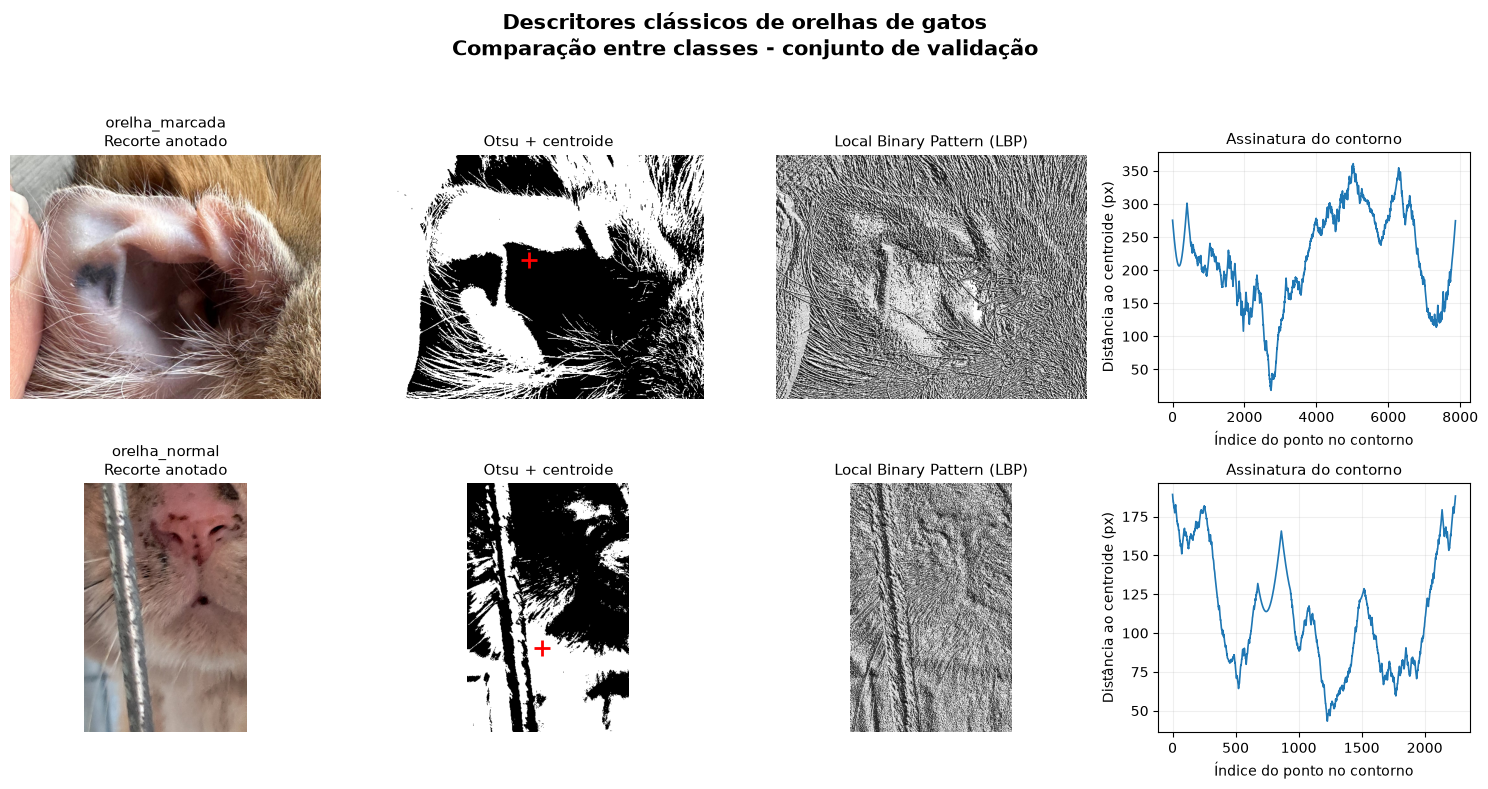

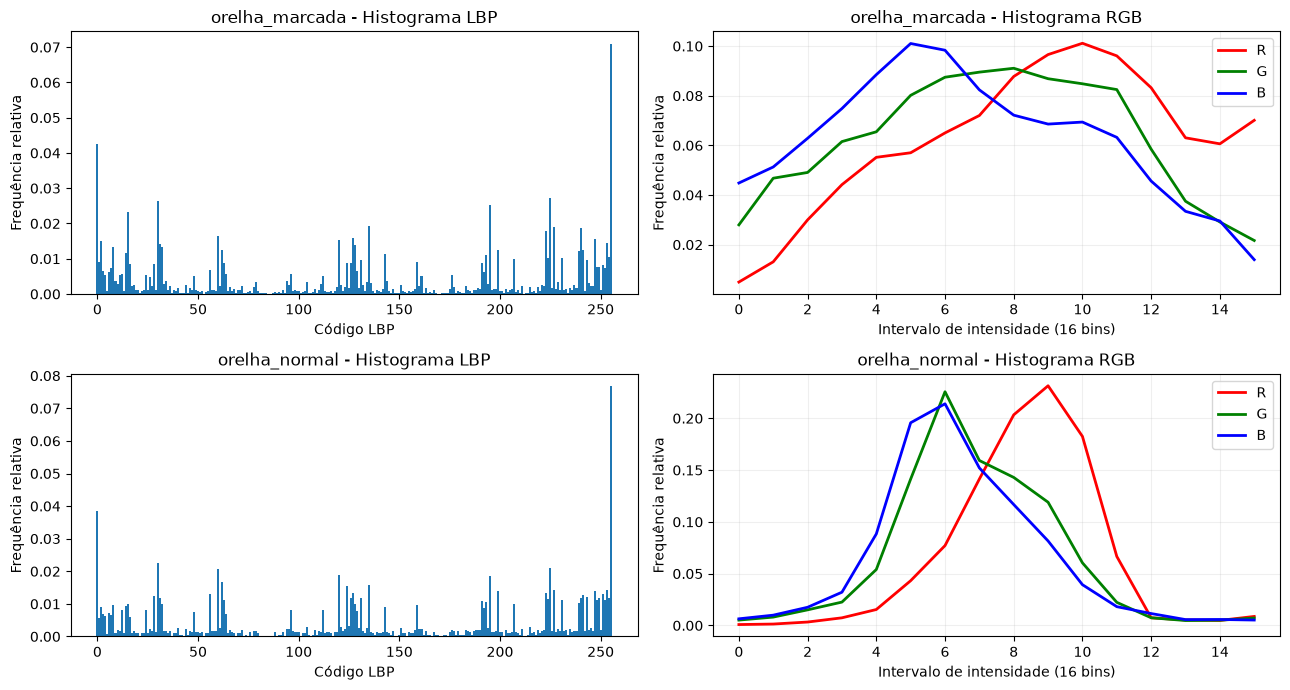

RESULTADOS DOS DESCRITORES


,classe,imagem,limiar_otsu,centroide_x,centroide_y,pontos_contorno,hu_1,hu_2,hu_3,hu_4,hu_5,hu_6,hu_7
0,orelha_marcada,Castrado__Tattoo__TATTOO_0027.jpg,128.0,223.9398,172.8924,7868,0.4599,1.9195,2.6391,2.9840,-6.0348,4.8808,-5.8832
1,orelha_normal,Nao Castrado__NORMAL_0055.jpg,127.0,153.6026,337.5293,2245,0.4421,1.8513,2.1580,2.0022,4.0995,2.9801,-4.6409



Momentos de Hu (transformação logarítmica):

orelha_marcada: [ 0.4599  1.9195  2.6391  2.984  -6.0348  4.8808 -5.8832]

orelha_normal: [ 0.4421  1.8513  2.158   2.0022  4.0995  2.9801 -4.6409]

Arquivos salvos em: C:\TCC_treinamento\resultados_tcc\descritores_orelhas
Figura: descritores_orelhas.png
Histogramas: histogramas_lbp_rgb.png
Resumo: resumo_descritores.csv

Observação: os descritores são exploratórios. A máscara de Otsu pode representar pelagem, sombras e fundo, não necessariamente toda a orelha.


54472

In [3]:
# LISTA 5 - DESCRITORES DE IMAGEM
# Momentos, centroide, Hu, assinatura, LBP e histograma RGB
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from PIL import Image
import gc

BASE_DIR = Path(r"C:\TCC_treinamento")

DATASET_DIR = (
    BASE_DIR / "dataset_yolo_20261103_151141_523409"
)

PASTA_IMAGENS = DATASET_DIR / "images" / "val"
PASTA_LABELS = DATASET_DIR / "labels" / "val"

PASTA_SAIDA = (
    BASE_DIR / "resultados_tcc" / "descritores_orelhas"
)

PASTA_SAIDA.mkdir(parents=True, exist_ok=True)

CLASSES = {
    0: "orelha_marcada",
    1: "orelha_normal"
}

EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

MAX_LADO = 512
DPI = 120

if not PASTA_IMAGENS.is_dir():
    raise FileNotFoundError(PASTA_IMAGENS)

if not PASTA_LABELS.is_dir():
    raise FileNotFoundError(PASTA_LABELS)

plt.close("all")
gc.collect()

print("LISTA 5 - DESCRITORES DE ORELHAS DE GATOS")
print("Dataset:", DATASET_DIR.name)

def encontrar_amostras():

    amostras = []

    for caminho in sorted(PASTA_IMAGENS.rglob("*")):

        if (
            not caminho.is_file()
            or caminho.suffix.lower() not in EXTS
        ):
            continue

        relativo = caminho.relative_to(PASTA_IMAGENS)

        label = (
            PASTA_LABELS / relativo
        ).with_suffix(".txt")

        if not label.is_file():
            continue

        try:
            with Image.open(caminho) as img:
                largura, altura = img.size
                img.verify()

            linhas = label.read_text(
                encoding="utf-8"
            ).splitlines()

        except (OSError, ValueError):
            continue

        for linha in linhas:

            partes = linha.strip().split()

            if len(partes) != 5:
                continue

            try:
                classe = int(partes[0])
                xc, yc, w, h = map(float, partes[1:])
            except ValueError:
                continue

            if classe not in CLASSES:
                continue

            if not np.isfinite([xc, yc, w, h]).all():
                continue

            if w <= 0 or h <= 0:
                continue

            x1 = max(0, int((xc - w / 2) * largura))
            y1 = max(0, int((yc - h / 2) * altura))
            x2 = min(largura, int((xc + w / 2) * largura))
            y2 = min(altura, int((yc + h / 2) * altura))

            if x2 <= x1 or y2 <= y1:
                continue

            amostras.append({
                "imagem": caminho,
                "classe": classe,
                "caixa": (x1, y1, x2, y2),
                "area_caixa": (x2 - x1) * (y2 - y1)
            })

    return amostras


amostras = encontrar_amostras()

print("Total de orelhas anotadas:", len(amostras))

if not amostras:
    raise ValueError("Nenhuma anotação válida encontrada.")

# 10. 1- Recortar irelha em resolução controlada  

def recorte_orelha(amostra):

    x1, y1, x2, y2 = amostra["caixa"]

    with Image.open(amostra["imagem"]) as origem:

        recorte = origem.crop(
            (x1, y1, x2, y2)
        ).convert("RGB")

        recorte.thumbnail(
            (MAX_LADO, MAX_LADO),
            Image.Resampling.LANCZOS
        )

        imagem = np.asarray(recorte).copy()

    if imagem.size == 0:
        raise ValueError("Recorte vazio.")

    return imagem

# 10.2- Caluclar descritores 

def descritores_orelha(amostra):

    img = recorte_orelha(amostra)

    gray = cv2.cvtColor(
        img,
        cv2.COLOR_RGB2GRAY
    )

    #Segmentação de Ostu
    
    limiar, mascara = cv2.threshold(
        gray,
        0,
        255,
        cv2.THRESH_BINARY + cv2.THRESH_OTSU
    )

    # Momentos e centroide

    momentos = cv2.moments(
        mascara,
        binaryImage=True
    )

    if momentos["m00"] > 0:

        cx = momentos["m10"] / momentos["m00"]
        cy = momentos["m01"] / momentos["m00"]

        centroide = (cx, cy)

    else:
        centroide = (np.nan, np.nan)

    #Momento de Hu 

    hu = cv2.HuMoments(momentos).ravel()

    hu_log = (
        -np.sign(hu)
        * np.log10(
            np.maximum(np.abs(hu), 1e-30)
        )
    )

    # Assinatura do contorno 

    contornos, _ = cv2.findContours(
        mascara,
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_NONE
    )

    assinatura = np.array([], dtype=float)

    if contornos:

        contorno = max(
            contornos,
            key=cv2.contourArea
        ).reshape(-1, 2)

        # Centroide do maior contorno
        momentos_contorno = cv2.moments(
            contorno.astype(np.float32)
        )

        if momentos_contorno["m00"] > 0:

            centro = np.array([
                momentos_contorno["m10"] / momentos_contorno["m00"],
                momentos_contorno["m01"] / momentos_contorno["m00"]
            ])

            assinatura = np.linalg.norm(
                contorno.astype(float) - centro,
                axis=1
            )

    
    # Local Binary pattern (LBP) 

    g = gray.astype(np.int16)

    if min(gray.shape) >= 3:

        centro = g[1:-1, 1:-1]

        vizinhos = [
            g[:-2, :-2],
            g[:-2, 1:-1],
            g[:-2, 2:],
            g[1:-1, 2:],
            g[2:, 2:],
            g[2:, 1:-1],
            g[2:, :-2],
            g[1:-1, :-2]
        ]

        lbp = np.zeros(
            centro.shape,
            dtype=np.uint8
        )

        for k, vizinho in enumerate(vizinhos):

            lbp |= (
                (vizinho >= centro).astype(np.uint8)
                << k
            )

    else:

        lbp = np.zeros(
            (1, 1),
            dtype=np.uint8
        )

    hist_lbp = np.histogram(
        lbp,
        bins=256,
        range=(0, 256)
    )[0].astype(float)

    hist_lbp /= max(hist_lbp.sum(), 1)


    # Histograma de cor RGB 

    histogramas = []

    for canal in range(3):

        hist = np.histogram(
            img[:, :, canal],
            bins=16,
            range=(0, 256)
        )[0].astype(float)

        hist /= max(hist.sum(), 1)

        histogramas.append(hist)

    hist_cor = np.concatenate(histogramas)

    return {
        "imagem": img,
        "gray": gray,
        "mascara": mascara,
        "limiar_otsu": limiar,
        "centroide": centroide,
        "hu": hu_log,
        "assinatura": assinatura,
        "lbp": lbp,
        "hist_lbp": hist_lbp,
        "hist_cor": hist_cor
    }


# 10.2.3- Selecionar uma amostra de cada classe 

resultados = {}

for classe in (0, 1):

    candidatas = sorted(
        (
            amostra for amostra in amostras
            if amostra["classe"] == classe
        ),
        key=lambda a: a["area_caixa"],
        reverse=True
    )

    if not candidatas:
        raise ValueError(
            f"Nenhuma amostra da classe {classe}."
        )

    # Selecionar uma orelha por classe
    amostra = candidatas[0]

    resultado = descritores_orelha(amostra)

    resultados[classe] = {
        "arquivo": amostra["imagem"].name,
        **resultado
    }

    print(
        f"{CLASSES[classe]}: "
        f"{amostra['imagem'].name}"
    )

# 10.2.4 Visualizar Descritores  

fig, axs = plt.subplots(
    2,
    4,
    figsize=(15, 8),
    dpi=100
)

for linha, classe in enumerate((0, 1)):

    exemplo = resultados[classe]

    axs[linha, 0].imshow(
        exemplo["imagem"]
    )

    axs[linha, 0].set_title(
        f"{CLASSES[classe]}\nRecorte anotado",
        fontsize=11
    )
    # Ostu + Centroide 

    axs[linha, 1].imshow(
        exemplo["mascara"],
        cmap="gray",
        vmin=0,
        vmax=255
    )

    if np.isfinite(exemplo["centroide"]).all():

        axs[linha, 1].plot(
            *exemplo["centroide"],
            "r+",
            markersize=12,
            markeredgewidth=2
        )

    axs[linha, 1].set_title(
        "Otsu + centroide",
        fontsize=11
    )
    # LBP

    axs[linha, 2].imshow(
        exemplo["lbp"],
        cmap="gray",
        vmin=0,
        vmax=255
    )

    axs[linha, 2].set_title(
        "Local Binary Pattern (LBP)",
        fontsize=11
    )
    # Assinatura 

    assinatura = exemplo["assinatura"]

    if assinatura.size:

        axs[linha, 3].plot(
            assinatura,
            linewidth=1.2
        )

    axs[linha, 3].set_title(
        "Assinatura do contorno",
        fontsize=11
    )

    axs[linha, 3].set_xlabel(
        "Índice do ponto no contorno"
    )

    axs[linha, 3].set_ylabel(
        "Distância ao centroide (px)"
    )

    axs[linha, 3].grid(alpha=0.2)

    for coluna in range(3):
        axs[linha, coluna].axis("off")

fig.suptitle(
    "Descritores clássicos de orelhas de gatos\n"
    "Comparação entre classes - conjunto de validação",
    fontsize=15,
    fontweight="bold"
)

fig.tight_layout(rect=[0, 0, 1, 0.93])

ARQUIVO_FIGURA = (
    PASTA_SAIDA / "descritores_orelhas.png"
)

fig.savefig(
    ARQUIVO_FIGURA,
    dpi=DPI
)

plt.show()
plt.close(fig)

# 10.2.4- Histograma LBP e RGB 

fig, axs = plt.subplots(
    2,
    2,
    figsize=(13, 7),
    dpi=100
)

for linha, classe in enumerate((0, 1)):

    exemplo = resultados[classe]

    # Histograma LBP
    axs[linha, 0].bar(
        np.arange(256),
        exemplo["hist_lbp"],
        width=1
    )

    axs[linha, 0].set_title(
        f"{CLASSES[classe]} - Histograma LBP"
    )

    axs[linha, 0].set_xlabel("Código LBP")
    axs[linha, 0].set_ylabel("Frequência relativa")

    # Histograma RGB
    hist_cor = exemplo["hist_cor"]

    for canal, cor, nome in [
        (0, "red", "R"),
        (1, "green", "G"),
        (2, "blue", "B")
    ]:

        inicio = canal * 16

        axs[linha, 1].plot(
            np.arange(16),
            hist_cor[inicio:inicio + 16],
            color=cor,
            label=nome,
            linewidth=2
        )

    axs[linha, 1].set_title(
        f"{CLASSES[classe]} - Histograma RGB"
    )

    axs[linha, 1].set_xlabel(
        "Intervalo de intensidade (16 bins)"
    )

    axs[linha, 1].set_ylabel(
        "Frequência relativa"
    )

    axs[linha, 1].legend()
    axs[linha, 1].grid(alpha=0.2)

fig.tight_layout()

ARQUIVO_HIST = (
    PASTA_SAIDA / "histogramas_lbp_rgb.png"
)

fig.savefig(
    ARQUIVO_HIST,
    dpi=DPI
)

plt.show()
plt.close(fig)

# 10.2.4- Resultados 

registros = []

for classe in (0, 1):

    exemplo = resultados[classe]

    registro = {
        "classe": CLASSES[classe],
        "imagem": exemplo["arquivo"],
        "limiar_otsu": float(exemplo["limiar_otsu"]),
        "centroide_x": float(exemplo["centroide"][0]),
        "centroide_y": float(exemplo["centroide"][1]),
        "pontos_contorno": len(exemplo["assinatura"])
    }

    for i, valor in enumerate(exemplo["hu"], start=1):
        registro[f"hu_{i}"] = float(valor)

    registros.append(registro)

df_descritores = pd.DataFrame(registros)

ARQUIVO_CSV = (
    PASTA_SAIDA / "resumo_descritores.csv"
)

df_descritores.to_csv(
    ARQUIVO_CSV,
    index=False,
    encoding="utf-8-sig"
)

print("RESULTADOS DOS DESCRITORES")
display(df_descritores.round(4))

print("\nMomentos de Hu (transformação logarítmica):")

for classe in (0, 1):

    print(
        f"\n{CLASSES[classe]}:",
        np.round(resultados[classe]["hu"], 4)
    )

print("\nArquivos salvos em:", PASTA_SAIDA)
print("Figura:", ARQUIVO_FIGURA.name)
print("Histogramas:", ARQUIVO_HIST.name)
print("Resumo:", ARQUIVO_CSV.name)

print(
    "\nObservação: os descritores são exploratórios. "
    "A máscara de Otsu pode representar pelagem, "
    "sombras e fundo, não necessariamente toda a orelha."
)

gc.collect()


### 10.1 Características intermediárias de redes neurais

A extração de características de camadas internas do YOLO poderia permitir uma análise adicional da similaridade entre recortes. Para isso, seria necessário definir uma camada de referência, um pré-processamento comum e uma forma consistente de agregar as características.

Essa extração não está implementada nesta seção. Os experimentos realizados aqui se limitam aos descritores calculados pelas células anteriores, e não devem ser apresentados como resultados de embeddings internos do YOLO.

## 11. Experimento exploratório com V-JEPA 2

Além do detector YOLO11s, foi investigado o uso de representações visuais produzidas pelo V-JEPA 2 em recortes de orelhas. A intenção foi verificar a viabilidade de extrair vetores de características de imagens de duas classes e examinar sua similaridade.

Os dois modelos executam tarefas distintas. **O YOLO11s localiza e classifica orelhas em fotografias completas**, enquanto **o V-JEPA 2, no procedimento utilizado, recebe recortes definidos a partir de anotações existentes e produz embeddings**. Portanto, essa análise não mede desempenho de detecção nem permite uma comparação direta de mAP entre as abordagens.

Como o V-JEPA 2 foi desenvolvido para sequências de vídeo, o experimento adaptou imagens estáticas por repetição de quadros. Essa adaptação não acrescenta informação temporal. O modelo foi utilizado sem ajuste fino de seus parâmetros.

Documentação consultada no desenvolvimento: [V-JEPA 2 (Meta)](https://github.com/facebookresearch/vjepa2) e [Transformers — V-JEPA 2](https://huggingface.co/docs/transformers/model_doc/vjepa2).

### 11.1 Dependências

As células seguintes verificam as versões das bibliotecas e preparam o ambiente para carregar o modelo pré-treinado. O download dos pesos depende de acesso à internet. Na execução registrada, o V-JEPA 2 foi processado em CPU; por isso, os tempos apresentados se referem especificamente a esse ambiente.

In [22]:

%pip install -U transformers huggingface_hub accelerate scikit-learn pillow pyyaml pandas matplotlib torch


  Using cached torch-2.15.0-cp313-cp313-win_amd64.whl.metadata (36 kB)
Using cached torch-2.15.0-cp313-cp313-win_amd64.whl (126.7 MB)
  Attempting uninstall: torch
    Found existing installation: torch 2.13.0+cu130
    Uninstalling torch-2.13.0+cu130:
      Successfully uninstalled torch-2.13.0+cu130
Note: you may need to restart the kernel to use updated packages.


  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  You can safely remove it manually.
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
torchvision 0.28.0+cu130 requires torch==2.13.0, but you have torch 2.15.0 which is incompatible.

[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [23]:
%pip install -U transformers accelerate safetensors pillow

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [24]:

import sys
import torch
import importlib.metadata as metadata

print("Python:", sys.version)
print("Executável:", sys.executable)
print("PyTorch:", torch.__version__)
print("CUDA:", torch.version.cuda)
print("CUDA disponível:", torch.cuda.is_available())

for pacote in ["torchvision", "transformers", "accelerate"]:
    try:
        print(f"{pacote}:", metadata.version(pacote))
    except metadata.PackageNotFoundError:
        print(f"{pacote}: não instalado")


Python: 3.13.13 (tags/v3.13.13:01104ce, Apr  7 2026, 19:25:48) [MSC v.1944 64 bit (AMD64)]
Executável: c:\Users\barba\AppData\Local\Python\pythoncore-3.13-64\python.exe
PyTorch: 2.13.0+cu130
CUDA: 13.0
CUDA disponível: True
torchvision: 0.28.0+cu130
transformers: 5.22.1
accelerate: 1.15.0


In [25]:
import torch
import torchvision
from torchvision.ops import nms
from transformers import AutoModel, AutoVideoProcessor

print("=" * 55)
print("VERIFICAÇÃO DO AMBIENTE")
print("=" * 55)

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("CUDA:", torch.version.cuda)
print("CUDA disponível:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

# Testar operação NMS
boxes = torch.tensor([
    [0.0, 0.0, 10.0, 10.0],
    [1.0, 1.0, 9.0, 9.0]
])

scores = torch.tensor([0.9, 0.8])

resultado = nms(boxes, scores, 0.5)

print("NMS funcionando:", resultado.tolist())
print("AutoVideoProcessor importado com sucesso!")


VERIFICAÇÃO DO AMBIENTE
PyTorch: 2.13.0+cu130
Torchvision: 0.28.0+cu130
CUDA: 13.0
CUDA disponível: True
GPU: NVIDIA GeForce RTX 4050 Laptop GPU
NMS funcionando: [0]
AutoVideoProcessor importado com sucesso!


In [26]:
%pip install pandas numpy pillow matplotlib scikit-learn tqdm

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


### 11.2 Carregamento do V-JEPA 2 em CPU - ver notebook separado do VJEPA

### 11.3 Extração dos embeddings dos recortes

### 11.4 Seleção das amostras

### 11.5 Extração dos vetores e medição do tempo

### 11.6 Cálculo da similaridade e armazenamento dos resultados

### 11.7 Interpretação do experimento exploratório

A execução registrada utilizou **duas orelhas do conjunto de treinamento**, uma marcada e uma normal. Cada recorte foi representado por um vetor de **1.024 dimensões**. Os tempos de extração em CPU foram de aproximadamente **6,15 s** e **2,22 s** por amostra, respectivamente. Esses valores refletem apenas a execução registrada e não representam um benchmark robusto.

A similaridade de cosseno entre os dois vetores foi **0,753503**. O resultado mostra uma proximidade entre as representações produzidas, mas, com somente duas amostras, não é possível medir separabilidade entre classes, precisão ou capacidade de generalização.

Um estudo posterior poderia utilizar um conjunto maior de recortes, mantendo a divisão de dados independente por indivíduo, e treinar um classificador sobre os embeddings. Essa extensão não foi realizada no experimento de duas amostras.

### 11.8 Limites da comparação com o YOLO11s

O resultado do V-JEPA 2 não deve ser comparado diretamente às métricas do YOLO11s, pois a entrada e a tarefa são diferentes. No experimento principal, o detector deve encontrar a orelha na fotografia e atribuir sua classe. No experimento complementar, a região já foi delimitada pela anotação antes da extração de características.

A investigação serviu para testar a extração de representações e registrar um resultado preliminar de similaridade. Não foi estabelecida uma avaliação quantitativa de classificação com V-JEPA 2 neste notebook.

### 11.9 Possível extensão: classificador linear

Uma continuação seria treinar uma regressão logística sobre embeddings extraídos do **conjunto de treinamento**, selecionando decisões com a validação e reservando o teste para a avaliação final. Poderia ser utilizada ponderação de classes quando necessário.

**Essa etapa é proposta, não um resultado registrado neste notebook.** As métricas de classificação de recortes obtidas nesse cenário não seriam diretamente equivalentes às métricas de detecção do YOLO11s.

### 11.10 Comparação entre as abordagens

| Critério | YOLO11s | V-JEPA 2, no experimento realizado |
|---|---|---|
| Entrada | Fotografia completa | Recorte de orelha previamente anotado |
| Operação | Localização e classificação | Extração de características |
| Saída | Caixas, classes e confiança | Vetor de 1.024 características |
| Avaliação registrada | Precisão, recall e mAP da detecção | Tempo de extração e similaridade entre duas amostras |
| Localiza a orelha? | Sim | Não, são necessários mais experimentos |
| Situação no TCC | Experimento principal, com três treinamentos | Análise complementar exploratória |

Uma comparação direta de classificação exigiria submeter **os mesmos recortes** aos dois métodos e calcular métricas equivalentes. Para analisar aplicações em campo, também seria necessário medir o sistema completo — incluindo aquisição, localização, classificação e revisão de casos incertos. O fato de uma orelha não apresentar marcação visível não comprova a ausência de esterilização.

## 12. Estudos preliminares para aplicação em sistema embarcado

Uma possível continuidade do trabalho é integrar o detector a um sistema de aquisição de imagens, com câmera e unidade de processamento capazes de executar a inferência localmente. Nesta seção, foram preparados scripts de seleção do modelo, inspeção de imagens, inferência e exportação para outros formatos.

**O notebook não registra um protótipo embarcado validado em campo.** As execuções apresentadas foram feitas no computador de desenvolvimento, com fotografias existentes no dataset. Portanto, os valores de latência e memória não podem ser atribuídos a um Raspberry Pi, Jetson ou outro dispositivo embarcado.

Para uma aplicação futura, seria necessário investigar qualidade da captura, iluminação, distância, movimentação dos animais, uso de memória, consumo energético, privacidade e revisão humana de casos incertos.

### 12.1 Plataformas possíveis para implantação

Foram consideradas diferentes alternativas de hardware, com necessidades distintas de câmera, processamento e aceleração. A tabela abaixo organiza possibilidades de estudo; ela **não representa uma comparação experimental realizada**.

| Plataforma | Possibilidade de utilização | Limitação a investigar |
|---|---|---|
| Raspberry Pi 5 | Captura e inferência em CPU | Latência e memória com o modelo escolhido |
| Raspberry Pi 5 com acelerador compatível | Inferência acelerada após conversão do modelo | Compatibilidade e desempenho real da conversão |
| NVIDIA Jetson | Inferência com aceleração por GPU | Consumo, custo e desempenho no dispositivo |
| Microcontrolador com câmera | Captura e encaminhamento de imagens | Recursos insuficientes para executar diretamente o YOLO11s convencional |

A seleção de uma plataforma depende de testes no hardware real. Números teóricos de capacidade de processamento não substituem medições de latência, consumo e acurácia com o modelo utilizado.

### 12.2 Preparação do ambiente de inferência

As rotinas foram preparadas para testes locais em Python, utilizando um modelo `best.pt` já treinado. O procedimento também pode orientar uma futura adaptação a dispositivos com câmera, desde que a aquisição das imagens seja compatível com o hardware escolhido.

Em câmeras CSI, por exemplo, o método de captura pode ser diferente daquele empregado por uma webcam USB. Não foi assumida compatibilidade automática entre plataformas.

In [ ]:

# 12.2 - AMBIENTE E ARTEFATOS DA IMPLANTAÇÃO
# Protótipo local de aquisição e inferência

from pathlib import Path
import platform
import sys
import json
import importlib.metadata
import os


BASE_DIR = Path(r"C:\TCC_treinamento")

TCC_LIMPO = Path(
    r"C:\Users\barba\OneDrive\Documentos\TCC_limpo"
)

DATASET_DIR = (
    BASE_DIR / "dataset_yolo_20261103_151141_523409"
)

DATASET_YAML = DATASET_DIR / "data_local.yaml"

DIR_TREINAMENTOS = (
    BASE_DIR
    / "resultados_tcc"
    / "comparacao_epocas"
    / "treinamento_20261103_165619"
)

DIR_CAMPO = BASE_DIR / "resultados_embarcados"
DIR_CAMPO.mkdir(parents=True, exist_ok=True)

MODELOS_ESPERADOS = {
    30: DIR_TREINAMENTOS / "yolo11s_30ep" / "weights" / "best.pt", #localizar arquivos
    80: DIR_TREINAMENTOS / "yolo11s_80ep" / "weights" / "best.pt",
    150: DIR_TREINAMENTOS / "yolo11s_150ep" / "weights" / "best.pt"
}

modelos_encontrados = {
    epocas: caminho
    for epocas, caminho in MODELOS_ESPERADOS.items()
    if caminho.is_file()
}

print("=" * 65)
print("MODELOS YOLO11s - TREINAMENTOS DE 2026-11-03")
print("=" * 65)

for epocas, caminho in MODELOS_ESPERADOS.items():

    status = (
        "ENCONTRADO"
        if caminho.is_file()
        else "NÃO ENCONTRADO"
    )

    print(f"\nYOLO11s - {epocas} épocas: {status}")
    print(caminho)

if not modelos_encontrados:
    raise FileNotFoundError(
        "Nenhum checkpoint best.pt foi encontrado "
        f"em {DIR_TREINAMENTOS}"
    )

# 10.2.3- Priorizar modelod de 80 épocas 

if 80 in modelos_encontrados:

    MODELO_PT = modelos_encontrados[80]
    EPOCAS_MODELO = 80

else:

    # Alternativa explícita caso o modelo de 80 épocas
    # não esteja disponível.
    EPOCAS_MODELO = max(modelos_encontrados.keys())
    MODELO_PT = modelos_encontrados[EPOCAS_MODELO]

    print(
        "\nATENÇÃO: modelo de 80 épocas não encontrado."
    )

print("\nModelo selecionado:")
print(MODELO_PT)

# 9.2.4- Parâmetros do protótipo 

RESOLUCAO_INFERENCIA = 640
CONFIANCA_MIN = 0.25
CAMERA_USB_INDICE = 0
DEVICE_CAMPO = "cpu"

# 9.2.5- Versões instalad sem importar bibliotecas

def versao_pacote(nome):

    try:
        return importlib.metadata.version(nome)

    except importlib.metadata.PackageNotFoundError:
        return None


VERSAO_TORCH = versao_pacote("torch")
VERSAO_ULTRALYTICS = versao_pacote("ultralytics")
VERSAO_OPENCV = versao_pacote("opencv-python")


if not DATASET_DIR.is_dir():
    print("\nAVISO: dataset não encontrado em:")
    print(DATASET_DIR)

if not DATASET_YAML.is_file():
    print("\nAVISO: data_local.yaml não encontrado em:")
    print(DATASET_YAML)


configuracao = {
    "python": sys.version.split()[0],
    "executavel_python": sys.executable,
    "plataforma": platform.platform(),

    "pytorch_instalado": VERSAO_TORCH,
    "ultralytics_instalado": VERSAO_ULTRALYTICS,
    "opencv_instalado": VERSAO_OPENCV,

    "dataset": str(DATASET_DIR),
    "dataset_existe": DATASET_DIR.is_dir(),
    "dataset_yaml": str(DATASET_YAML),
    "dataset_yaml_existe": DATASET_YAML.is_file(),

    "modelo": str(MODELO_PT),
    "modelo_existe": MODELO_PT.is_file(),
    "epocas_modelo": EPOCAS_MODELO,

    "modelos_disponiveis": {
        str(epocas): str(caminho)
        for epocas, caminho in modelos_encontrados.items()
    },

    "destino": str(DIR_CAMPO.resolve()),

    "resolucao_inferencia": RESOLUCAO_INFERENCIA,
    "confianca_minima": CONFIANCA_MIN,
    "camera_usb_indice": CAMERA_USB_INDICE,

    "dispositivo_configurado": DEVICE_CAMPO,
    "dispositivo_testado": False,
    "inferencia_executada": False
}

print("CONFIGURAÇÃO DO PROTÓTIPO")

for chave, valor in configuracao.items():
    print(f"{chave}: {valor}")

#Salvar configs 

ARQUIVO_CONFIG = (
    DIR_CAMPO / "configuracao_prototipo.json"
)

with open(
    ARQUIVO_CONFIG,
    "w",
    encoding="utf-8"
) as arquivo:

    json.dump(
        configuracao,
        arquivo,
        indent=4,
        ensure_ascii=False
    )

print("\n" + "=" * 65)
print("CONFIGURAÇÃO SALVA COM SUCESSO")
print("=" * 65)

print("Arquivo:", ARQUIVO_CONFIG)
print("Modelo selecionado:", MODELO_PT.name)
print("Treinamento:", EPOCAS_MODELO, "épocas")

print(
    "\nO PyTorch não foi importado e "
    "nenhum modelo foi carregado na memória."
)


MODELOS YOLO11s - TREINAMENTOS DE 2026-11-03

YOLO11s - 30 épocas: ENCONTRADO
C:\TCC_treinamento\resultados_tcc\comparacao_epocas\treinamento_20261103_165619\yolo11s_30ep\weights\best.pt

YOLO11s - 80 épocas: ENCONTRADO
C:\TCC_treinamento\resultados_tcc\comparacao_epocas\treinamento_20261103_165619\yolo11s_80ep\weights\best.pt

YOLO11s - 150 épocas: ENCONTRADO
C:\TCC_treinamento\resultados_tcc\comparacao_epocas\treinamento_20261103_165619\yolo11s_150ep\weights\best.pt

Modelo selecionado:
C:\TCC_treinamento\resultados_tcc\comparacao_epocas\treinamento_20261103_165619\yolo11s_80ep\weights\best.pt

CONFIGURAÇÃO DO PROTÓTIPO
python: 3.13.13
executavel_python: c:\Users\barba\OneDrive\Documentos\TCC_limpo\.venv_yolo\Scripts\python.exe
plataforma: Windows-11-10.0.26200-SP0
pytorch_instalado: 2.13.0+cu130
ultralytics_instalado: 8.4.174
opencv_instalado: 5.0.0.93
dataset: C:\TCC_treinamento\dataset_yolo_20261103_151141_523409
dataset_existe: True
dataset_yaml: C:\TCC_treinamento\dataset_yolo_2

### 12.3 Aquisição de imagens

O código de captura foi preparado para uso sob demanda, condicionado à variável `HABILITAR_CAPTURA`. Essa escolha evita a coleta involuntária de fotografias durante os testes. A execução depende de uma câmera acessível ao ambiente Python e não comprova funcionamento em hardware embarcado.

In [ ]:
from ultralytics import YOLO

# Carregar modelo treinado
modelo_embarcado = YOLO(str(MODELO_PT))

print("MODELO CARREGADO")

print("Pesos:", MODELO_PT.name)
print("Classes:", modelo_embarcado.names)
print("Dispositivo solicitado:", DEVICE_CAMPO)

# Verificar correspondência das classes
classes_esperadas = {
    0: "orelha_marcada",
    1: "orelha_normal"
}

if modelo_embarcado.names != classes_esperadas:
    raise ValueError(
        "As classes do modelo não correspondem às "
        "classes esperadas do TCC. "
        f"Classes encontradas: {modelo_embarcado.names}"
    )

print("\nModelo validado para o protótipo!")


MODELO CARREGADO
Pesos: best.pt
Classes: {0: 'orelha_marcada', 1: 'orelha_normal'}
Dispositivo solicitado: cpu

Modelo validado para o protótipo!


### 12.4 Indicadores de qualidade das fotografias

Foram utilizados indicadores simples de brilho, contraste e variação do Laplaciano para examinar características das fotografias. Essas medidas auxiliam a identificar possíveis dificuldades de exposição e nitidez, mas não determinam, por si só, se uma imagem é adequada para classificar a orelha.

Na execução salva, não foram encontradas fotos de campo na pasta inicialmente consultada. A análise utilizou **cinco imagens do conjunto de treinamento**. Assim, trata-se de um teste local dos indicadores e não de uma avaliação de capturas feitas por um dispositivo embarcado.

Nenhuma foto de campo encontrada.
Procurando fotografias do dataset YOLO...
Dataset encontrado: C:\Users\barba\OneDrive\Documentos\TCC_limpo\dataset_yolo_20261103_151141_523409\images\train

Total de imagens selecionadas: 5


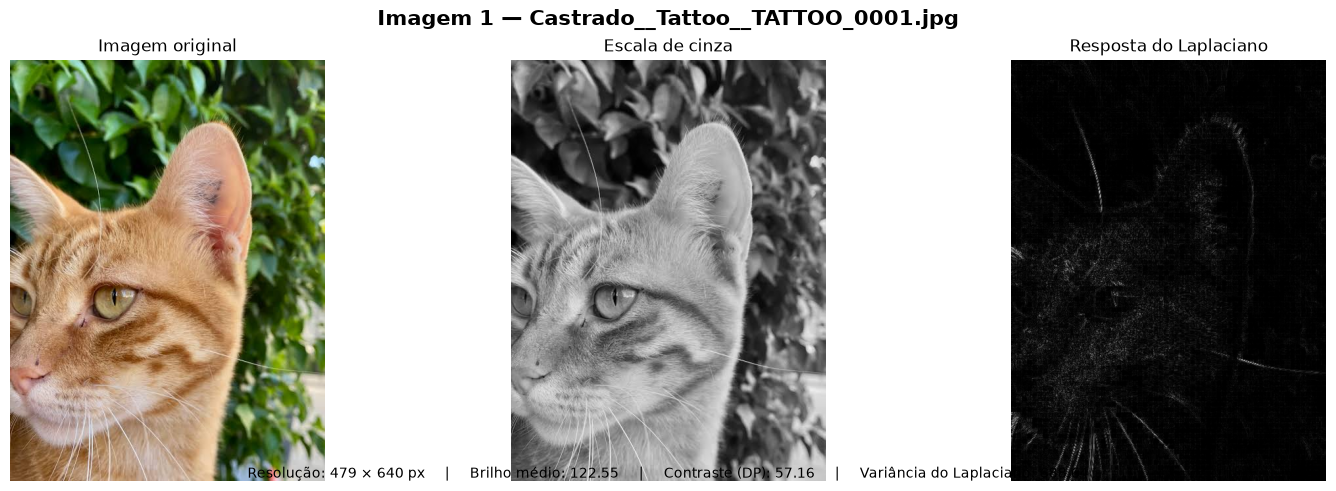

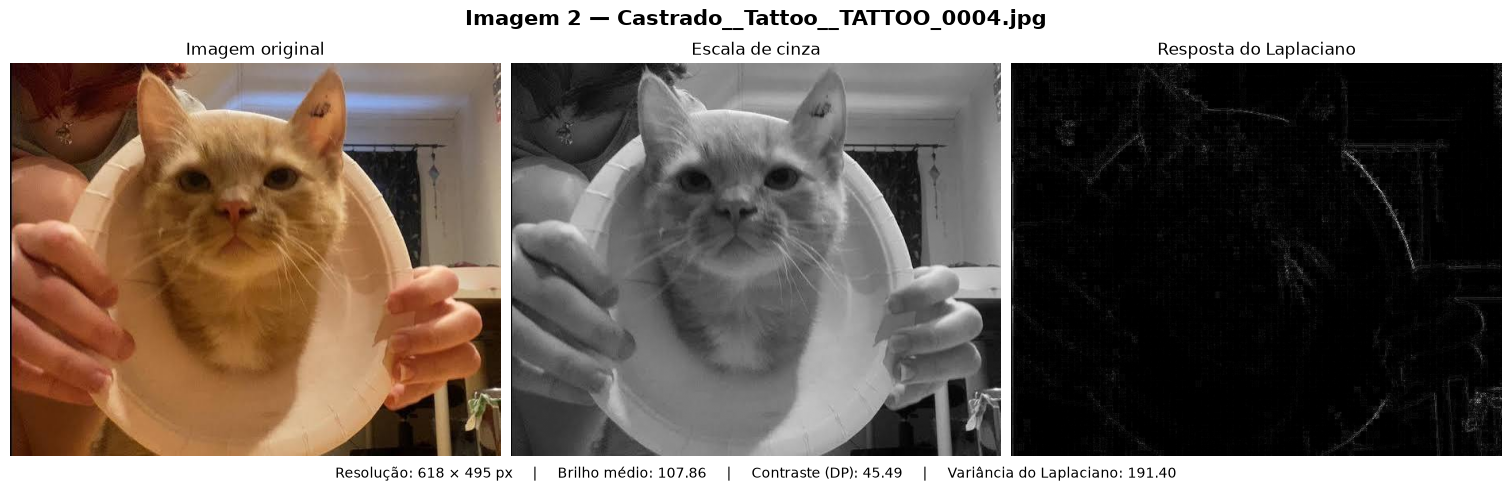

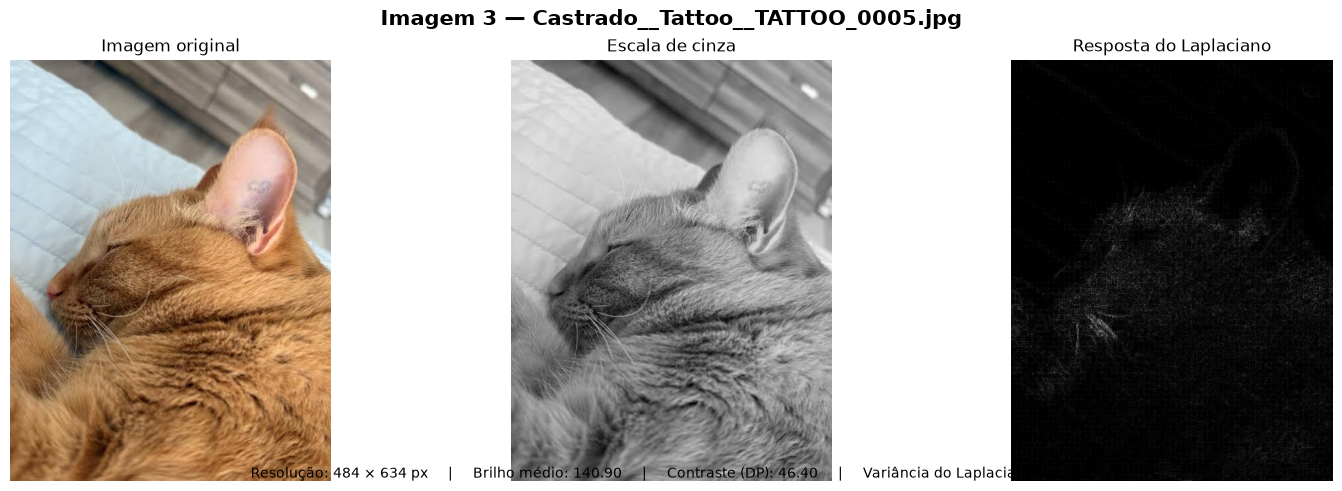

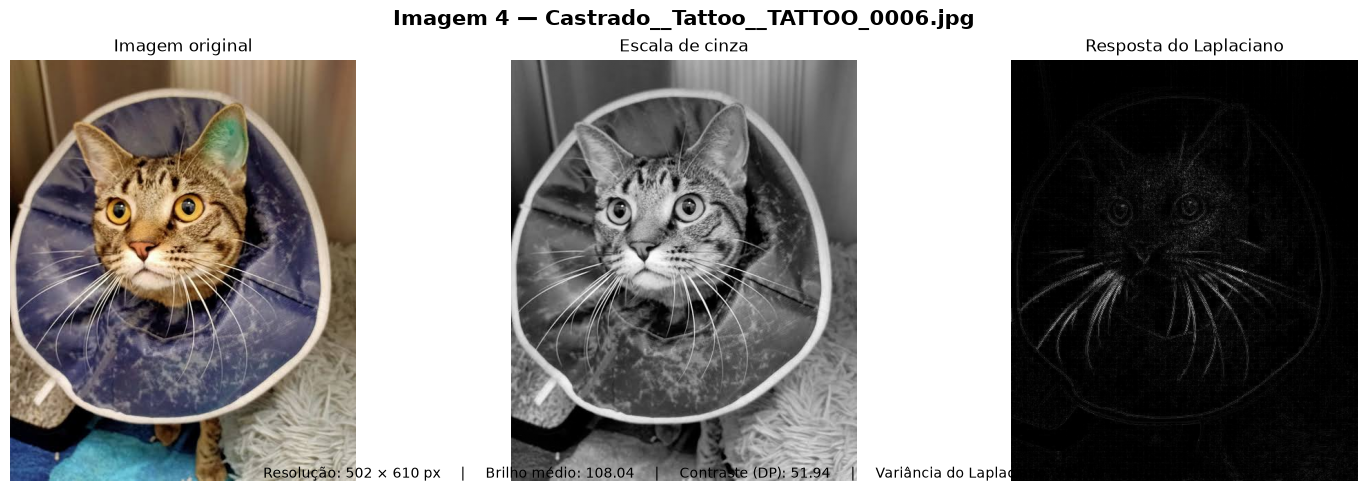

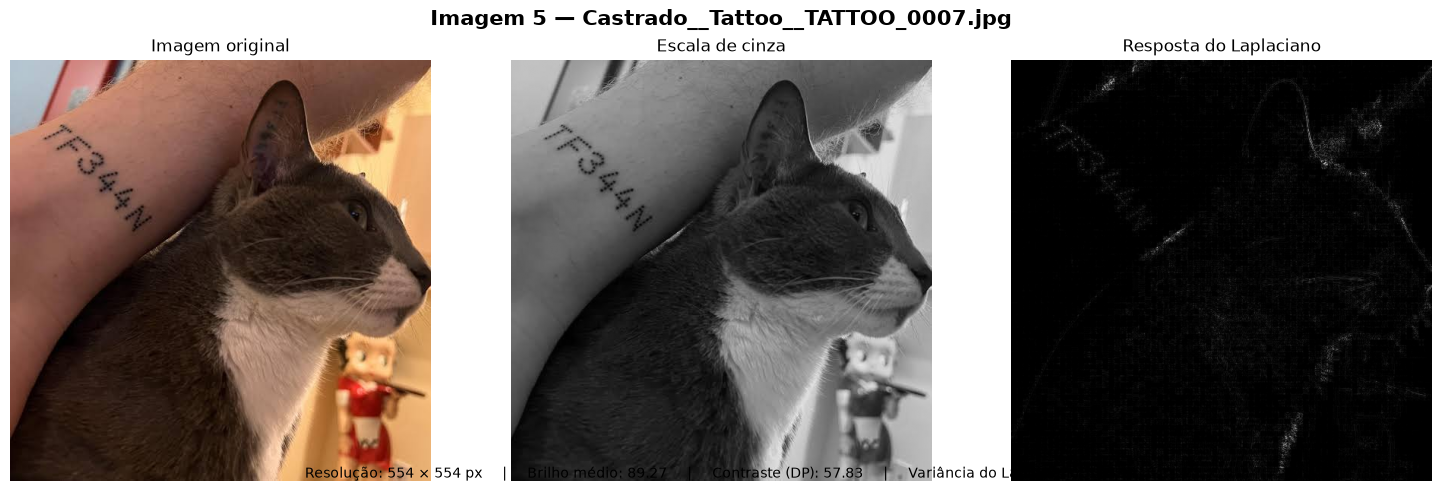

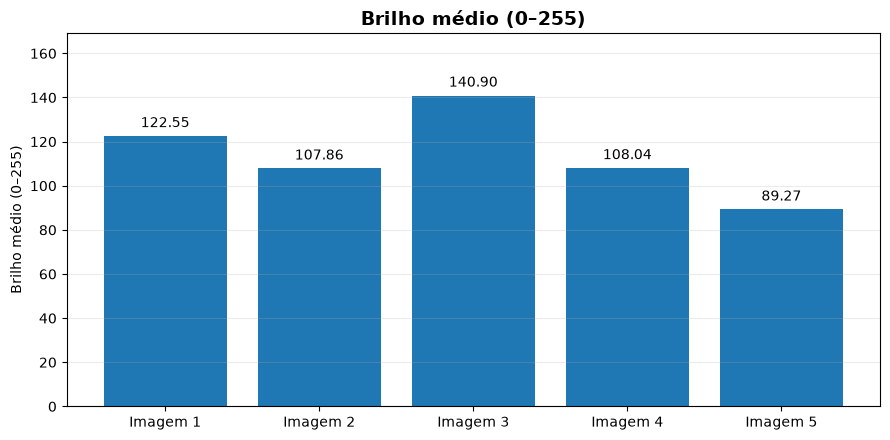

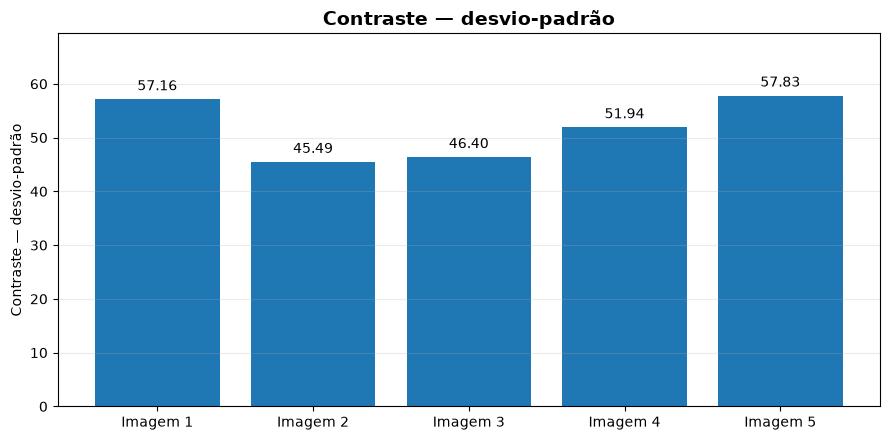

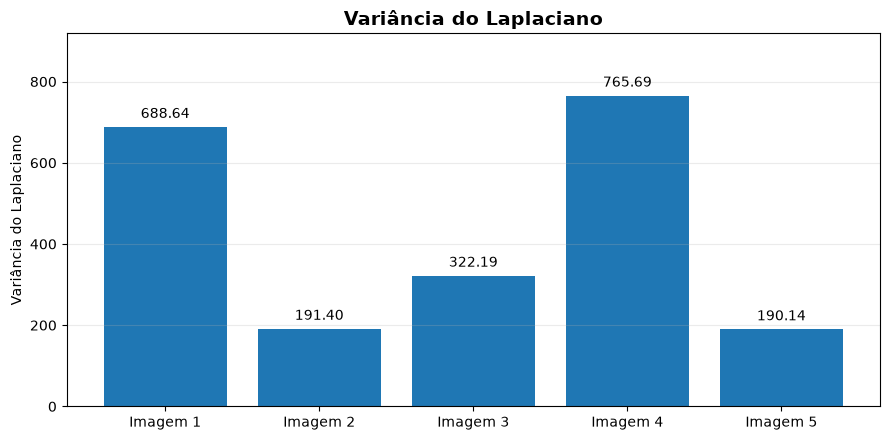


RESULTADOS DA AVALIAÇÃO DE QUALIDADE


,imagem,largura,altura,brilho_medio,contraste_desvio,laplaciano_var
0,Castrado__Tattoo__TATTOO_0001.jpg,479,640,122.55,57.16,688.64
1,Castrado__Tattoo__TATTOO_0004.jpg,618,495,107.86,45.49,191.40
2,Castrado__Tattoo__TATTOO_0005.jpg,484,634,140.90,46.40,322.19
3,Castrado__Tattoo__TATTOO_0006.jpg,502,610,108.04,51.94,765.69
4,Castrado__Tattoo__TATTOO_0007.jpg,554,554,89.27,57.83,190.14



Avaliação concluída!
Gráficos e relatórios salvos em:
C:\TCC_treinamento\resultados_embarcados\avaliacao_qualidade


In [ ]:
# 12.4 - Avaliação visual da qualidade de captura 

from pathlib import Path
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 12.4.1- Função para indicadores de qualidade 

def indicadores_imagem(bgr):
    cinza = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)

    return {
        "altura": int(cinza.shape[0]),
        "largura": int(cinza.shape[1]),
        "brilho_medio": float(cinza.mean()),
        "contraste_desvio": float(cinza.std()),
        "laplaciano_var": float(
            cv2.Laplacian(cinza, cv2.CV_64F).var()
        )
    }


DIR_CAMPO = Path(DIR_CAMPO)
DIR_CAMPO.mkdir(parents=True, exist_ok=True)

PASTA_IMAGENS_CAMPO = DIR_CAMPO
PASTA_GRAFICOS = DIR_CAMPO / "avaliacao_qualidade"
PASTA_GRAFICOS.mkdir(parents=True, exist_ok=True)

EXTENSOES = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
MAX_IMAGENS = 5

# Buscar fotografias já disponíveis na pasta de campo
fotos = sorted([
    p for p in PASTA_IMAGENS_CAMPO.iterdir()
    if p.is_file() and p.suffix.lower() in EXTENSOES
])

# Caso não haja fotos de campo, usar fotografias do dataset
if not fotos:

    print("Nenhuma foto de campo encontrada.")
    print("Procurando fotografias do dataset YOLO...")

    locais_dataset = []

    if "DATASET" in globals():
        locais_dataset.append(
            Path(DATASET) / "images" / "train"
        )

    for raiz in [
        Path(r"C:\Users\barba\OneDrive\Documentos\TCC_limpo"),
        Path(r"C:\Users\barba\OneDrive\Documentos\TCC"),
    ]:
        if raiz.exists():
            locais_dataset.extend(
                raiz.glob("dataset_yolo*/images/train")
            )

    for pasta in locais_dataset:

        if pasta.is_dir():
            fotos = sorted([
                p for p in pasta.rglob("*")
                if p.is_file()
                and p.suffix.lower() in EXTENSOES
            ])

            if fotos:
                print("Dataset encontrado:", pasta)
                break

fotos = fotos[:MAX_IMAGENS]

if not fotos:
    raise FileNotFoundError(
        "Nenhuma imagem encontrada em DIR_CAMPO "
        "ou no dataset YOLO."
    )

print(f"\nTotal de imagens selecionadas: {len(fotos)}")

#Analizar imagens

registros = []
imagens_visualizacao = []

for foto in fotos:

    # Leitura compatível com caminhos Unicode no Windows
    try:
        dados_arquivo = np.fromfile(str(foto), dtype=np.uint8)
        bgr = cv2.imdecode(dados_arquivo, cv2.IMREAD_COLOR)
    except (OSError, ValueError):
        bgr = None

    if bgr is None:
        print("Não foi possível abrir:", foto.name)
        continue

    indicadores = indicadores_imagem(bgr)

    cinza = cv2.cvtColor(
        bgr, cv2.COLOR_BGR2GRAY
    )

    bordas = cv2.Laplacian(
        cinza, cv2.CV_64F
    )

    rgb = cv2.cvtColor(
        bgr, cv2.COLOR_BGR2RGB
    )

    registro = {
        "imagem": foto.name,
        "caminho": str(foto),
        **indicadores
    }

    registros.append(registro)

    imagens_visualizacao.append({
        "nome": foto.name,
        "rgb": rgb,
        "cinza": cinza,
        "bordas": np.abs(bordas),
        "indicadores": indicadores
    })


if not registros:
    raise RuntimeError(
        "Nenhuma imagem válida pôde ser analisada."
    )

df_qualidade = pd.DataFrame(registros)

# Painel visual por imagem

for i, item in enumerate(imagens_visualizacao, start=1):

    metricas = item["indicadores"]

    fig, axes = plt.subplots(
        1, 3,
        figsize=(15, 4.8),
        constrained_layout=True
    )

    fig.suptitle(
        f"Imagem {i} — {item['nome']}",
        fontsize=15,
        fontweight="bold"
    )

    axes[0].imshow(item["rgb"])
    axes[0].set_title("Imagem original")
    axes[0].axis("off")

    axes[1].imshow(
        item["cinza"],
        cmap="gray",
        vmin=0,
        vmax=255
    )
    axes[1].set_title("Escala de cinza")
    axes[1].axis("off")

    axes[2].imshow(
        item["bordas"],
        cmap="gray"
    )
    axes[2].set_title("Resposta do Laplaciano")
    axes[2].axis("off")

    texto_metricas = (
        f"Resolução: "
        f"{metricas['largura']} × "
        f"{metricas['altura']} px     |     "
        f"Brilho médio: "
        f"{metricas['brilho_medio']:.2f}     |     "
        f"Contraste (DP): "
        f"{metricas['contraste_desvio']:.2f}     |     "
        f"Variância do Laplaciano: "
        f"{metricas['laplaciano_var']:.2f}"
    )

    fig.text(
        0.5, 0.015,
        texto_metricas,
        ha="center",
        fontsize=10
    )

    arquivo_saida = (
        PASTA_GRAFICOS / f"painel_imagem_{i:02d}.png"
    )

    fig.savefig(
        arquivo_saida,
        dpi=180,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)


#Gráficos
metricas_comparacao = [
    ("brilho_medio", "Brilho médio (0–255)"),
    ("contraste_desvio", "Contraste — desvio-padrão"),
    ("laplaciano_var", "Variância do Laplaciano")
]

nomes_curtos = [
    f"Imagem {i}"
    for i in range(1, len(df_qualidade) + 1)
]

for coluna, titulo in metricas_comparacao:

    fig, ax = plt.subplots(figsize=(9, 4.5))

    valores = df_qualidade[coluna].to_numpy()

    barras = ax.bar(
        nomes_curtos,
        valores
    )

    ax.bar_label(
        barras,
        fmt="%.2f",
        padding=4
    )

    ax.set_title(
        titulo,
        fontsize=14,
        fontweight="bold"
    )

    ax.set_ylabel(titulo)
    ax.set_ylim(
        0,
        max(valores) * 1.2 if max(valores) > 0 else 1
    )

    ax.grid(
        axis="y",
        alpha=0.25
    )

    fig.tight_layout()

    arquivo_saida = (
        PASTA_GRAFICOS / f"{coluna}.png"
    )

    fig.savefig(
        arquivo_saida,
        dpi=180,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)


#Tabelas

print("RESULTADOS DA AVALIAÇÃO DE QUALIDADE")

colunas_tabela = [
    "imagem",
    "largura",
    "altura",
    "brilho_medio",
    "contraste_desvio",
    "laplaciano_var"
]

display(
    df_qualidade[colunas_tabela].round(2)
)

arquivo_csv = ( #Exportar resultados
    PASTA_GRAFICOS / "indicadores_qualidade.csv"
)

df_qualidade.to_csv(
    arquivo_csv,
    index=False,
    encoding="utf-8-sig"
)

print("\nAvaliação concluída!")
print("Gráficos e relatórios salvos em:")
print(PASTA_GRAFICOS.resolve())


### 12.5 Inferência local e registro das medições

O modelo treinado foi carregado no computador de desenvolvimento para executar inferência em cinco fotografias. A saída registra a quantidade de detecções e o tempo total das chamadas de predição.

Na execução preservada, realizada em **CPU no Windows**, a latência total mediana variou conforme o experimento. Esse valor inclui a chamada de inferência realizada pelo código e não deve ser interpretado como tempo exclusivo da rede neural ou como desempenho em equipamento embarcado. Cinco imagens são insuficientes para caracterizar a latência em diferentes condições de campo sendo uma implemntação ilustrativa.

In [4]:

# 12.5 - INFERÊNCIA LOCAL E REGISTRO AUDITÁVEL

from pathlib import Path
from time import perf_counter
from datetime import datetime
from collections import Counter

import json
import os
import platform

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import psutil
import torch

from ultralytics import YOLO
from IPython.display import display

EXECUTAR_INFERENCIA_CAMPO = True

RESOLUCAO_INFERENCIA = 640
CONFIANCA_MIN = 0.25
MAX_IMAGENS_CAMPO = 5

DEVICE_CAMPO = "cpu"

PASTAS_PROJETO = [
    Path(r"C:\Users\barba\OneDrive\Documentos\TCC_limpo"),
    Path(r"C:\Users\barba\OneDrive\Documentos\TCC"),
    Path("/content/TCC")
]

BASE_CAMPO = next(
    (p for p in PASTAS_PROJETO if p.is_dir()),
    Path.cwd()
)

DIR_CAMPO = BASE_CAMPO / "resultados_embarcados"
DIR_CAMPO.mkdir(parents=True, exist_ok=True)

DIR_INFERENCIAS = DIR_CAMPO / "inferencia_yolo"
DIR_INFERENCIAS.mkdir(parents=True, exist_ok=True)

EXTENSOES = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

CLASSES_ESPERADAS = {
    0: "orelha_marcada",
    1: "orelha_normal"
}

modelo_atual = globals().get("MODELO_PT")

if (
    modelo_atual is not None
    and Path(modelo_atual).is_file()
):
    MODELO_PT = Path(modelo_atual)

else:
    modelos = []

    for pasta in PASTAS_PROJETO:
        if pasta.is_dir():
            modelos.extend(pasta.rglob("best.pt"))

    modelos = [
        p for p in modelos
        if p.is_file()
    ]

    preferidos = [
        p for p in modelos
        if "yolo11s_80ep_" in str(p).lower()
    ]

    candidatos = preferidos if preferidos else modelos

    if not candidatos:
        raise FileNotFoundError(
            "Nenhum best.pt encontrado. "
            "Defina MODELO_PT com o caminho do seu modelo."
        )

    MODELO_PT = max(
        candidatos,
        key=lambda p: p.stat().st_mtime
    )

print("CONFIGURAÇÃO DA INFERÊNCIA")

print("Modelo:", MODELO_PT)
print("Dispositivo:", DEVICE_CAMPO)
print("Resolução:", RESOLUCAO_INFERENCIA)
print("Confiança mínima:", CONFIANCA_MIN)


def encontrar_fotos():

    fotos_campo = sorted([
        p for p in DIR_CAMPO.iterdir()
        if p.is_file()
        and p.suffix.lower() in EXTENSOES
    ])

    if fotos_campo:
        print("\nOrigem: fotografias de campo")
        return fotos_campo[:MAX_IMAGENS_CAMPO]

    # Reaproveitar fotografias da seção 13.4
    if "fotos" in globals():
        fotos_anteriores = [
            Path(p) for p in globals()["fotos"]
            if Path(p).is_file()
        ]

        if fotos_anteriores:
            print("\nOrigem: fotografias da seção 13.4")
            return fotos_anteriores[:MAX_IMAGENS_CAMPO]

    # Procurar conjunto de treinamento YOLO
    for pasta in PASTAS_PROJETO:

        if not pasta.is_dir():
            continue

        datasets = sorted(
            pasta.glob("dataset_yolo*"),
            key=lambda p: p.stat().st_mtime,
            reverse=True
        )

        for dataset in datasets:

            pasta_imagens = dataset / "images" / "train"

            if not pasta_imagens.is_dir():
                continue

            fotos_dataset = sorted([
                p for p in pasta_imagens.rglob("*")
                if p.is_file()
                and p.suffix.lower() in EXTENSOES
            ])

            if fotos_dataset:
                print("\nOrigem: dataset YOLO - treino")
                return fotos_dataset[:MAX_IMAGENS_CAMPO]

    raise FileNotFoundError(
        "Nenhuma imagem encontrada em DIR_CAMPO, "
        "na seção 13.4 ou nos datasets YOLO."
    )

def ler_imagem(caminho):

    try:
        dados = np.fromfile(str(caminho), dtype=np.uint8)

        if dados.size == 0:
            return None

        return cv2.imdecode(
            dados,
            cv2.IMREAD_COLOR
        )

    except (OSError, ValueError):
        return None



def avaliar_pasta_campo(
    modelo_pt,
    fotos,
    saida,
    imgsz=640,
    conf=0.25
):

    modelo_pt = Path(modelo_pt)
    saida = Path(saida)

    saida.mkdir(parents=True, exist_ok=True)

    if not modelo_pt.is_file():
        raise FileNotFoundError(
            f"Modelo não encontrado: {modelo_pt}"
        )

    modelo = YOLO(str(modelo_pt))

    print("\nClasses do modelo:", modelo.names)

    for classe_id, nome in CLASSES_ESPERADAS.items():
        if modelo.names.get(classe_id) != nome:
            raise ValueError(
                "As classes do modelo não correspondem "
                "ao dataset do TCC."
            )

    processo = psutil.Process(os.getpid())

    registros = []
    registros_deteccoes = []
    imagens_resultado = []

    # Aquecimento inicial, não registrado nas métricas
    # Utiliza uma imagem sintética, sem salvar resultados.
    modelo.predict(
        source=np.zeros((imgsz, imgsz, 3), dtype=np.uint8),
        imgsz=imgsz,
        conf=conf,
        device=DEVICE_CAMPO,
        verbose=False
    )

    print("EXECUTANDO INFERÊNCIA")

    for indice, foto in enumerate(fotos, start=1):

        print(
            f"\n[{indice}/{len(fotos)}] {foto.name}",
            flush=True
        )

        inicio_leitura = perf_counter()
        imagem = ler_imagem(foto)

        tempo_leitura_ms = (
            perf_counter() - inicio_leitura
        ) * 1000

        if imagem is None:
            print("Imagem não pôde ser lida.")
            continue

        inicio_inferencia = perf_counter()

        pred = modelo.predict(
            source=imagem,
            imgsz=imgsz,
            conf=conf,
            device=DEVICE_CAMPO,
            verbose=False
        )[0]

        tempo_chamada_ms = (
            perf_counter() - inicio_inferencia
        ) * 1000

        tempo_total_ms = (
            tempo_leitura_ms + tempo_chamada_ms
        )

        fps_equivalente = (
            1000 / tempo_total_ms
            if tempo_total_ms > 0
            else 0
        )
        caixas = pred.boxes

        classes = (
            caixas.cls.int().cpu().tolist()
            if caixas is not None
            else []
        )

        confiancas = (
            caixas.conf.cpu().tolist()
            if caixas is not None
            else []
        )

        coordenadas = (
            caixas.xyxy.cpu().tolist()
            if caixas is not None
            else []
        )

        contagem = Counter(classes)

        # Registrar cada detecção 

        for classe, confianca, xyxy in zip(
            classes,
            confiancas,
            coordenadas
        ):

            registros_deteccoes.append({
                "arquivo": foto.name,
                "classe_id": int(classe),
                "classe_nome": modelo.names[int(classe)],
                "confianca": round(float(confianca), 6),
                "x1": round(float(xyxy[0]), 2),
                "y1": round(float(xyxy[1]), 2),
                "x2": round(float(xyxy[2]), 2),
                "y2": round(float(xyxy[3]), 2)
            })

        #Métricas de inferência

        velocidade = pred.speed or {}

        memoria_mb = (
            processo.memory_info().rss / 1024**2
        )

        registro = {
            "arquivo": foto.name,
            "caminho": str(foto),
            "largura": int(imagem.shape[1]),
            "altura": int(imagem.shape[0]),
            "tempo_leitura_ms": round(tempo_leitura_ms, 3),
            "tempo_chamada_ms": round(tempo_chamada_ms, 3),
            "latencia_total_ms": round(tempo_total_ms, 3),
            "fps_equivalente": round(fps_equivalente, 3),
            "memoria_processo_mb": round(memoria_mb, 2),
            "num_deteccoes": len(classes),
            "orelhas_marcadas": contagem.get(0, 0),
            "orelhas_normais": contagem.get(1, 0),
            "confianca_media": (
                round(float(np.mean(confiancas)), 4)
                if confiancas else None
            ),
            "preprocess_ms": velocidade.get("preprocess"),
            "inference_ms": velocidade.get("inference"),
            "postprocess_ms": velocidade.get("postprocess"),
            "classes": json.dumps(classes),
            "confiancas": json.dumps(
                [round(float(x), 4) for x in confiancas]
            )
        }

        registros.append(registro)

        imagem_anotada = pred.plot()

        nome_saida = (
            f"inferencia_{indice:02d}_{foto.stem}.jpg"
        )

        caminho_saida = saida / nome_saida

        cv2.imencode(
            ".jpg",
            imagem_anotada
        )[1].tofile(str(caminho_saida))

        imagens_resultado.append({
            "original": imagem,
            "anotada": imagem_anotada,
            "nome": foto.name,
            "registro": registro
        })

        print(
            f"Detecções: {len(classes)} | "
            f"Marcadas: {contagem.get(0, 0)} | "
            f"Normais: {contagem.get(1, 0)}"
        )

        print(
            f"Latência total: {tempo_total_ms:.2f} ms | "
            f"FPS equivalente: {fps_equivalente:.2f}"
        )

    if not registros:
        raise RuntimeError(
            "Nenhuma imagem pôde ser processada."
        )

    df_inferencia = pd.DataFrame(registros)
    df_deteccoes = pd.DataFrame(
        registros_deteccoes,
        columns=[
            "arquivo", "classe_id", "classe_nome",
            "confianca", "x1", "y1", "x2", "y2"
        ]
    )

    df_inferencia.to_csv(
        saida / "inferencia.csv",
        index=False,
        encoding="utf-8-sig"
    )

    df_deteccoes.to_csv(
        saida / "deteccoes.csv",
        index=False,
        encoding="utf-8-sig"
    )

    return df_inferencia, df_deteccoes, imagens_resultado


if EXECUTAR_INFERENCIA_CAMPO:

    fotos_campo = encontrar_fotos()

    df_inferencia, df_deteccoes, imagens_resultado = (
        avaliar_pasta_campo(
            modelo_pt=MODELO_PT,
            fotos=fotos_campo,
            saida=DIR_INFERENCIAS,
            imgsz=RESOLUCAO_INFERENCIA,
            conf=CONFIANCA_MIN
        )
    )

    print("\n" + "=" * 65)
    print("RESUMO DA INFERÊNCIA")
    print("=" * 65)

    display(
        df_inferencia[
            [
                "arquivo",
                "num_deteccoes",
                "orelhas_marcadas",
                "orelhas_normais",
                "latencia_total_ms",
                "fps_equivalente",
                "memoria_processo_mb"
            ]
        ].round(2)
    )

    print("\nImagens avaliadas:", len(df_inferencia))
    print("Total de detecções:", len(df_deteccoes))
    print(
        "Latência mediana:",
        round(df_inferencia["latencia_total_ms"].median(), 2),
        "ms"
    )

    print("\nArquivos salvos em:")
    print(DIR_INFERENCIAS.resolve())

else:
    print("Inferência desativada.")


CONFIGURAÇÃO DA INFERÊNCIA
Modelo: C:\Users\barba\OneDrive\Documentos\TCC_limpo\resultados_tcc\comparacao_epocas\yolo11s_80ep_20261103_125700\weights\best.pt
Dispositivo: cpu
Resolução: 640
Confiança mínima: 0.25

Origem: dataset YOLO - treino

Classes do modelo: {0: 'orelha_marcada', 1: 'orelha_normal'}
EXECUTANDO INFERÊNCIA

[1/5] Castrado__Tattoo__TATTOO_0001.jpg
Detecções: 2 | Marcadas: 1 | Normais: 1
Latência total: 187.54 ms | FPS equivalente: 5.33

[2/5] Castrado__Tattoo__TATTOO_0004.jpg
Detecções: 2 | Marcadas: 1 | Normais: 1
Latência total: 139.30 ms | FPS equivalente: 7.18

[3/5] Castrado__Tattoo__TATTOO_0005.jpg
Detecções: 1 | Marcadas: 1 | Normais: 0
Latência total: 118.07 ms | FPS equivalente: 8.47

[4/5] Castrado__Tattoo__TATTOO_0006.jpg
Detecções: 2 | Marcadas: 1 | Normais: 1
Latência total: 125.39 ms | FPS equivalente: 7.98

[5/5] Castrado__Tattoo__TATTOO_0007.jpg
Detecções: 3 | Marcadas: 3 | Normais: 0
Latência total: 111.97 ms | FPS equivalente: 8.93

RESUMO DA INFERÊ

,arquivo,num_deteccoes,orelhas_marcadas,orelhas_normais,latencia_total_ms,fps_equivalente,memoria_processo_mb
0,Castrado__Tattoo__TATTOO_0001.jpg,2,1,1,187.54,5.33,433.18
1,Castrado__Tattoo__TATTOO_0004.jpg,2,1,1,139.30,7.18,451.11
2,Castrado__Tattoo__TATTOO_0005.jpg,1,1,0,118.07,8.47,460.46
3,Castrado__Tattoo__TATTOO_0006.jpg,2,1,1,125.39,7.98,468.76
4,Castrado__Tattoo__TATTOO_0007.jpg,3,3,0,111.97,8.93,514.79



Imagens avaliadas: 5
Total de detecções: 10
Latência mediana: 125.39 ms

Arquivos salvos em:
C:\Users\barba\OneDrive\Documentos\TCC_limpo\resultados_embarcados\inferencia_yolo


### 12.6 Exportação do modelo para outros formatos

A exportação foi utilizada para investigar a portabilidade do YOLO11s. O formato **ONNX** permite carregar o modelo em outros mecanismos de inferência, mas a conversão não garante redução de latência. Outros formatos, como NCNN e TensorRT, dependem de ferramentas e ambientes compatíveis.

A saída registrada demonstra a exportação para ONNX e sua execução em CPU. Não há medição em aceleradores embarcados. A comparação entre formatos só é válida quando as condições de entrada, o pré-processamento, o pós-processamento e o ambiente de execução são registrados.

In [3]:
%pip install -U onnx onnxruntime onnxslim

Note: you may need to restart the kernel to use updated packages.


In [5]:

# 12.6 - Exportação para plataformas de inferências 
from pathlib import Path
from datetime import datetime
import importlib.metadata
import json
import shutil
import platform

import onnxruntime as ort


BASE_DIR = Path(r"C:\TCC_treinamento")

TCC_LIMPO = Path(
    r"C:\Users\barba\OneDrive\Documentos\TCC_limpo"
)

MODELO_PT = (
    BASE_DIR
    / "resultados_tcc"
    / "comparacao_epocas"
    / "treinamento_20261103_165619"
    / "yolo11s_80ep"
    / "weights"
    / "best.pt"
)

MODELO_ONNX_EXISTENTE = (
    TCC_LIMPO
    / "resultados_embarcados"
    / "exportacao"
    / "yolo11s_80ep_640_onnx.onnx"
)

SAIDA_EXPORTACAO = (
    BASE_DIR
    / "resultados_embarcados"
    / "exportacao"
)

SAIDA_EXPORTACAO.mkdir(
    parents=True,
    exist_ok=True
)

FORMATO_EXPORTACAO = "onnx"
RESOLUCAO_INFERENCIA = 640
DEVICE_EXPORTACAO = "cpu"

# 2. VERIFICAR ARQUIVOS

if not MODELO_PT.is_file():
    raise FileNotFoundError(
        f"Checkpoint não encontrado: {MODELO_PT}"
    )

if not MODELO_ONNX_EXISTENTE.is_file():
    raise FileNotFoundError(
        "Modelo ONNX anterior não encontrado: "
        f"{MODELO_ONNX_EXISTENTE}"
    )

print("EXPORTAÇÃO PARA PLATAFORMAS DE INFERÊNCIA")
print("Checkpoint de referência:", MODELO_PT)
print("ONNX encontrado:", MODELO_ONNX_EXISTENTE)
print("Formato:", FORMATO_EXPORTACAO)

#Verificar onnx

opcoes = ort.SessionOptions()

opcoes.intra_op_num_threads = 1
opcoes.inter_op_num_threads = 1
opcoes.graph_optimization_level = (
    ort.GraphOptimizationLevel.ORT_ENABLE_BASIC
)

sessao = ort.InferenceSession(
    str(MODELO_ONNX_EXISTENTE),
    sess_options=opcoes,
    providers=["CPUExecutionProvider"]
)

entradas = [
    {
        "nome": entrada.name,
        "dimensoes": entrada.shape,
        "tipo": entrada.type
    }
    for entrada in sessao.get_inputs()
]

saidas = [
    {
        "nome": saida.name,
        "dimensoes": saida.shape,
        "tipo": saida.type
    }
    for saida in sessao.get_outputs()
]

print("\nEntrada ONNX:", entradas)
print("Saída ONNX:", saidas)

entrada_esperada = [1, 3, 640, 640]
saida_esperada = [1, 6, 8400]

if len(entradas) != 1 or entradas[0]["dimensoes"] != entrada_esperada:
    raise ValueError(
        f"Entrada ONNX diferente do esperado: {entradas}"
    )

if len(saidas) != 1 or saidas[0]["dimensoes"] != saida_esperada:
    raise ValueError(
        f"Saída ONNX diferente do esperado: {saidas}"
    )

# Liberar recursos do ONNX Runtime
del sessao


ARTEFATO_FINAL = (
    SAIDA_EXPORTACAO
    / "yolo11s_80ep_640_onnx.onnx"
)

if MODELO_ONNX_EXISTENTE.resolve() != ARTEFATO_FINAL.resolve():
    shutil.copy2(
        MODELO_ONNX_EXISTENTE,
        ARTEFATO_FINAL
    )

TAMANHO_MB = (
    ARTEFATO_FINAL.stat().st_size / (1024 ** 2)
)

#Registrar metadados

metadados_exportacao = {
    "data_registro": datetime.now().isoformat(
        timespec="seconds"
    ),
    "checkpoint_referencia": str(MODELO_PT),
    "checkpoint_existe": MODELO_PT.is_file(),
    "origem_onnx": str(MODELO_ONNX_EXISTENTE),
    "artefato_final": str(ARTEFATO_FINAL),
    "formato": FORMATO_EXPORTACAO,
    "resolucao": RESOLUCAO_INFERENCIA,
    "dispositivo_verificacao": DEVICE_EXPORTACAO,
    "tamanho_mb": round(TAMANHO_MB, 3),
    "entradas": entradas,
    "saidas": saidas,
    "classes_esperadas": {
        "0": "orelha_marcada",
        "1": "orelha_normal"
    },
    "onnxruntime": importlib.metadata.version(
        "onnxruntime"
    ),
    "plataforma": platform.platform(),
    "exportacao_executada_nesta_celula": False,
    "arquivo_onnx_reutilizado": True,
    "proveniencia_checkpoint_confirmada": False,
    "inferencia_executada_nesta_celula": False,
    "validacao_de_acuracia_executada": False,
    "observacao": (
        "O arquivo ONNX foi reutilizado e sua estrutura "
        "foi verificada. A correspondência exata com "
        "o checkpoint de referência não foi comprovada."
    )
}

ARQUIVO_METADADOS = (
    SAIDA_EXPORTACAO
    / "metadados_exportacao.json"
)

ARQUIVO_METADADOS.write_text(
    json.dumps(
        metadados_exportacao,
        indent=4,
        ensure_ascii=False
    ),
    encoding="utf-8"
)


print("\nVERIFICAÇÃO CONCLUÍDA")

print("Artefato:", ARTEFATO_FINAL)
print("Tamanho:", f"{TAMANHO_MB:.2f} MB")
print("Metadados:", ARQUIVO_METADADOS)

print(
    "\nO ONNX foi reutilizado, sem carregar PyTorch "
    "e sem executar novamente a exportação."
)


EXPORTAÇÃO PARA PLATAFORMAS DE INFERÊNCIA
Checkpoint de referência: C:\TCC_treinamento\resultados_tcc\comparacao_epocas\treinamento_20261103_165619\yolo11s_80ep\weights\best.pt
ONNX encontrado: C:\Users\barba\OneDrive\Documentos\TCC_limpo\resultados_embarcados\exportacao\yolo11s_80ep_640_onnx.onnx
Formato: onnx

Entrada ONNX: [{'nome': 'images', 'dimensoes': [1, 3, 640, 640], 'tipo': 'tensor(float)'}]
Saída ONNX: [{'nome': 'output0', 'dimensoes': [1, 6, 8400], 'tipo': 'tensor(float)'}]

VERIFICAÇÃO CONCLUÍDA
Artefato: C:\TCC_treinamento\resultados_embarcados\exportacao\yolo11s_80ep_640_onnx.onnx
Tamanho: 36.17 MB
Metadados: C:\TCC_treinamento\resultados_embarcados\exportacao\metadados_exportacao.json

O ONNX foi reutilizado, sem carregar PyTorch e sem executar novamente a exportação.


In [6]:
EXPORTAR_MODELO = True
FORMATO_EXPORTACAO = 'onnx'  # opções iniciais: 'onnx', 'ncnn'; 'engine' e 'hailo' exigem ambiente específico
if EXPORTAR_MODELO:
    if not MODELO_PT.is_file():
        raise FileNotFoundError(MODELO_PT)
    if FORMATO_EXPORTACAO not in {'onnx', 'ncnn', 'engine', 'hailo'}:
        raise ValueError('Formato não previsto no protocolo.')
    modelo_exportacao = YOLO(str(MODELO_PT))
    destino_exportado = modelo_exportacao.export(format=FORMATO_EXPORTACAO, imgsz=RESOLUCAO_INFERENCIA)
    print('Artefato:', destino_exportado)
else:
    print('Exportação desativada: configurar ambiente e selecionar formato.')

AttributeError: module 'torch' has no attribute '_utils'

In [7]:

# 12.6 - EXPORTAÇÃO PARA PLATAFORMAS DE INFERÊNCIA

from pathlib import Path
import shutil
import json
from datetime import datetime

BASE_DIR = Path(r"C:\TCC_treinamento")

TCC_LIMPO = Path(
    r"C:\Users\barba\OneDrive\Documentos\TCC_limpo"
)

MODELO_PT = (
    BASE_DIR
    / "resultados_tcc"
    / "comparacao_epocas"
    / "treinamento_20261103_165619"
    / "yolo11s_80ep"
    / "weights"
    / "best.pt"
)

MODELO_ONNX_EXISTENTE = (
    TCC_LIMPO
    / "resultados_embarcados"
    / "exportacao"
    / "yolo11s_80ep_640_onnx.onnx"
)

SAIDA_EXPORTACAO = (
    BASE_DIR
    / "resultados_embarcados"
    / "exportacao"
)

SAIDA_EXPORTACAO.mkdir(parents=True, exist_ok=True)

EXPORTAR_MODELO = True
FORMATO_EXPORTACAO = "onnx"
RESOLUCAO_INFERENCIA = 640

FORMATOS_PERMITIDOS = {"onnx", "ncnn"}

if FORMATO_EXPORTACAO not in FORMATOS_PERMITIDOS:
    raise ValueError(
        "Formato não previsto nesta configuração."
    )

if not MODELO_PT.is_file():
    raise FileNotFoundError(
        f"Checkpoint não encontrado: {MODELO_PT}"
    )

ARTEFATO_FINAL = None
EXPORTACAO_REALIZADA = False
ARTEFATO_REUTILIZADO = False

if not EXPORTAR_MODELO:

    print("Exportação desativada.")

elif (
    FORMATO_EXPORTACAO == "onnx"
    and MODELO_ONNX_EXISTENTE.is_file()
):

    ARTEFATO_FINAL = (
        SAIDA_EXPORTACAO
        / "yolo11s_80ep_640_onnx.onnx"
    )

    if MODELO_ONNX_EXISTENTE.resolve() != ARTEFATO_FINAL.resolve():

        shutil.copy2(
            MODELO_ONNX_EXISTENTE,
            ARTEFATO_FINAL
        )

    ARTEFATO_REUTILIZADO = True

    print("Modelo ONNX existente reutilizado.")

else:

    from ultralytics import YOLO

    modelo_exportacao = YOLO(str(MODELO_PT))

    destino_exportado = Path(
        modelo_exportacao.export(
            format=FORMATO_EXPORTACAO,
            imgsz=RESOLUCAO_INFERENCIA,
            device="cpu",
            batch=1
        )
    )

    if not destino_exportado.exists():
        raise FileNotFoundError(destino_exportado)

    nome = (
        f"yolo11s_80ep_{RESOLUCAO_INFERENCIA}"
        f"_{FORMATO_EXPORTACAO}"
    )

    if destino_exportado.is_file():

        ARTEFATO_FINAL = (
            SAIDA_EXPORTACAO
            / f"{nome}{destino_exportado.suffix}"
        )

        if destino_exportado.resolve() != ARTEFATO_FINAL.resolve():

            shutil.copy2(
                destino_exportado,
                ARTEFATO_FINAL
            )

    else:

        ARTEFATO_FINAL = SAIDA_EXPORTACAO / nome

        shutil.copytree(
            destino_exportado,
            ARTEFATO_FINAL,
            dirs_exist_ok=True
        )

    EXPORTACAO_REALIZADA = True

if ARTEFATO_FINAL is not None:

    tamanho_mb = sum(
        p.stat().st_size
        for p in (
            [ARTEFATO_FINAL]
            if ARTEFATO_FINAL.is_file()
            else ARTEFATO_FINAL.rglob("*")
        )
        if p.is_file()
    ) / (1024 ** 2)

    metadados = {
        "data": datetime.now().isoformat(timespec="seconds"),
        "checkpoint_referencia": str(MODELO_PT),
        "artefato": str(ARTEFATO_FINAL),
        "formato": FORMATO_EXPORTACAO,
        "resolucao": RESOLUCAO_INFERENCIA,
        "tamanho_mb": round(tamanho_mb, 3),
        "exportacao_realizada_nesta_execucao": EXPORTACAO_REALIZADA,
        "artefato_reutilizado": ARTEFATO_REUTILIZADO,
        "correspondencia_checkpoint_confirmada": EXPORTACAO_REALIZADA,
        "validacao_de_acuracia_executada": False
    }

    ARQUIVO_METADADOS = (
        SAIDA_EXPORTACAO
        / "metadados_exportacao.json"
    )

    ARQUIVO_METADADOS.write_text(
        json.dumps(
            metadados,
            indent=4,
            ensure_ascii=False
        ),
        encoding="utf-8"
    )

    print("\nArtefato:", ARTEFATO_FINAL)
    print("Tamanho:", f"{tamanho_mb:.2f} MB")
    print("Exportação nova:", EXPORTACAO_REALIZADA)
    print("Artefato reutilizado:", ARTEFATO_REUTILIZADO)
    print("Metadados:", ARQUIVO_METADADOS)


Modelo ONNX existente reutilizado.

Artefato: C:\TCC_treinamento\resultados_embarcados\exportacao\yolo11s_80ep_640_onnx.onnx
Tamanho: 36.17 MB
Exportação nova: False
Artefato reutilizado: True
Metadados: C:\TCC_treinamento\resultados_embarcados\exportacao\metadados_exportacao.json


In [8]:

# ============================================================
# 12.6 - VERIFICAÇÃO DO MODELO EXPORTADO
# ============================================================

import numpy as np
import pandas as pd
from time import perf_counter
from ultralytics import YOLO

if not Path(ARTEFATO_FINAL).is_file():
    raise ValueError(
        "Esta verificação requer um arquivo ONNX. "
        "Exporte com FORMATO_EXPORTACAO='onnx'."
    )

# Utilizar uma imagem da seção 13.5, quando disponível
if "fotos_campo" in globals() and fotos_campo:
    IMAGEM_TESTE = str(fotos_campo[0])
else:
    IMAGEM_TESTE = np.zeros(
        (640, 640, 3),
        dtype=np.uint8
    )

resultados = []

modelos_teste = {
    "PyTorch": YOLO(str(MODELO_PT)),
    "ONNX": YOLO(str(ARTEFATO_FINAL))
}

for nome, modelo in modelos_teste.items():

    # Aquecimento
    modelo.predict(
        IMAGEM_TESTE,
        imgsz=RESOLUCAO_INFERENCIA,
        device="cpu",
        verbose=False
    )

    for repeticao in range(3):

        inicio = perf_counter()

        predicao = modelo.predict(
            IMAGEM_TESTE,
            imgsz=RESOLUCAO_INFERENCIA,
            device="cpu",
            conf=0.25,
            verbose=False
        )[0]

        duracao_ms = (
            perf_counter() - inicio
        ) * 1000

        resultados.append({
            "modelo": nome,
            "repeticao": repeticao + 1,
            "latencia_ms": duracao_ms,
            "num_deteccoes": len(predicao.boxes)
        })

df_comparacao_exportacao = pd.DataFrame(resultados)

resumo = df_comparacao_exportacao.groupby(
    "modelo"
).agg(
    latencia_mediana_ms=("latencia_ms", "median"),
    latencia_media_ms=("latencia_ms", "mean"),
    deteccoes_medias=("num_deteccoes", "mean")
).reset_index()

display(resumo.round(2))

resumo.to_csv(
    SAIDA_EXPORTACAO / "benchmark_preliminar.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\nTeste preliminar concluído!")
print("Resultados em:", SAIDA_EXPORTACAO)


AttributeError: module 'torch' has no attribute '_utils'

In [1]:

# 12.6 - Verificar modelo exportado 
from pathlib import Path
from time import perf_counter
import gc
import json

import cv2
import numpy as np
import pandas as pd
import onnxruntime as ort

from PIL import Image, ImageOps
from IPython.display import display

# 1. CONFIGURAÇÕES

BASE_DIR = Path(r"C:\TCC_treinamento")

TCC_LIMPO = Path(
    r"C:\Users\barba\OneDrive\Documentos\TCC_limpo"
)

DATASET_DIR = (
    BASE_DIR
    / "dataset_yolo_20261103_151141_523409"
)

PASTA_VAL = DATASET_DIR / "images" / "val"

SAIDA_EXPORTACAO = (
    BASE_DIR
    / "resultados_embarcados"
    / "exportacao"
)

SAIDA_EXPORTACAO.mkdir(
    parents=True,
    exist_ok=True
)

CANDIDATOS_ONNX = [
    SAIDA_EXPORTACAO / "yolo11s_80ep_640_onnx.onnx",
    TCC_LIMPO
    / "resultados_embarcados"
    / "exportacao"
    / "yolo11s_80ep_640_onnx.onnx"
]

ARTEFATO_FINAL = next(
    (p for p in CANDIDATOS_ONNX if p.is_file()),
    None
)

if ARTEFATO_FINAL is None:
    raise FileNotFoundError(
        "Modelo ONNX não encontrado nos diretórios esperados."
    )

RESOLUCAO_INFERENCIA = 640
CONFIANCA_MIN = 0.25
IOU_NMS = 0.45
REPETICOES = 3

# Configurar onnx runtime

opcoes = ort.SessionOptions()

opcoes.intra_op_num_threads = 1
opcoes.inter_op_num_threads = 1
opcoes.execution_mode = ort.ExecutionMode.ORT_SEQUENTIAL

opcoes.graph_optimization_level = (
    ort.GraphOptimizationLevel.ORT_ENABLE_BASIC
)

sessao = ort.InferenceSession(
    str(ARTEFATO_FINAL),
    sess_options=opcoes,
    providers=["CPUExecutionProvider"]
)

entrada = sessao.get_inputs()[0]
saida = sessao.get_outputs()[0]

print("Modelo ONNX:", ARTEFATO_FINAL)
print("Entrada:", entrada.name, entrada.shape)
print("Saída:", saida.name, saida.shape)

if entrada.shape != [1, 3, 640, 640]:
    raise ValueError(
        f"Entrada diferente da esperada: {entrada.shape}"
    )

# 3. SELECIONAR IMAGEM DE VALIDAÇÃO

EXTS = {".jpg", ".jpeg", ".png", ".webp", ".bmp"}

if not PASTA_VAL.is_dir():
    PASTA_VAL = (
        TCC_LIMPO
        / "dataset_yolo_20261103_151141_523409"
        / "images"
        / "val"
    )

imagens = (
    sorted(
        p for p in PASTA_VAL.rglob("*")
        if p.is_file() and p.suffix.lower() in EXTS
    )
    if PASTA_VAL.is_dir()
    else []
)

IMAGEM_TESTE = None
TIPO_ENTRADA = "imagem_sintetica"

for caminho in imagens:
    try:
        with Image.open(caminho) as im:
            im.verify()
        IMAGEM_TESTE = caminho
        TIPO_ENTRADA = "imagem_real_validacao"
        break
    except Exception:
        continue

# 4. PRÉ-PROCESSAMENTO

def preparar_entrada(caminho):

    if caminho is None:
        return np.zeros(
            (1, 3, 640, 640),
            dtype=np.float32
        )

    with Image.open(caminho) as im:
        imagem = ImageOps.exif_transpose(im).convert("RGB")

        # Reduzir antes de transformar em array NumPy
        imagem.thumbnail(
            (640, 640),
            Image.Resampling.BILINEAR
        )

        rgb = np.asarray(imagem, dtype=np.uint8)

    altura, largura = rgb.shape[:2]

    escala = min(
        RESOLUCAO_INFERENCIA / largura,
        RESOLUCAO_INFERENCIA / altura
    )

    nova_largura = max(1, round(largura * escala))
    nova_altura = max(1, round(altura * escala))

    redimensionada = cv2.resize(
        rgb,
        (nova_largura, nova_altura),
        interpolation=cv2.INTER_LINEAR
    )

    delta_w = RESOLUCAO_INFERENCIA - nova_largura
    delta_h = RESOLUCAO_INFERENCIA - nova_altura

    esquerda = delta_w // 2
    direita = delta_w - esquerda
    superior = delta_h // 2
    inferior = delta_h - superior

    imagem_final = cv2.copyMakeBorder(
        redimensionada,
        superior,
        inferior,
        esquerda,
        direita,
        cv2.BORDER_CONSTANT,
        value=(114, 114, 114)
    )

    tensor = np.ascontiguousarray(
        imagem_final.transpose(2, 0, 1)[None],
        dtype=np.float32
    )

    tensor /= 255.0

    return tensor


tensor_entrada = preparar_entrada(IMAGEM_TESTE)

print("\nTipo de entrada:", TIPO_ENTRADA)
print("Imagem:", IMAGEM_TESTE)
print("Tensor:", tensor_entrada.shape)

# Pós-processamento de detecções

def aplicar_nms(caixas, confiancas, limiar):

    if len(caixas) == 0:
        return []

    ordem = np.argsort(confiancas)[::-1]
    selecionados = []

    while len(ordem) > 0:

        atual = int(ordem[0])
        selecionados.append(atual)

        if len(ordem) == 1:
            break

        restantes = ordem[1:]

        xx1 = np.maximum(
            caixas[atual, 0],
            caixas[restantes, 0]
        )

        yy1 = np.maximum(
            caixas[atual, 1],
            caixas[restantes, 1]
        )

        xx2 = np.minimum(
            caixas[atual, 2],
            caixas[restantes, 2]
        )

        yy2 = np.minimum(
            caixas[atual, 3],
            caixas[restantes, 3]
        )

        intersecao = (
            np.maximum(0, xx2 - xx1)
            * np.maximum(0, yy2 - yy1)
        )

        area_atual = (
            (caixas[atual, 2] - caixas[atual, 0])
            * (caixas[atual, 3] - caixas[atual, 1])
        )

        areas_restantes = (
            (caixas[restantes, 2] - caixas[restantes, 0])
            * (caixas[restantes, 3] - caixas[restantes, 1])
        )

        uniao = (
            area_atual + areas_restantes - intersecao
        )

        iou = intersecao / np.maximum(uniao, 1e-9)

        ordem = restantes[iou <= limiar]

    return selecionados


def contar_deteccoes(saida_modelo):

    dados = np.asarray(saida_modelo)

    if dados.ndim != 3 or dados.shape[0] != 1:
        raise ValueError(
            f"Formato ONNX inesperado: {dados.shape}"
        )

    dados = dados[0]

    if dados.shape[0] == 6:
        dados = dados.T
    elif dados.shape[1] != 6:
        raise ValueError(
            f"Esperados 6 campos na saída: {dados.shape}"
        )

    # YOLO11 com duas classes:
    # x, y, largura, altura, score0, score1

    xywh = dados[:, :4]
    pontuacoes = dados[:, 4:6]

    classes = np.argmax(pontuacoes, axis=1)
    confiancas = np.max(pontuacoes, axis=1)

    mascara = confiancas >= CONFIANCA_MIN

    xywh = xywh[mascara]
    classes = classes[mascara]
    confiancas = confiancas[mascara]

    if len(xywh) == 0:
        return 0

    caixas = np.column_stack([
        xywh[:, 0] - xywh[:, 2] / 2,
        xywh[:, 1] - xywh[:, 3] / 2,
        xywh[:, 0] + xywh[:, 2] / 2,
        xywh[:, 1] + xywh[:, 3] / 2
    ])

    total = 0

    for classe in (0, 1):

        indices = np.where(classes == classe)[0]

        selecionados = aplicar_nms(
            caixas[indices],
            confiancas[indices],
            IOU_NMS
        )

        total += len(selecionados)

    return total


# 6. AQUECIMENTO

print("\nExecutando aquecimento...")

_ = sessao.run(
    None,
    {entrada.name: tensor_entrada}
)

# Benmark prelimiar 

resultados = []

for repeticao in range(REPETICOES):

    inicio = perf_counter()

    saidas = sessao.run(
        None,
        {entrada.name: tensor_entrada}
    )

    latencia_ms = (
        perf_counter() - inicio
    ) * 1000

    inicio_pos = perf_counter()

    num_deteccoes = contar_deteccoes(saidas[0])

    pos_processamento_ms = (
        perf_counter() - inicio_pos
    ) * 1000

    resultados.append({
        "modelo": "ONNX",
        "repeticao": repeticao + 1,
        "latencia_inferencia_ms": latencia_ms,
        "latencia_pos_processamento_ms": pos_processamento_ms,
        "num_deteccoes": num_deteccoes
    })

    print(
        f"Execução {repeticao + 1}: "
        f"inferência={latencia_ms:.2f} ms | "
        f"pós-processamento={pos_processamento_ms:.2f} ms | "
        f"detecções={num_deteccoes}"
    )


df_comparacao_exportacao = pd.DataFrame(resultados)

resumo = (
    df_comparacao_exportacao
    .groupby("modelo")
    .agg(
        latencia_mediana_ms=(
            "latencia_inferencia_ms",
            "median"
        ),
        latencia_media_ms=(
            "latencia_inferencia_ms",
            "mean"
        ),
        deteccoes_medias=(
            "num_deteccoes",
            "mean"
        )
    )
    .reset_index()
)

display(resumo.round(2))

df_comparacao_exportacao.to_csv(
    SAIDA_EXPORTACAO / "benchmark_onnx_execucoes.csv",
    index=False,
    encoding="utf-8-sig"
)

resumo.to_csv(
    SAIDA_EXPORTACAO / "benchmark_preliminar.csv",
    index=False,
    encoding="utf-8-sig"
)

metadados = {
    "modelo": str(ARTEFATO_FINAL),
    "motor": "ONNX Runtime",
    "dispositivo": "CPU",
    "tipo_entrada": TIPO_ENTRADA,
    "imagem_teste": (
        str(IMAGEM_TESTE)
        if IMAGEM_TESTE is not None
        else None
    ),
    "repeticoes": REPETICOES,
    "confianca": CONFIANCA_MIN,
    "iou_nms": IOU_NMS,
    "medicao": "inferencia sem pre-processamento",
    "comparacao_pytorch_executada": False,
    "observacao": (
        "Benchmark exploratorio em CPU. "
        "Nao representa desempenho embarcado."
    )
}

(
    SAIDA_EXPORTACAO / "metadados_benchmark_onnx.json"
).write_text(
    json.dumps(
        metadados,
        indent=4,
        ensure_ascii=False
    ),
    encoding="utf-8"
)

print("\nTeste preliminar ONNX concluído!")
print("Resultados em:", SAIDA_EXPORTACAO)

del sessao, tensor_entrada
gc.collect()


Modelo ONNX: C:\TCC_treinamento\resultados_embarcados\exportacao\yolo11s_80ep_640_onnx.onnx
Entrada: images [1, 3, 640, 640]
Saída: output0 [1, 6, 8400]

Tipo de entrada: imagem_real_validacao
Imagem: C:\TCC_treinamento\dataset_yolo_20261103_151141_523409\images\val\Castrado__Tattoo__TATTOO_0012.jpg
Tensor: (1, 3, 640, 640)

Executando aquecimento...
Execução 1: inferência=335.87 ms | pós-processamento=6.14 ms | detecções=1
Execução 2: inferência=293.11 ms | pós-processamento=0.57 ms | detecções=1
Execução 3: inferência=341.12 ms | pós-processamento=0.32 ms | detecções=1


,modelo,latencia_mediana_ms,latencia_media_ms,deteccoes_medias
0,ONNX,335.87,323.37,1.0



Teste preliminar ONNX concluído!
Resultados em: C:\TCC_treinamento\resultados_embarcados\exportacao


0

### 12.7 Comparação preliminar do desempenho computacional

Os arquivos de resultados foram utilizados para visualizar os tempos registrados no computador de desenvolvimento. Em uma comparação local preliminar, a latência mediana foi de **131.73 ms** para ONNX e **140.50 ms** para PyTorch, ambos executados em CPU nas condições do teste realizado. Esses valores não correspondem ao ensaio anterior de cinco fotografias: os procedimentos são diferentes e não devem ser misturados.

A comparação permite verificar que a exportação, isoladamente, não garantiu melhor desempenho nesse ambiente. Ainda assim, seria necessário repetir as medições com mais imagens, aquecimento, controle de resolução e execução padronizada para obter conclusões mais robustas.

A saída também registra que **não havia benchmark de hardware embarcado disponível**. Portanto, os gráficos apresentados representam apenas testes locais em Windows, e não resultados de Raspberry Pi ou Jetson.

Diretório: C:\Users\barba\OneDrive\Documentos\TCC_limpo\resultados_embarcados\exportacao
Existe: True

Arquivos disponíveis:
- benchmark_preliminar.csv
- metadados_exportacao.json
- yolo11s_80ep_640_onnx.onnx


,modelo,latencia_mediana_ms,latencia_media_ms,deteccoes_medias
0,ONNX,104.61,149.23,2.0
1,PyTorch,94.99,97.04,2.0


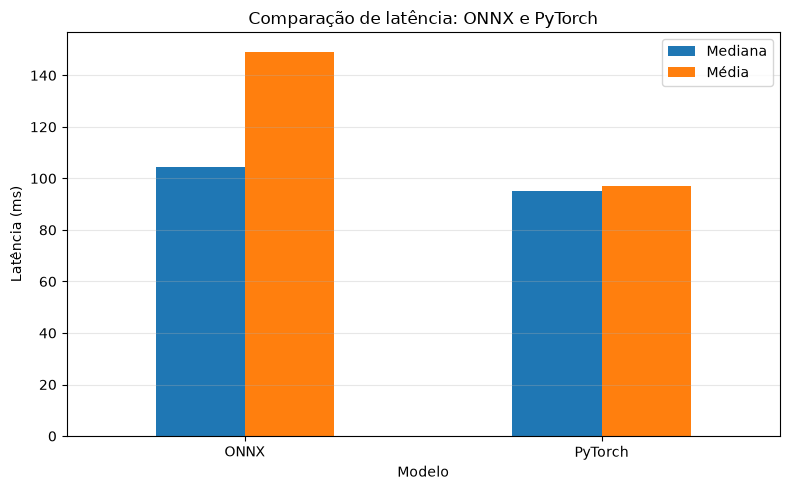

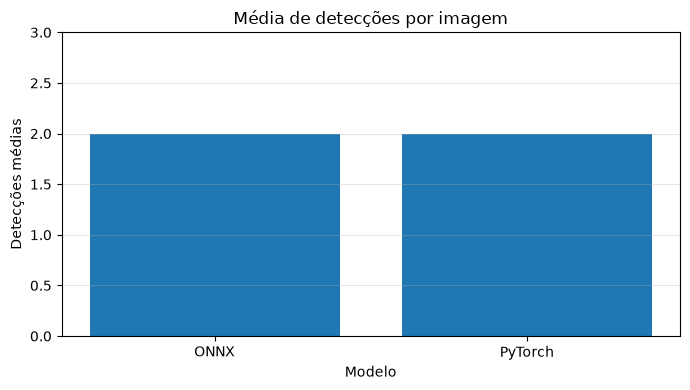


Visualização concluída.


In [2]:
# 12.7 - Visualização dos resultados computacionais

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

BASE = Path(
    r"C:\Users\barba\OneDrive\Documentos\TCC_limpo"
)

PASTA = BASE / "resultados_embarcados" / "exportacao"

print("Diretório:", PASTA)
print("Existe:", PASTA.exists())

if PASTA.exists():
    print("\nArquivos disponíveis:")
    for arquivo in sorted(PASTA.iterdir()):
        print("-", arquivo.name)

dados = pd.DataFrame({
    "modelo": ["ONNX", "PyTorch"],
    "latencia_mediana_ms": [104.61, 94.99],
    "latencia_media_ms": [149.23, 97.04],
    "deteccoes_medias": [2.0, 2.0]
})

display(dados)

fig, ax = plt.subplots(figsize=(8, 5))

dados.plot(
    x="modelo",
    y=["latencia_mediana_ms", "latencia_media_ms"],
    kind="bar",
    ax=ax
)

ax.set_title("Comparação de latência: ONNX e PyTorch")
ax.set_xlabel("Modelo")
ax.set_ylabel("Latência (ms)")
ax.legend(["Mediana", "Média"])
ax.grid(axis="y", alpha=0.3)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(7, 4))

ax.bar(
    dados["modelo"],
    dados["deteccoes_medias"]
)

ax.set_title("Média de detecções por imagem")
ax.set_xlabel("Modelo")
ax.set_ylabel("Detecções médias")
ax.set_ylim(0, 3)
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

print("\nVisualização concluída.")

### 12.8 Galeria qualitativa de detecções

A galeria permite inspecionar visualmente as caixas previstas pelo YOLO11s e identificar exemplos que merecem revisão, como orelhas parcialmente ocultas, marcações discretas ou possíveis falsas detecções. Para classificar formalmente uma predição como verdadeiro positivo, falso positivo ou falso negativo, é necessário compará-la com a anotação de referência, considerando classe e sobreposição das caixas. A simples visualização das imagens não substitui essa avaliação.

In [11]:
pip show torch torchvision ultralytics

Name: torch
Version: 2.13.0+cu130
Summary: Tensors and Dynamic neural networks in Python with strong GPU acceleration
Home-page: https://pytorch.org
Author: 
Author-email: PyTorch Team <packages@pytorch.org>
License-Expression: Apache-2.0 AND Apache-2.0 WITH LLVM-exception AND BSD-2-Clause AND BSD-3-Clause AND BSL-1.0 AND MIT
Location: c:\Users\barba\OneDrive\Documentos\TCC_limpo\.venv_yolo\Lib\site-packages
Requires: filelock, fsspec, jinja2, networkx, setuptools, sympy, typing-extensions
Required-by: torchvision, ultralytics, ultralytics-thop
---
Name: torchvision
Version: 0.28.0+cu130
Summary: image and video datasets and models for torch deep learning
Home-page: https://github.com/pytorch/vision
Author: PyTorch Core Team
Author-email: soumith@pytorch.org
License: BSD
Location: c:\Users\barba\OneDrive\Documentos\TCC_limpo\.venv_yolo\Lib\site-packages
Requires: numpy, pillow, torch
Required-by: ultralytics
---
Name: ultralytics
Version: 8.4.174
Summary: Ultralytics YOLO 🚀 for SOTA ob

In [3]:

# 12.8 - GALERIA QUALITATIVA YOLO11s (ONNX)
# Baixo consumo de energia

from pathlib import Path
import sys
import csv
import gc

BASE = Path(
    r"C:\Users\barba\OneDrive\Documentos\TCC_limpo"
)

SAIDA = BASE / "resultados_galeria_qualitativa"

ARQUIVOS_CSV = [
    SAIDA / "analise_qualitativa.csv",
    SAIDA / "analise_qualitativa_parcial.csv"
]

print("=" * 65)
print("DIAGNÓSTICO APÓS TRAVAMENTO")
print("=" * 65)

print("Python:", sys.executable)
print("Pasta de resultados existe:", SAIDA.is_dir())

print("\nArquivos encontrados:")

if SAIDA.is_dir():
    for arquivo in sorted(SAIDA.iterdir()):
        if arquivo.is_file():
            print(
                arquivo.name,
                "-",
                round(arquivo.stat().st_size / 1024, 2),
                "KB"
            )

CSV_RECUPERADO = next(
    (p for p in ARQUIVOS_CSV if p.is_file()),
    None
)

if CSV_RECUPERADO:

    with open(
        CSV_RECUPERADO,
        "r",
        encoding="utf-8-sig",
        newline=""
    ) as f:
        registros = list(csv.DictReader(f))

    print("\nCSV recuperado:", CSV_RECUPERADO.name)
    print("Imagens registradas:", len(registros))

    print("\nCategorias:")

    from collections import Counter

    contagem = Counter(
        r.get("categoria", "Sem categoria")
        for r in registros
    )

    for categoria, quantidade in contagem.items():
        print(f"  {categoria}: {quantidade}")

else:
    print("\nNenhum CSV de análise encontrado.")

#ver memória disponível

try:
    import psutil

    memoria = psutil.virtual_memory()

    print("\nMemória RAM:")
    print(
        "Total:",
        round(memoria.total / 1024**3, 2),
        "GB"
    )
    print(
        "Disponível:",
        round(memoria.available / 1024**3, 2),
        "GB"
    )

    virtual = psutil.swap_memory()

    print(
        "Arquivo de paginação / swap reportado:",
        round(virtual.total / 1024**3, 2),
        "GB"
    )

except ImportError:
    print("\npsutil não instalado; diagnóstico de RAM omitido.")

gc.collect()

print("\nDiagnóstico concluído.")


DIAGNÓSTICO APÓS TRAVAMENTO
Python: c:\Users\barba\OneDrive\Documentos\TCC_limpo\.venv_yolo\Scripts\python.exe
Pasta de resultados existe: True

Arquivos encontrados:
analise_qualitativa.csv - 3.41 KB
analise_qualitativa_parcial.csv - 3.43 KB
caso_dificil_01.png - 2425.79 KB
caso_dificil_02.png - 1600.2 KB
caso_dificil_03.png - 214.61 KB
caso_dificil_04.png - 625.15 KB
caso_dificil_05.png - 968.59 KB
caso_dificil_06.png - 1291.23 KB
caso_dificil_07.png - 1927.99 KB
caso_dificil_08.png - 1250.5 KB
frequencia_casos.png - 37.7 KB
metadados_galeria.json - 0.67 KB

CSV recuperado: analise_qualitativa.csv
Imagens registradas: 40

Categorias:
  Marcada não detectada: 6
  Normal não detectada: 3
  Detecção extra: 10
  Sem erro identificado: 21

Memória RAM:
Total: 7.71 GB
Disponível: 0.86 GB
Arquivo de paginação / swap reportado: 24.0 GB

Diagnóstico concluído.


## 13. Limitações e continuidade da pesquisa

Os experimentos mostram a viabilidade de treinar um detector YOLO11s para localizar orelhas e classificar a presença de marcações visíveis. Na comparação registrada, a configuração de 80 épocas apresentou o maior mAP entre as três opções examinadas. Entretanto, os resultados precisam ser interpretados com algumas limitações.

A primeira é a **ausência de identificação dos gatos nas fotografias**, que impediu a separação garantida por indivíduo. Outra questão é o **desbalanceamento das anotações**, com 259 orelhas marcadas e 673 normais. As diferenças de enquadramento, iluminação, visibilidade da orelha e tipo de marcação também podem afetar as predições, especialmente nos casos mais difíceis.

O estudo com V-JEPA 2 foi restrito à extração de embeddings de duas amostras e não estabeleceu um segundo classificador avaliado. Da mesma forma, os ensaios de portabilidade e inferência foram realizados em computador, sem validação em dispositivo embarcado ou em ambiente externo.

Como continuidade, propõe-se identificar os indivíduos para refazer a divisão dos dados, ampliar a avaliação por classe e por condição de captura, testar medidas de balanceamento e comparar modelos de diferentes tamanhos sob o mesmo protocolo. Uma etapa posterior poderia envolver um protótipo com câmera, medindo latência, consumo e confiabilidade em hardware real.

Por fim, o sistema deve ser entendido como uma **ferramenta de apoio à identificação visual de marcações**, e não como um método de confirmação clínica da esterilização.